# BT4012: Bitcoin Transaction Fraud Detection

**Student number: E1156285**

This working journal records data checks, model comparisons, chronological validation and submission generation. The current best screenshot-confirmed public score is **0.95471**, from the recency-weighted XGBoost/LightGBM ensemble with half-life four. **Section 38** records the eight reported public results, the weighted LightGBM submission decline and the student-selected fixed three-model test. Section 37 preserves the prior recency result and follow-up review; Section 31 preserves the earlier six-submission record. Earlier sections record the full development history.

The task is to rank future Bitcoin transactions by their estimated illicit probability. The competition metric is **ROC-AUC**, which is different from classification accuracy. Our target is to exceed the reported competition baseline of 0.96 ROC-AUC.

## How to use this notebook

- A **Markdown cell** explains a step. A **code cell** performs it.
- Select a code cell and press **Shift + Enter** to run it.
- Run cells in order. Variables remain available in the active Python kernel.
- Use **Restart Kernel and Run All Cells** to check that everything works from a fresh session.
- Select the project's `.venv` Python kernel and start from the folder containing `Data Set`.
- Save with **Command + S** on macOS.

We read the original competition files without changing them. Unknown labels are not legitimate labels. No external transaction labels are used.


**Latest review:** Section 26 records the student-selected feature-sampling experiment. It did not demonstrate a consistent improvement over the original XGBoost model. The next submission decision awaits the student’s review.


**New model review:** Section 27 records the student-selected pairwise ranking model, corrected stopping implementation, measured comparison, and experimental submission. Its Kaggle score is unknown; final selection awaits student review.


**Semi-supervised review:** Section 28 records the fixed all-row autoencoder experiment, its known-only comparison, executed standalone source, results and next proposed student decision. No Kaggle submission was made.


**Fraud-guided refinement:** Section 29 records the student-selected joint classification/reconstruction objective, four checks, trained-head diagnostic and verified standalone source. No Kaggle submission was made.


**Direct LabelSpreading experiment:** Section 30 records the student-selected feature-similarity mechanism, unknown-row comparison, four chronological checks and verified standalone source. No Kaggle submission was made.


**Current screenshot-confirmed public result (11 October 2026): 0.94701 for the Claude Section 28 low-regularisation XGBoost/LightGBM ensemble.** Section 31 records the screenshot-confirmed result, frozen submission reference, existing-component study and proposed next iteration. Earlier score statements describe historical reviews.


**LightGBM training length:** Section 32 records the student-selected 150/225/300-tree comparison, all 15 chronological checks and verified standalone source. No Kaggle upload was made.


**Default-library comparison:** Section 33 records the student-requested four default classifiers and their fixed equal blends, 15 chronological checks, verified predictions and standalone source. No Kaggle upload was made.


**Minimum leaf sizes:** Section 34 records the student-selected LightGBM 5/20/50-example comparison at 150 trees, all 15 chronological checks, tradeoffs and verified standalone source. No Kaggle upload was made.


**Equal leaf-size blend:** Section 35 records the student-selected 50:50 LightGBM 5/50 blend, all chronological results, tradeoffs and verified standalone source. No Kaggle upload was made.


**Claude candidate review:** Section 36 records the supplied recent7 and first-93-feature recipes, independent reproduction, existing chronological comparisons and validation limitations. New public scores remain unknown.


**Updated public best:** Section 39 records 0.95471, the local-ranking reversal, prepared recency files and a bounded next-day proposal. No new submission or final assessment selection was made by Codex.


**Latest public-result review:** Section 41 records half-life five at 0.95154, three at 0.95270 and the audited equal 3/4/5 average. Four remains the verified best at 0.95471; the average has no reported score.


**Shorter-training comparison:** Section 42 records the completed student-selected half-life-four 200/100 and 100/100 tests. Both have weaker checking means than the 200/150 reference. The public best remains 0.95471.


**Longer-training comparison:** Section 43 records the completed student-selected 300/150 and 200/225 tests at half-life four. The 300/150 recipe has small, mixed checking gains and is available for student review. Its public score is unknown; the verified best remains 0.95471.


## 1. Import libraries and locate the data

`Path` helps locate files. `pandas` reads CSV files into tables called DataFrames. `numpy` provides numerical operations.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "Data Set"
assert DATA_DIR.is_dir(), "Start Jupyter from the Kaggle project folder containing Data Set."
print("Data folder:", DATA_DIR)


Data folder: /Users/mlvlo/BT4012/Kaggle/Data Set


## 2. Load the four files

Training contains earlier transactions and some labels. Test contains later transactions requiring predictions. Edges describe payment dependencies. The submission template defines the required index and target columns.


In [2]:
train = pd.read_csv(DATA_DIR / "Train Data.csv")
test = pd.read_csv(DATA_DIR / "Test Data.csv")
edges = pd.read_csv(DATA_DIR / "TXS Edgelist.csv")
sample_submission = pd.read_csv(DATA_DIR / "Sample Submission" / "BT4012 Competition Submission.csv")

for name, table in [("Training", train), ("Test", test), ("Edges", edges), ("Submission template", sample_submission)]:
    print(f"{name}: {table.shape[0]:,} rows, {table.shape[1]} columns")


Training: 141,772 rows, 168 columns
Test: 15,329 rows, 168 columns
Edges: 234,355 rows, 2 columns
Submission template: 15,329 rows, 2 columns


## 3. View a few transactions

Each training row represents a transaction. `NaN` in label means its answer is unknown. Feature names are anonymized, so we do not assign invented meanings to them.


In [3]:
train[["txId", "time_step", "feat_1", "feat_2", "label"]].head()


,txId,time_step,feat_1,feat_2,label
0,230425980,1,-0.171469,-0.184668,NaN
1,5530458,1,-0.171484,-0.184668,NaN
2,232022460,1,-0.172107,-0.184668,NaN
3,232438397,1,0.163054,1.963790,0.0
4,230460314,1,1.011523,-0.081127,NaN


## 4. Separate known answers from unknown answers

`1` means illicit. `0` means licit. Only known labels are used as supervised training targets. This cell prepares separate tables; it does not train a model.


In [4]:
labels = pd.to_numeric(train["label"], errors="coerce")
assert labels.dropna().isin([0, 1]).all(), "Unexpected label values."
labeled = train.loc[labels.notna()].copy()
labeled["label"] = labels.loc[labels.notna()].astype(int)
unlabeled = train.loc[labels.isna()].copy()

print("Licit:", int((labeled["label"] == 0).sum()))
print("Illicit:", int((labeled["label"] == 1).sum()))
print("Unknown:", len(unlabeled))
print(f"Illicit share among known labels: {labeled['label'].mean():.2%}")


Licit: 27591
Illicit: 3644
Unknown: 110537
Illicit share among known labels: 11.67%


## 5. Check the features, timeline, and submission IDs

The final evaluation is on later periods. Our validation will therefore use earlier periods to train and later periods to check predictions. `txId` joins graph connections; `index` identifies submission rows.


In [5]:
FEATURE_COLUMNS = [f"feat_{i}" for i in range(1, 166)]
assert all(column in train.columns and column in test.columns for column in FEATURE_COLUMNS)
assert train["txId"].is_unique and test["txId"].is_unique
assert set(train["txId"]).isdisjoint(set(test["txId"]))
assert train["time_step"].max() < test["time_step"].min()
assert sample_submission["index"].equals(test["index"])
assert not train[FEATURE_COLUMNS].isna().any().any()
assert not test[FEATURE_COLUMNS].isna().any().any()
assert np.isfinite(train[FEATURE_COLUMNS].to_numpy()).all()
assert np.isfinite(test[FEATURE_COLUMNS].to_numpy()).all()

print(f"Training time steps: {train.time_step.min()}–{train.time_step.max()}")
print(f"Test time steps: {test.time_step.min()}–{test.time_step.max()}")
print("Feature columns:", len(FEATURE_COLUMNS))
print("Basic checks passed. No model has been trained yet.")


Training time steps: 1–35
Test time steps: 36–49
Feature columns: 165
Basic checks passed. No model has been trained yet.


## 6. Explore labels over time

### What are we doing?

Count licit, illicit, and unknown transactions in each time step.
Calculate the illicit proportion using only transactions with known labels.

We want to investigate whether the mix of licit and illicit examples stay similar over time. We group transactions froms the same period into one group. Then, calculate the counts for each group. Instead of looking at 141,772 transactions individually, we create a table with one row for each of the 35 time steps.

This is part of **exploratory data analysis (EDA)**, which means examining the data to understand its patterns before building a prediction model. We are not training a model in this step.

### Why are we doing this?

The training data covers time steps **1–35**, while the test data covers later time steps **36–49**.

Our model must therefore learn from earlier transactions and make predictions about later ones. We want to check whether the proportion of illicit transactions among known labels changes over time. These changes help us plan a realistic way to test the model.

### What does each column mean?

| Column | Meaning |
|---|---|
| `total_transactions` | All transactions in that period, including those with unknown labels |
| `known_labels` | Transactions whose labels are known: licit (`0`) or illicit (`1`) |
| `illicit_transactions` | Transactions labeled illicit (`1`) |
| `licit_transactions` | Transactions labeled licit (`0`) |
| `unknown_transactions` | Transactions whose labels are missing |
| `illicit_share_of_known` | The fraction of known labels that are illicit |

The last column is displayed as a decimal. For example, **0.12 means 12%**.

### How do we read the results?

For **time step 1**:

- There are **7,880** transactions in total.
- **2,147** have known labels: **17 illicit** and **2,130 licit**.
- **5,733** have unknown labels.
- The illicit proportion among known labels is **17 ÷ 2,147 = 0.007918**, or approximately **0.79%**.

This means roughly 8 out of every 1,000 transactions with known labels in this period are illicit.

**Unknown does not mean licit.** We cannot use this percentage to describe all transactions in the period because the unlabeled transactions may contain both licit and illicit cases.

### What have we learned?

The proportion of illicit transactions among known labels changes substantially over time.

| Time step | Illicit transactions | Known labels | Illicit percentage among known labels |
|---|---:|---:|---:|
| 1 | 17 | 2,147 | 0.79% |
| 5 | 8 | 1,882 | 0.43% |
| 9 | 248 | 778 | 31.88% |
| 13 | 291 | 809 | 35.97% |
| 35 | 182 | 1,341 | 13.57% |

These differences may reflect changes in transaction activity, changes in which transactions received labels, or both. This table alone does not tell us the cause.

### What does this mean for our model?

We need to determine whether a model trained on earlier periods can predict later periods accurately. Testing across several chronological splits will help us assess whether its performance is consistent when the mix of labeled transactions changes.

In [6]:
timeline = (
    train.groupby("time_step")
    .agg(
        total_transactions=("txId", "size"),
        known_labels=("label", "count"),
        illicit_transactions=("label", lambda s: (s == 1).sum()),
        licit_transactions=("label", lambda s: (s == 0).sum()),
    )
)

timeline["unknown_transactions"] = (
    timeline["total_transactions"] - timeline["known_labels"]
)

timeline["illicit_share_of_known"] = (
    timeline["illicit_transactions"]
    / timeline["known_labels"].replace(0, np.nan)
)

display(timeline)

,total_transactions,known_labels,illicit_transactions,licit_transactions,unknown_transactions,illicit_share_of_known
time_step,,,,,,
1,7880,2147,17,2130,5733,0.007918
2,4544,1117,18,1099,3427,0.016115
3,6621,1279,11,1268,5342,0.008600
4,5693,1440,30,1410,4253,0.020833
5,6803,1882,8,1874,4921,0.004251
6,4328,485,5,480,3843,0.010309
7,6048,1203,102,1101,4845,0.084788
8,4457,1165,67,1098,3292,0.057511
9,4996,778,248,530,4218,0.318766


## 7. Visualize transactions and labels over time

### What are we doing?

We create three charts using the summary table from the previous step:

1. **Transaction counts:** how many transactions are licit, illicit, or unknown in each period.
2. **Illicit percentage among known labels:** how the mix of labeled transactions changes.
3. **Label coverage:** what percentage of all transactions have a known answer.

### Why do we need three charts?

Each chart answers a different question.

**The Transaction Counts chart shows the amount of data available.** Its stacked bars combine licit, illicit, and unknown transactions. Each bar’s total height represents all transactions in that period.

**The Illicit % Among Known Labels chart shows the illicit percentage among labeled transactions.** For example, 20% means that one in five transactions with a known label is illicit. It does not describe the transactions with unknown labels.

**The Label Coverage chart shows how much of the data is labeled.** We calculate:

**Label coverage = Known labels ÷ Total transactions × 100**

For example, 25% coverage means we know the answers for one-quarter of the transactions in that period.

### How does the code work?

1. Import `matplotlib.pyplot`, a library for drawing charts.
2. Calculate label coverage and convert both proportions into percentages.
3. Create three charts arranged vertically.
4. Draw transaction counts as stacked bars and percentages as lines.
5. Add titles and axis labels so the charts are easy to interpret.

The code reads the existing `timeline` table. It does not change the original CSV files.

### How should we interpret the charts?

A rise in the illicit percentage among known labels does not automatically mean illicit activity increased across the whole dataset. The transactions that received labels may also have changed.

These charts help us choose useful periods for validation. We will train on earlier periods and check predictions against known answers in later periods.

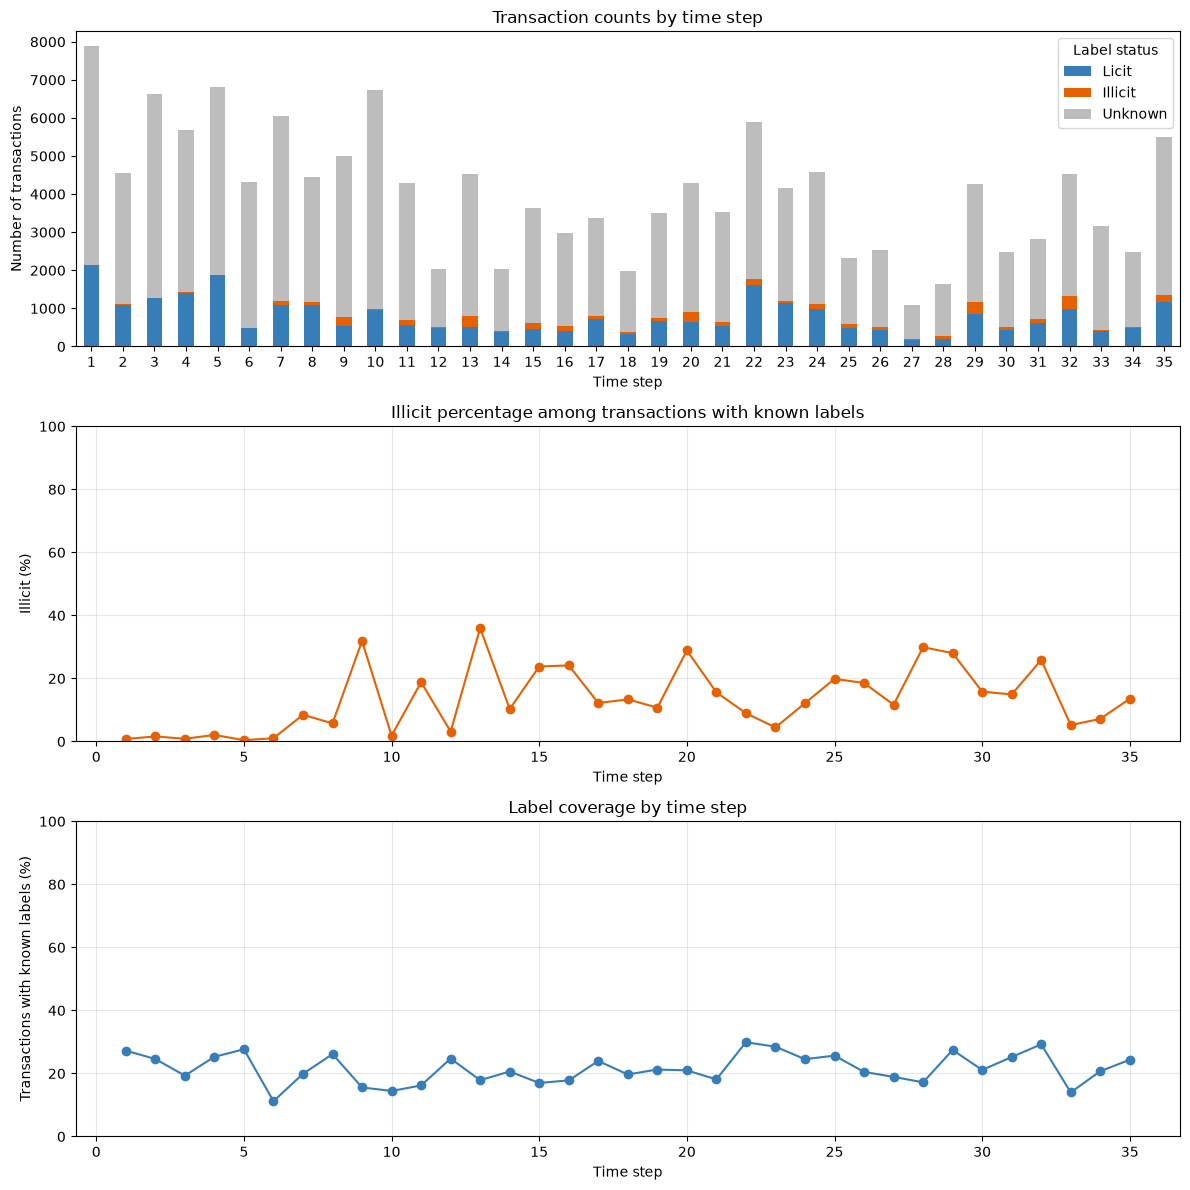

In [7]:
import matplotlib.pyplot as plt

# Convert proportions into percentages for easier reading.
illicit_percentage = timeline["illicit_share_of_known"] * 100

label_coverage = (
    timeline["known_labels"]
    / timeline["total_transactions"].replace(0, np.nan)
) * 100

fig, axes = plt.subplots(3, 1, figsize=(12, 12))

# Chart 1: All transactions, separated by label status.
counts = timeline[
    ["licit_transactions", "illicit_transactions", "unknown_transactions"]
].copy()
counts.columns = ["Licit", "Illicit", "Unknown"]

counts.plot.bar(
    stacked=True,
    ax=axes[0],
    color=["#377eb8", "#e66101", "#bdbdbd"],
    rot=0,
)
axes[0].set_title("Transaction counts by time step")
axes[0].set_xlabel("Time step")
axes[0].set_ylabel("Number of transactions")
axes[0].legend(title="Label status")

# Chart 2: Illicit percentage among known labels.
axes[1].plot(
    timeline.index,
    illicit_percentage,
    marker="o",
    color="#e66101",
)
axes[1].set_title("Illicit percentage among transactions with known labels")
axes[1].set_xlabel("Time step")
axes[1].set_ylabel("Illicit (%)")
axes[1].set_ylim(0, 100)
axes[1].grid(alpha=0.3)

# Chart 3: Percentage of all transactions with known labels.
axes[2].plot(
    timeline.index,
    label_coverage,
    marker="o",
    color="#377eb8",
)
axes[2].set_title("Label coverage by time step")
axes[2].set_xlabel("Time step")
axes[2].set_ylabel("Transactions with known labels (%)")
axes[2].set_ylim(0, 100)
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### What do these charts tell us?

**1. Most transactions have unknown labels.**

The grey portion dominates the stacked bars. This means that, in every period, most transactions have no known answer.

These unknown transactions may be useful for studying patterns and graph connections, but we cannot treat them as confirmed licit or illicit transactions.

The total height of each bar also changes. Some periods contain many more transactions than others.

**2. The illicit percentage among known labels changes substantially.**

The orange line is low in the first few periods, then rises and falls noticeably. For example, the illicit percentage among known labels is approximately:

- **0.43% at time step 5**
- **31.88% at time step 9**
- **35.97% at time step 13**
- **13.57% at time step 35**

This tells us that the mix of labeled examples changes over time. A model must handle these differences when predicting later periods.

These percentages apply only to transactions with known labels. They do not establish the illicit percentage among all transactions.

**3. Label coverage changes over time too.**

The blue line shows that roughly **11%–30%** of transactions have known labels in each period.

For example, 20% coverage means we know the answers for about one in five transactions. The other four have unknown labels.

We do not know whether the labeled transactions represent the unlabeled transactions fairly. Changes in the illicit percentage could reflect changes in activity, changes in which transactions were labeled, or both.

### Next Step

We should evaluate the model using time order: learning from earlier periods and check predictions against known answers in later periods.

We will also check performance across more than one chronological split. This will help us see whether the model works consistently instead of performing well in just one selected period.

These charts describe the data; they do not yet show model performance.

## 8. Create chronological training and validation sets

### What are we doing?

We divide transactions with known labels into two groups:

- **Training set: time steps 1–28.** The model will learn from these examples.
- **Validation set: time steps 29–35.** We will hide these answers from the model during training, ask it to make predictions, and compare its predictions with the known answers.

Think of the training set as study material and the validation set as a practice exam.

The actual competition test set, covering time steps 36–49, remains separate.

### Why split by time?

The assignment asks us to predict future transactions. Training on earlier periods and validating on later periods imitates that situation.

A random split would mix earlier and later transactions. It would answer a different question: how well the model predicts other examples from a mixture of periods.

We choose time step 28 as an initial cutoff, leaving seven later periods for validation. This is a starting choice, not a proven best split. We will check other chronological splits later.

### Which transactions do we include?

We use only the `labeled` table, where every transaction has a known answer:

- `0` means licit.
- `1` means illicit.

Unknown transactions remain available separately for possible later analysis. They are not assigned invented labels.

### What do X and y mean?

For each group, we separate the clues from the answers:

| Variable | Meaning |
|---|---|
| `X_train` | The 165 numerical features the model learns from |
| `y_train` | The known answers for the training examples |
| `X_valid` | The 165 numerical features used for validation predictions |
| `y_valid` | The validation answers used to evaluate those predictions |

For this first model, we use only `feat_1` to `feat_165`. Transaction IDs identify records, and time steps determine the split. We have not added new graph features yet.

### What does the code check?

The code checks that:

1. Both groups contain transactions.
2. Every training period occurs before every validation period.
3. No transaction appears in both groups.
4. Both groups contain licit and illicit examples, which are needed to calculate ROC-AUC.

The summary shows the number of transactions and the illicit percentage in each group. Different percentages are possible because the mix of labeled transactions changes over time.

### Have we trained a model yet?

No. This step prepares the inputs and answers. Model training happens next.

The validation answers must not be used to train the model or fit preprocessing steps. They are reserved for checking predictions.

In [8]:
TRAIN_END_STEP = 28

# Split only transactions with known labels.
training_rows = labeled.loc[
    labeled["time_step"] <= TRAIN_END_STEP
].copy()

validation_rows = labeled.loc[
    labeled["time_step"] > TRAIN_END_STEP
].copy()

# Check that this is a valid chronological split.
assert not training_rows.empty
assert not validation_rows.empty

assert (
    training_rows["time_step"].max()
    < validation_rows["time_step"].min()
)

assert set(training_rows["txId"]).isdisjoint(
    set(validation_rows["txId"])
)

assert set(training_rows["label"]) == {0, 1}
assert set(validation_rows["label"]) == {0, 1}

# Separate the numerical clues (X) from the answers (y).
X_train = training_rows[FEATURE_COLUMNS].copy()
y_train = training_rows["label"].copy()

X_valid = validation_rows[FEATURE_COLUMNS].copy()
y_valid = validation_rows["label"].copy()

# Display the size and class balance of each group.
split_summary = pd.DataFrame([
    {
        "set": name,
        "first_time_step": rows["time_step"].min(),
        "last_time_step": rows["time_step"].max(),
        "transactions": len(rows),
        "licit": int((rows["label"] == 0).sum()),
        "illicit": int((rows["label"] == 1).sum()),
        "illicit_percentage": rows["label"].mean() * 100,
    }
    for name, rows in [
        ("Training", training_rows),
        ("Validation", validation_rows),
    ]
]).set_index("set")

display(split_summary.round({"illicit_percentage": 2}))

,first_time_step,last_time_step,transactions,licit,illicit,illicit_percentage
set,,,,,,
Training,1,28,25207,22665,2542,10.08
Validation,29,35,6028,4926,1102,18.28


## 9. Training

### 9.1. Model: Logistic Regression Model

#### What are we doing?

We train a model using the labeled transactions from time steps **1–28**. We then ask it to predict the transactions from time steps **29–35**.

This is the first step where a model actually learns from the data.

#### What is logistic regression?

Logistic regression combines numerical clues to estimate the probability that a transaction is illicit.

During training, it learns a weight for each feature. These weights determine how the features influence its prediction. It then converts the combined score into a value between zero and one.

For example, a prediction of `0.85` means the model assigns an 85% probability of the transaction being illicit. We still need to evaluate how reliable its predictions are.

#### Why start with this model?

Logistic regression is a relatively simple model covered in the lectures. It provides a useful reference for checking whether more complicated models improve performance.

This is **our first reference model**. It is not necessarily the instructor's official baseline, whose performance we still need to verify.

#### Why scale the features?

The supplied features are already described as normalized. We nevertheless apply standard scaling within this model's training pipeline to put the features on comparable scales.

Scaling subtracts each feature's training-set mean and divides by its training-set standard deviation. This helps optimization and makes the regularization penalty act on a more comparable scale across features.

The scaler learns its settings from **training data only**. It applies those same settings to validation data without learning from the validation set.

#### How do we limit overfitting?

We use L2 regularization, which discourages excessively large feature weights.

The setting `C` controls regularization strength:

- Smaller `C` means stronger regularization.
- Larger `C` means weaker regularization.

We start with `C=1.0`. This is an initial setting, not a tuned result.

We initially use the natural class balance without extra class weighting. Later experiments can check whether weighting improves validation performance.

#### What does the pipeline do?

A pipeline combines scaling and model training into one sequence:

1. Learn the scaling settings from the training features.
2. Scale those features and train logistic regression.
3. Apply the same scaling to validation features.
4. Generate validation predictions.

Only `X_train` and `y_train` are used for learning. The validation answers are kept aside for evaluation.

#### How will we evaluate it?

Our main metric is **ROC-AUC**, which is the competition's evaluation metric.

AUC measures how well the model ranks illicit transactions above licit transactions:

- **0.5:** random ranking.
- **1.0:** perfect separation.

AUC is not the percentage of transactions classified correctly.

We also report precision, recall, and F1 using a starting threshold of **0.5**:

- **Precision:** Of the transactions flagged as illicit, how many are actually illicit?
- **Recall:** Of all illicit transactions, how many did we catch?
- **F1:** A combined measure of precision and recall.

The threshold converts probabilities into decisions for these additional metrics. It does not change the probabilities used to calculate AUC.

#### What will the results tell us?

The results show how this first model performs on the later validation periods. They provide a reference for subsequent experiments.

A successful run does not guarantee a strong model. We need to examine the actual scores, check other chronological splits, and compare alternative approaches.

We are not generating a Kaggle submission in this step.

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

# Scaling and model fitting happen together.
baseline_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        C=1.0,
        solver="lbfgs",
        max_iter=2000,
        class_weight=None,
    )),
])

# Learn only from the earlier training periods.
baseline_model.fit(X_train, y_train)

# Select the probability column for label 1: illicit.
illicit_column = list(
    baseline_model.named_steps["classifier"].classes_
).index(1)

valid_probabilities = baseline_model.predict_proba(
    X_valid
)[:, illicit_column]

# AUC uses probabilities; the other metrics use decisions.
THRESHOLD = 0.5
valid_predictions = (
    valid_probabilities >= THRESHOLD
).astype(int)

baseline_results = pd.DataFrame([{
    "model": "Logistic regression",
    "validation_auc": roc_auc_score(
        y_valid, valid_probabilities
    ),
    "precision_at_0.5": precision_score(
        y_valid, valid_predictions, zero_division=0
    ),
    "recall_at_0.5": recall_score(
        y_valid, valid_predictions, zero_division=0
    ),
    "f1_at_0.5": f1_score(
        y_valid, valid_predictions, zero_division=0
    ),
}]).set_index("model")

display(baseline_results.round(4))

# Rows are actual labels; columns are predicted labels.
confusion = pd.DataFrame(
    confusion_matrix(
        y_valid, valid_predictions, labels=[0, 1]
    ),
    index=["Actual licit", "Actual illicit"],
    columns=["Predicted licit", "Predicted illicit"],
)

display(confusion)

,validation_auc,precision_at_0.5,recall_at_0.5,f1_at_0.5
model,,,,
Logistic regression,0.9031,0.5199,0.7359,0.6093


,Predicted licit,Predicted illicit
Actual licit,4177,749
Actual illicit,291,811


### 9.2. Model: Histogram Gradient Boosting

#### Why are we trying another model?

Our first model, logistic regression, achieved a validation ROC-AUC of approximately **0.9031**. The competition baseline is **0.96 ROC-AUC**, so we want a model that ranks illicit transactions more effectively.

ROC-AUC measures how well the model places illicit transactions above legitimate transactions in its risk scores. It does **not** mean the percentage of transactions classified correctly.

#### How does this model work?

Histogram Gradient Boosting combines many small decision trees.

A decision tree asks a sequence of questions about the transaction’s features, such as whether a feature is above or below a certain value. Combining these questions allows the model to recognise patterns involving several features together.

The model builds trees one after another. Each new tree helps improve the predictions made by the trees already built. “Histogram” means that numerical values are grouped into bins to make training faster.

The feature names are anonymised, so we can learn useful numerical patterns without claiming to know what each feature represents.

#### What data are we using?

We use the same 165 features and the same chronological split as our first model:

- **Training:** transactions with known labels from time steps 1–28.
- **Validation:** transactions with known labels from time steps 29–35.

Keeping the split unchanged makes the comparison fair. Unknown labels are excluded from supervised training because we do not know their correct answers.

We do not include transaction IDs as predictive features.

#### What do the settings mean?

- `max_iter=400`: allow up to 400 rounds of building trees.
- `learning_rate=0.05`: make a small adjustment in each round.
- `max_leaf_nodes=15`: limit each tree to 15 final branches to control complexity.
- `min_samples_leaf=30`: require at least 30 training examples in each final branch, reducing the chance of learning patterns from only a handful of transactions.
- `l2_regularization=10`: discourage overly extreme predictions within individual trees.
- `early_stopping=True`: stop adding trees when an internal check stops improving.
- `validation_fraction=0.1`: reserve 10% of the training portion for that internal check. This does not use our separate validation transactions from steps 29–35.
- `random_state=42`: make the random choices repeatable.

#### How will we evaluate it?

The model produces a probability of being illicit for each validation transaction. We use those probabilities to calculate **ROC-AUC**, our main competition metric.

We also calculate precision, recall and F1 using a probability threshold of 0.5. These show what happens when we turn the probabilities into illicit or licit decisions.

A ROC-AUC above 0.96 on this validation split is encouraging. We still need to check other time periods because strong performance on one period does not guarantee strong performance on future transactions.

In [10]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

boosted_model = HistGradientBoostingClassifier(
    max_iter=400,
    learning_rate=0.05,
    max_leaf_nodes=15,
    min_samples_leaf=30,
    l2_regularization=10,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=RANDOM_SEED,
)

# Learn from the earlier transactions with known labels.
boosted_model.fit(X_train, y_train)

# Predict illicit probabilities for the later validation transactions.
illicit_column = list(boosted_model.classes_).index(1)
boosted_valid_probabilities = boosted_model.predict_proba(
    X_valid
)[:, illicit_column]

# Use 0.5 only for the classification metrics below.
boosted_valid_predictions = (
    boosted_valid_probabilities >= 0.5
).astype(int)

boosted_results = pd.DataFrame(
    {
        "validation_auc": [
            roc_auc_score(y_valid, boosted_valid_probabilities)
        ],
        "precision_at_0.5": [
            precision_score(
                y_valid, boosted_valid_predictions, zero_division=0
            )
        ],
        "recall_at_0.5": [
            recall_score(
                y_valid, boosted_valid_predictions, zero_division=0
            )
        ],
        "f1_at_0.5": [
            f1_score(
                y_valid, boosted_valid_predictions, zero_division=0
            )
        ],
    },
    index=pd.Index(["Histogram gradient boosting"], name="model"),
)

display(pd.concat([baseline_results, boosted_results]).round(4))

display(
    pd.DataFrame(
        confusion_matrix(y_valid, boosted_valid_predictions, labels=[0, 1]),
        index=["Actual licit", "Actual illicit"],
        columns=["Predicted licit", "Predicted illicit"],
    )
)

print("Training rounds completed:", boosted_model.n_iter_)

,validation_auc,precision_at_0.5,recall_at_0.5,f1_at_0.5
model,,,,
Logistic regression,0.9031,0.5199,0.7359,0.6093
Histogram gradient boosting,0.9950,0.9723,0.7976,0.8764


,Predicted licit,Predicted illicit
Actual licit,4901,25
Actual illicit,223,879


Training rounds completed: 385


### 9.3. Train Random Forest

#### What is Random Forest?

Random Forest combines many decision trees. Think of it as a panel of trees, each offering its own assessment of whether a transaction is illicit.

Each tree learns from a randomly resampled version of our training transactions. Some transactions may appear several times, while others may be left out of that tree’s training sample. At each decision point, the tree considers a random selection of features.

The model averages the illicit probabilities from all trees to produce its final prediction.

#### Why are we trying this model?

Random Forest can recognise patterns involving several features together. A transaction may be suspicious because of a particular combination of values, even if no individual feature is suspicious on its own.

Averaging many trees also reduces dependence on the behaviour of any single tree.

This gives us a useful comparison with our previous models:

- Logistic regression provides a simple starting benchmark.
- Histogram Gradient Boosting builds trees successively to improve the combined prediction.
- Random Forest trains trees independently and averages their predictions.

#### What data does it use?

We keep the same 165 features and chronological split:

- **Training:** known labels from time steps 1–28.
- **Validation:** known labels from time steps 29–35.

Keeping the data unchanged makes the model comparison fair.

#### What do the settings mean?

- `n_estimators=400`: build 400 decision trees.
- `max_features=0.7`: consider approximately 70% of the features at each decision point.
- `min_samples_leaf=2`: require at least two training examples in each final branch, avoiding branches supported by only one transaction.
- `bootstrap=True`: give each tree a randomly resampled set of training transactions.
- `n_jobs=4`: use up to four processor workers.
- `random_state=42`: make the random choices repeatable.

These are starting settings rather than proven optimal choices.

#### How do we evaluate it?

We calculate ROC-AUC from the predicted illicit probabilities. This is our main metric because it matches the competition.

We also calculate precision, recall and F1 using a probability threshold of 0.5. These help explain how the model behaves when its probabilities are converted into licit or illicit decisions.

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

random_forest_model = RandomForestClassifier(
    n_estimators=400,
    max_features=0.7,
    min_samples_leaf=2,
    bootstrap=True,
    n_jobs=4,
    random_state=RANDOM_SEED,
)

random_forest_model.fit(X_train, y_train)

illicit_column = list(random_forest_model.classes_).index(1)
rf_valid_probabilities = random_forest_model.predict_proba(
    X_valid
)[:, illicit_column]

rf_valid_predictions = (rf_valid_probabilities >= 0.5).astype(int)

rf_results = pd.DataFrame(
    {
        "validation_auc": [
            roc_auc_score(y_valid, rf_valid_probabilities)
        ],
        "precision_at_0.5": [
            precision_score(y_valid, rf_valid_predictions, zero_division=0)
        ],
        "recall_at_0.5": [
            recall_score(y_valid, rf_valid_predictions, zero_division=0)
        ],
        "f1_at_0.5": [
            f1_score(y_valid, rf_valid_predictions, zero_division=0)
        ],
    },
    index=pd.Index(["Random Forest"], name="model"),
)

display(rf_results.round(4))

display(pd.DataFrame(
    confusion_matrix(y_valid, rf_valid_predictions, labels=[0, 1]),
    index=["Actual licit", "Actual illicit"],
    columns=["Predicted licit", "Predicted illicit"],
))

print("Number of trees:", len(random_forest_model.estimators_))

,validation_auc,precision_at_0.5,recall_at_0.5,f1_at_0.5
model,,,,
Random Forest,0.9766,0.9819,0.5898,0.737


,Predicted licit,Predicted illicit
Actual licit,4914,12
Actual illicit,452,650


Number of trees: 400


### 9.4. Train Extra Trees

#### What is Extra Trees?

Extra Trees stands for “Extremely Randomised Trees.”

Like Random Forest, it combines many decision trees and averages their predicted illicit probabilities.

The main difference is how it chooses the numerical cut-off points in a tree’s questions. Extra Trees generates random cut-off candidates and selects a useful split from them. This introduces additional randomness into the trees.

In our configuration, each tree uses the full training portion rather than a randomly resampled set of transactions.

#### Why are we trying this model?

The additional randomness can make the trees less alike. Averaging their predictions may therefore help the model generalise to transactions it has not seen.

Training can also be faster because it does not search as thoroughly for each cut-off point.

The purpose of this comparison is to investigate whether additional randomness helps on our transaction dataset. It is not automatically better than Random Forest or gradient boosting; we must compare their validation results.

#### What data does it use?

We use the same 165 features and chronological split:

- **Training:** known labels from time steps 1–28.
- **Validation:** known labels from time steps 29–35.

Unknown labels are excluded from supervised training because we do not know their correct answers.

#### What do the settings mean?

- `n_estimators=500`: build 500 decision trees.
- `max_features=0.8`: consider approximately 80% of the features at each decision point.
- `min_samples_leaf=2`: require at least two training examples in each final branch.
- `bootstrap=False`: use the full training portion for each tree without resampling transactions.
- `n_jobs=4`: use up to four processor workers.
- `random_state=42`: make the random choices repeatable.

These are starting settings rather than proven optimal choices.

#### How do we evaluate it?

We calculate ROC-AUC from the predicted illicit probabilities, then calculate precision, recall and F1 at a probability threshold of 0.5.

This gives us a fourth model to compare. We will use ROC-AUC as the main selection metric and check the strongest candidates across additional time periods before choosing our final model.

In [12]:
from sklearn.ensemble import ExtraTreesClassifier

extra_trees_model = ExtraTreesClassifier(
    n_estimators=500,
    max_features=0.8,
    min_samples_leaf=2,
    bootstrap=False,
    n_jobs=4,
    random_state=RANDOM_SEED,
)

extra_trees_model.fit(X_train, y_train)

illicit_column = list(extra_trees_model.classes_).index(1)
et_valid_probabilities = extra_trees_model.predict_proba(
    X_valid
)[:, illicit_column]

et_valid_predictions = (et_valid_probabilities >= 0.5).astype(int)

et_results = pd.DataFrame(
    {
        "validation_auc": [
            roc_auc_score(y_valid, et_valid_probabilities)
        ],
        "precision_at_0.5": [
            precision_score(y_valid, et_valid_predictions, zero_division=0)
        ],
        "recall_at_0.5": [
            recall_score(y_valid, et_valid_predictions, zero_division=0)
        ],
        "f1_at_0.5": [
            f1_score(y_valid, et_valid_predictions, zero_division=0)
        ],
    },
    index=pd.Index(["Extra Trees"], name="model"),
)

display(et_results.round(4))

display(pd.DataFrame(
    confusion_matrix(y_valid, et_valid_predictions, labels=[0, 1]),
    index=["Actual licit", "Actual illicit"],
    columns=["Predicted licit", "Predicted illicit"],
))

print("Number of trees:", len(extra_trees_model.estimators_))

,validation_auc,precision_at_0.5,recall_at_0.5,f1_at_0.5
model,,,,
Extra Trees,0.9946,0.9867,0.9419,0.9638


,Predicted licit,Predicted illicit
Actual licit,4912,14
Actual illicit,64,1038


Number of trees: 500


## 10. Interpret the initial model comparison

We trained four models using known labels from time steps 1–28 and evaluated them on the same validation transactions from steps 29–35.

The table is sorted by **ROC-AUC**, the competition’s scoring metric.

Precision = how many flagged are ACTUALLY illicit; N_correctly_flagged / N_flagged

Recall = how many illicit are flagged; N_correctly_flagged / N_illicit

### Histogram Gradient Boosting

- **ROC-AUC: 0.9950** — the highest score in this comparison.
- **Precision: 97.23%** — approximately 97 out of every 100 transactions it flagged were actually illicit.
- **Recall: 79.76%** — it caught approximately 80 out of every 100 illicit transactions.
- **F1: 0.8764**.

This model ranks transactions very effectively. However, at the 0.5 threshold, it misses approximately 20% of illicit transactions.

### Extra Trees

- **ROC-AUC: 0.9946** — very close to Histogram Gradient Boosting.
- **Precision: 98.67%** — approximately 99 out of every 100 transactions it flagged were actually illicit.
- **Recall: 94.19%** — it caught approximately 94 out of every 100 illicit transactions.
- **F1: 0.9638** — the highest F1 score in this comparison.

Extra Trees achieves both high precision and high recall at the 0.5 threshold. It catches more illicit transactions than Histogram Gradient Boosting while also having a smaller proportion of false alarms among its flagged transactions.

### Random Forest

- **ROC-AUC: 0.9766** — exceeds the 0.96 baseline on this validation split.
- **Precision: 98.19%**.
- **Recall: 58.98%**.
- **F1: 0.7370**.

Its flagged transactions are usually genuinely illicit, but it misses approximately 41% of illicit transactions at the 0.5 threshold.

### Logistic regression

- **ROC-AUC: 0.9031** — the lowest score in this comparison.
- **Precision: 51.99%**.
- **Recall: 73.59%**.
- **F1: 0.6093**.

It catches approximately 74% of illicit transactions, but only about half of its flagged transactions are actually illicit. The tree models perform better on this validation split.

### Why can one model have higher ROC-AUC but lower recall?

ROC-AUC evaluates how well the model orders transactions by risk across different thresholds.

Precision, recall and F1 in this table describe decisions made at just one threshold: 0.5.

A model can rank transactions correctly while assigning many illicit transactions probabilities below 0.5. Those transactions count as missed cases at that threshold, even though their scores may still be higher than those of legitimate transactions.

Therefore, a ROC-AUC of 0.9950 does not mean 99.5% classification accuracy.

### Which model should we choose?

Histogram Gradient Boosting is currently the leading candidate for the competition because it has the highest ROC-AUC.

However, its advantage over Extra Trees is only **0.0004**, and this single split does not establish that it will perform better on future transactions.

We should evaluate both models across additional chronological splits before choosing the final model. After selection, we will retrain it using all known labels from steps 1–35 and generate illicit probabilities for the test transactions from steps 36–49.

**Journal note:** This describes our first comparison. Section 15 records the later ensemble and actual public scores.


In [13]:
model_comparison = pd.concat([
    baseline_results,
    boosted_results,
    rf_results,
    et_results,
]).sort_values("validation_auc", ascending=False)

display(model_comparison.round(4))

,validation_auc,precision_at_0.5,recall_at_0.5,f1_at_0.5
model,,,,
Histogram gradient boosting,0.9950,0.9723,0.7976,0.8764
Extra Trees,0.9946,0.9867,0.9419,0.9638
Random Forest,0.9766,0.9819,0.5898,0.7370
Logistic regression,0.9031,0.5199,0.7359,0.6093


## 12. Compare the strongest models across time

### Why are we doing this?

Our first comparison showed that Histogram Gradient Boosting and Extra Trees performed well on time steps 29–35.

Before choosing a model, we want to check whether they also perform well in other periods. This matters because the assignment asks us to predict future transactions, whose patterns may differ from the past.

By performing this temporal comparison, we are sort of doing a back-test to identify which model is truly better at predicting future transactions, kind of like a **practice exam**.

### How do the "back-testing" work?

For each exam, the model learns from earlier transactions and predicts later transactions.

| Practice exam | Transactions used for learning | Transactions used for checking |
|---|---|---|
| Earlier period | Time steps 1–20 | Time steps 21–27 |
| Middle period | Time steps 1–24 | Time steps 25–31 |
| Latest period | Time steps 1–28 | Time steps 29–35 |

For every exam, we start with a **fresh model** using the same settings. It does not carry over what a previous model learned.

Both models receive the same training transactions and the same 165 features. We only use transactions with known labels, because we need correct answers to train and check the models.

The validation labels are used to score predictions, not to train the model. Histogram Gradient Boosting’s internal early-stopping check uses only part of its training portion.

### What do the results show?

We measure performance using **ROC-AUC**, the assignment metric. Higher is better.

| Model | Earlier period | Middle period | Latest period |
|---|---:|---:|---:|
| Histogram Gradient Boosting | **0.9311** | **0.9943** | **0.9950** |
| Extra Trees | 0.9112 | 0.9925 | 0.9946 |

Histogram Gradient Boosting scored higher in all three practice exams.

Both models performed much better in the middle and latest periods than in the earlier period. This shows that performance changes over time. These results alone do not tell us exactly why: both the amount of training data and the validation transactions change between exams.

### What does the summary table mean?

| Measure | Plain-English meaning | Histogram Gradient Boosting | Extra Trees |
|---|---|---:|---:|
| Mean AUC | Average score across the three exams | **0.9735** | 0.9661 |
| Lowest AUC | Lowest score among the three exams | **0.9311** | 0.9112 |
| Highest AUC | Highest score among the three exams | **0.9950** | 0.9946 |
| AUC range | Highest score minus lowest score; smaller means less variation across these exams | **0.0639** | 0.0834 |

Each exam receives equal weight in the average, even though the number of validation transactions differs.

### What is our conclusion?

**Histogram Gradient Boosting is our preferred model based on these checks.** It has:

- Higher ROC-AUC in every evaluated period.
- A higher average ROC-AUC.
- A stronger result in the most difficult evaluated period.
- Less variation across the three periods.

However, it is important to note that both models scored below 0.96 in the earlier period. Their averages above 0.96 do not guarantee that they will exceed 0.96 on the actual prediction.

Some validation periods overlap, and we already used the latest period in our first comparison. These are useful model-selection checks, rather than three independent final tests.

### What comes next?

After finalising our model choice, we will train a fresh model using **all transactions with known labels from time steps 1–35**.

It will then predict illicit probabilities for the actual test transactions from **time steps 36–49**.

Threshold testing remains KIV. It can help explain precision, recall and F1, but it does not change ROC-AUC when the predicted probabilities remain the same.

In [14]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score
from time import perf_counter

time_splits = [
    ("Earlier period", 20, 21, 27),
    ("Middle period", 24, 25, 31),
    ("Latest period", 28, 29, 35),
]

candidate_models = {
    "Histogram gradient boosting": boosted_model,
    "Extra Trees": extra_trees_model,
}

temporal_result_rows = []

for split_name, train_end, valid_start, valid_end in time_splits:
    # Only transactions with known labels are used.
    split_train = labeled.loc[
        labeled["time_step"] <= train_end
    ].copy()

    split_valid = labeled.loc[
        labeled["time_step"].between(valid_start, valid_end)
    ].copy()

    assert not split_train.empty and not split_valid.empty
    assert split_train["time_step"].max() < split_valid["time_step"].min()
    assert split_train["label"].nunique() == 2
    assert split_valid["label"].nunique() == 2

    split_X_train = split_train[FEATURE_COLUMNS]
    split_y_train = split_train["label"]

    split_X_valid = split_valid[FEATURE_COLUMNS]
    split_y_valid = split_valid["label"]

    for model_name, existing_model in candidate_models.items():
        print(
            f"{split_name}: training {model_name} "
            f"on steps 1–{train_end}, "
            f"validating on {valid_start}–{valid_end}...",
            flush=True,
        )

        # Copy settings, without retaining previously learned trees.
        split_model = clone(existing_model)

        start = perf_counter()
        split_model.fit(split_X_train, split_y_train)

        illicit_column = list(split_model.classes_).index(1)
        split_probabilities = split_model.predict_proba(
            split_X_valid
        )[:, illicit_column]

        split_auc = roc_auc_score(
            split_y_valid, split_probabilities
        )

        temporal_result_rows.append({
            "model": model_name,
            "split": split_name,
            "training_steps": f"1–{train_end}",
            "validation_steps": f"{valid_start}–{valid_end}",
            "training_transactions": len(split_train),
            "validation_transactions": len(split_valid),
            "validation_illicit_percentage": (
                100 * split_y_valid.mean()
            ),
            "validation_auc": split_auc,
        })

        print(
            f"ROC-AUC: {split_auc:.4f} "
            f"({perf_counter() - start:.1f} seconds)",
            flush=True,
        )

temporal_results = pd.DataFrame(temporal_result_rows)

display(temporal_results.round(4))

Earlier period: training Histogram gradient boosting on steps 1–20, validating on 21–27...


ROC-AUC: 0.9311 (1.0 seconds)


Earlier period: training Extra Trees on steps 1–20, validating on 21–27...


ROC-AUC: 0.9112 (6.7 seconds)


Middle period: training Histogram gradient boosting on steps 1–24, validating on 25–31...


...

Latest period: training Histogram gradient boosting on steps 1–28, validating on 29–35...


ROC-AUC: 0.9950 (1.8 seconds)


Latest period: training Extra Trees on steps 1–28, validating on 29–35...


ROC-AUC: 0.9946 (9.7 seconds)


,model,split,training_steps,validation_steps,training_transactions,validation_transactions,validation_illicit_percentage,validation_auc
0,Histogram gradient boosting,Earlier period,1–20,21–27,18889,6034,11.3689,0.9311
1,Extra Trees,Earlier period,1–20,21–27,18889,6034,11.3689,0.9112
2,Histogram gradient boosting,Middle period,1–24,25–31,23606,4009,20.9778,0.9943
3,Extra Trees,Middle period,1–24,25–31,23606,4009,20.9778,0.9925
4,Histogram gradient boosting,Latest period,1–28,29–35,25207,6028,18.2814,0.9950
5,Extra Trees,Latest period,1–28,29–35,25207,6028,18.2814,0.9946


In [15]:
# Display each model's score in each period.
auc_by_period = temporal_results.pivot(
    index="model",
    columns="split",
    values="validation_auc",
).reindex(columns=[
    "Earlier period",
    "Middle period",
    "Latest period",
])

print("ROC-AUC by validation period:")
display(auc_by_period.round(4))

# Summarise average performance and variation over time.
temporal_summary = (
    temporal_results.groupby("model")
    .agg(
        mean_auc=("validation_auc", "mean"),
        lowest_auc=("validation_auc", "min"),
        highest_auc=("validation_auc", "max"),
    )
)

temporal_summary["auc_range"] = (
    temporal_summary["highest_auc"]
    - temporal_summary["lowest_auc"]
)

temporal_summary = temporal_summary.sort_values(
    "mean_auc", ascending=False
)

print("Overall comparison:")
display(temporal_summary.round(4))

ROC-AUC by validation period:


split,Earlier period,Middle period,Latest period
model,,,
Extra Trees,0.9112,0.9925,0.9946
Histogram gradient boosting,0.9311,0.9943,0.9950


Overall comparison:


,mean_auc,lowest_auc,highest_auc,auc_range
model,,,,
Histogram gradient boosting,0.9735,0.9311,0.9950,0.0639
Extra Trees,0.9661,0.9112,0.9946,0.0834


## 13. Generate the original Histogram Gradient Boosting submission

### Which model are we using?

We selected **Histogram Gradient Boosting** because it achieved higher ROC-AUC than Extra Trees in all three chronological comparisons.

This supports our choice, but does not guarantee the same performance on Kaggle’s hidden test labels.

### What changes in this step?

Previously, we trained on earlier transactions and kept later labeled transactions aside to check predictions.

Now, we create a fresh model with the same settings and train it using **all 31,235 transactions with known labels from time steps 1–35**.

Transactions with unknown labels remain excluded from supervised training. The model still uses the same 165 features.

Its internal early-stopping check reserves part of this training data to decide when to stop adding trees.

### What will the model predict?

The model will predict an illicit probability for each of the **15,329 test transactions from time steps 36–49**.

For example:

- `0.90` is a high predicted illicit probability.
- `0.10` is a low predicted illicit probability.

These are model estimates, not guaranteed answers.

We do not apply a 0.5 threshold. Kaggle needs the probability scores to calculate ROC-AUC.

### What file will we create?

We will create a CSV containing exactly two columns:

- `index`: the submission identifier from the supplied template.
- `target`: the model’s predicted illicit probability.

Before saving, we check that every required transaction has one prediction, the identifiers follow the template’s order, and all probabilities are valid numbers between 0 and 1.

The test labels are hidden, so we cannot calculate test ROC-AUC ourselves. Kaggle will score the uploaded file.

**Recorded result:** This original submission achieved **0.93654 public ROC-AUC**. Section 15 contains the later ensemble that achieved **0.94199**.


In [16]:
from sklearn.base import clone

# Use every transaction with a known label from steps 1–35.
X_final_train = labeled[FEATURE_COLUMNS].copy()
y_final_train = labeled["label"].copy()

# Start fresh, retaining the selected model's settings.
final_model = clone(boosted_model)
final_model.fit(X_final_train, y_final_train)

print("Model: Histogram Gradient Boosting")
print("Labeled training transactions:", len(X_final_train))
print(
    "Training time steps:",
    labeled["time_step"].min(),
    "to",
    labeled["time_step"].max(),
)
print("Training rounds completed:", final_model.n_iter_)

Model: Histogram Gradient Boosting
Labeled training transactions: 31235
Training time steps: 1 to 35
Training rounds completed: 400


In [17]:
# Predict probabilities for the actual test transactions.
illicit_column = list(final_model.classes_).index(1)

test_probabilities = final_model.predict_proba(
    test[FEATURE_COLUMNS]
)[:, illicit_column]

# Match predictions to submission identifiers.
assert test["index"].is_unique
assert sample_submission["index"].is_unique
assert set(test["index"]) == set(sample_submission["index"])

probabilities_by_index = pd.Series(
    test_probabilities,
    index=test["index"],
)

submission = sample_submission[["index"]].copy()
submission["target"] = submission["index"].map(
    probabilities_by_index
)

# Check that the submission is complete and correctly formatted.
assert len(submission) == len(test)
assert submission["index"].equals(sample_submission["index"])
assert submission.columns.tolist() == ["index", "target"]
assert np.isfinite(submission["target"].to_numpy()).all()
assert submission["target"].between(0, 1).all()

# Save without adding an extra row-number column.
submission_dir = PROJECT_DIR / "submissions"
submission_dir.mkdir(parents=True, exist_ok=True)

submission_path = (
    submission_dir / "submission_hist_gradient_boosting.csv"
)
submission.to_csv(submission_path, index=False)

display(submission.head())
print("Submission rows:", len(submission))
print("Saved to:", submission_path)

,index,target
0,0,0.000500
1,1,0.002066
2,2,0.000917
3,3,0.000361
4,4,0.000315


Submission rows: 15329
Saved to: /Users/mlvlo/BT4012/Kaggle/submissions/submission_hist_gradient_boosting.csv


## 14. Prepare alternative submissions after the first Kaggle result

### What have we learned?

Our Histogram Gradient Boosting model achieved:

- **Local validation ROC-AUC: 0.9950**
- **Kaggle public ROC-AUC: 0.93654**

The public score is below the 0.96 baseline. This shows that our local validation result did not accurately predict performance on the public test portion.

The score difference does not tell us the exact cause. Possible explanations include changing transaction patterns, differences between the evaluated samples, and learning patterns that do not transfer well to later periods.

### Why try Extra Trees next?

Extra Trees is an alternative supported by our local experiments. Its ROC-AUC was close to Histogram Gradient Boosting in the middle and latest validation periods, although it performed worse in the earlier period.

Extra Trees constructs its trees differently, so its predictions may behave differently on the actual test transactions.

We uploaded this candidate once to compare the approaches. Its public ROC-AUC was **0.91673**, below the original model. We do not assume that it will score higher.

### Why also prepare Random Forest?

Random Forest provides another model for comparison. We will generate its prediction file, but keep it available rather than immediately use another submission.

Creating prediction files locally does not consume Kaggle submissions. Uploading them does.

### How will we generate the files?

For each alternative model, we will:

1. Create a fresh model using the settings already evaluated.
2. Train it on all transactions with known labels from steps 1–35.
3. Predict illicit probabilities for test transactions from steps 36–49.
4. Match the probabilities to the submission template’s identifiers.
5. Check the output and save a separate CSV.

Unknown labels remain excluded from supervised training. We use the same 165 features and do not apply a classification threshold.

### What will we upload?

Extra Trees has already been submitted and scored **0.91673**. We retained its file and did not select it as our best candidate.

The last submission of this day was the two-model bin ensemble in Section 15. It scored **0.94199**. There are no submissions left today; the later experiments run locally.

The public leaderboard evaluates only 30% of the test transactions. A higher public score is useful evidence, but does not guarantee a higher final private score.

In [18]:
from sklearn.base import clone
from time import perf_counter

# Use the settings from the models we already evaluated.
alternative_candidates = {
    "extra_trees": extra_trees_model,
    "random_forest": random_forest_model,
}

# Train using all known labels, rather than only steps 1–28.
X_final_train = labeled[FEATURE_COLUMNS].copy()
y_final_train = labeled["label"].copy()

assert set(y_final_train.unique()) == {0, 1}
assert labeled["time_step"].max() < test["time_step"].min()

# Check that test identifiers match the submission template.
assert test["index"].is_unique
assert sample_submission["index"].is_unique
assert len(test) == len(sample_submission)
assert set(test["index"]) == set(sample_submission["index"])

submission_dir = PROJECT_DIR / "submissions"
submission_dir.mkdir(parents=True, exist_ok=True)

alternative_final_models = {}
alternative_submission_paths = {}

for model_name, candidate in alternative_candidates.items():
    print(f"Training {model_name}...", flush=True)
    start = perf_counter()

    # Copy the settings, without retaining previously learned trees.
    fitted_model = clone(candidate)
    fitted_model.fit(X_final_train, y_final_train)

    # Extract the probability of label 1: illicit.
    illicit_column = list(fitted_model.classes_).index(1)
    probabilities = fitted_model.predict_proba(
        test[FEATURE_COLUMNS]
    )[:, illicit_column]

    # Align predictions using identifiers, not assumed row order.
    probabilities_by_index = pd.Series(
        probabilities,
        index=test["index"],
    )

    candidate_submission = sample_submission[["index"]].copy()
    candidate_submission["target"] = (
        candidate_submission["index"].map(probabilities_by_index)
    )

    # Verify the required format and all probability values.
    assert candidate_submission.columns.tolist() == ["index", "target"]
    assert len(candidate_submission) == len(sample_submission)
    assert candidate_submission["index"].equals(
        sample_submission["index"]
    )
    assert np.isfinite(
        candidate_submission["target"].to_numpy()
    ).all()
    assert candidate_submission["target"].between(0, 1).all()

    output_path = submission_dir / f"submission_{model_name}.csv"
    candidate_submission.to_csv(output_path, index=False)

    alternative_final_models[model_name] = fitted_model
    alternative_submission_paths[model_name] = output_path

    display(candidate_submission.head())
    print("Labeled training transactions:", len(X_final_train))
    print("Submission rows:", len(candidate_submission))
    print("Saved to:", output_path)
    print(f"Completed in {perf_counter() - start:.1f} seconds.")

Training extra_trees...


,index,target
0,0,0.006000
1,1,0.062333
2,2,0.018333
3,3,0.034333
4,4,0.031667


Labeled training transactions: 31235
Submission rows: 15329
Saved to: /Users/mlvlo/BT4012/Kaggle/submissions/submission_extra_trees.csv
Completed in 13.8 seconds.
Training random_forest...


,index,target
0,0,0.007917
1,1,0.023333
2,2,0.013750
3,3,0.049167
4,4,0.014917


Labeled training transactions: 31235
Submission rows: 15329
Saved to: /Users/mlvlo/BT4012/Kaggle/submissions/submission_random_forest.csv
Completed in 64.0 seconds.


## 15. Our current best submitted model: a two-model bin ensemble

### What changes?

Our original Histogram Gradient Boosting model groups each numerical feature into up to **255 bins**. A bin groups nearby values together so the trees have fewer possible cut-off points to examine.

We keep the previously evaluated settings and train two versions:

- One with up to **63 bins** per feature.
- One with up to **127 bins** per feature.

Fewer bins provide coarser cut-off points. This may reduce dependence on fine numerical details that do not transfer well to future periods. It can also remove useful detail, which is why we test the change rather than assume it helps.

We average the two predicted probabilities with equal weight. For example, predictions of 0.8 and 0.6 become 0.7. This is an **ensemble**, meaning a combined prediction from more than one model.

We use the same 165 features, no transaction IDs as predictive features, and no classification threshold. Graph features and additional packages are not needed for this candidate.

### Settings we retain

- Up to 400 training rounds, each with learning rate 0.05.
- Up to 15 leaves per tree and at least 30 examples in each leaf.
- L2 regularisation of 10 to discourage extreme leaf updates.
- Early stopping using a 10% internal holdout drawn only from the training portion.
- Random seed 42 for repeatability.


In [19]:
from threadpoolctl import threadpool_limits

def make_boosting_model(max_bins):
    return HistGradientBoostingClassifier(
        max_iter=400,
        learning_rate=0.05,
        max_leaf_nodes=15,
        min_samples_leaf=30,
        l2_regularization=10,
        max_bins=max_bins,
        early_stopping=True,
        validation_fraction=0.1,
        random_state=42,
    )

ENSEMBLE_BINS = (63, 127)


### 15.1. Check the candidate on later periods

We train fresh models for each practice exam. Earlier transactions provide the learning material; later transactions provide the answers used to check predictions.

| Check | Training steps | Validation steps |
|---|---|---|
| Earlier, fourteen steps ahead | 1–14 | 15–28 |
| Later, fourteen steps ahead | 1–21 | 22–35 |
| Original recent check | 1–28 | 29–35 |

The first two checks cover fourteen future time steps, like the actual test period 36–49. They have smaller training sets than the final model, so they do not precisely predict the final score.

We compare the new ensemble directly with the original 255-bin configuration on the same examples. Each model learns only from known labels in its training portion. Its internal early-stopping check also stays within that portion.

These periods overlap and have already been used for model development. Their scores support a candidate choice; they are not untouched estimates of final performance.


We split by complete `time_step` groups, rather than by individual row positions. A default `TimeSeriesSplit` operates on ordered rows and may cut through a time step, so our explicit step-based masks make the intended separation clear. Local validation uses only known labels from steps 1–35; steps 36–49 have hidden answers.


In [20]:
validation_rows = []
current_validation_probabilities = {}
FORWARD_CHECKS = [(14, 15, 28), (21, 22, 35), (28, 29, 35)]

for train_end, valid_start, valid_end in FORWARD_CHECKS:
    learning = labeled.loc[labeled["time_step"] <= train_end]
    checking = labeled.loc[labeled["time_step"].between(valid_start, valid_end)]
    assert learning["time_step"].max() < checking["time_step"].min()
    assert learning["label"].nunique() == checking["label"].nunique() == 2

    probabilities = {}
    for bins in (255, *ENSEMBLE_BINS):
        print(f"Training through step {train_end}, bins={bins}...", flush=True)
        model = make_boosting_model(bins)
        with threadpool_limits(limits=4):
            model.fit(learning[FEATURE_COLUMNS], learning["label"])
            illicit_column = list(model.classes_).index(1)
            probabilities[bins] = model.predict_proba(
                checking[FEATURE_COLUMNS]
            )[:, illicit_column]

    ensemble_probabilities = np.mean(
        [probabilities[bins] for bins in ENSEMBLE_BINS], axis=0
    )
    current_validation_probabilities[train_end] = ensemble_probabilities
    validation_rows.append({
        "training_steps": f"1–{train_end}",
        "validation_steps": f"{valid_start}–{valid_end}",
        "original_auc": roc_auc_score(checking["label"], probabilities[255]),
        "ensemble_auc": roc_auc_score(checking["label"], ensemble_probabilities),
    })

validation_comparison = pd.DataFrame(validation_rows)
validation_comparison["auc_change"] = (
    validation_comparison["ensemble_auc"] - validation_comparison["original_auc"]
)
display(validation_comparison.round(4))
print("Mean across the two fourteen-step checks:")
display(validation_comparison.iloc[:2][["original_auc", "ensemble_auc"]].mean().round(4))


Training through step 14, bins=255...


Training through step 14, bins=63...


Training through step 14, bins=127...


Training through step 21, bins=255...


Training through step 21, bins=63...


...

Training through step 28, bins=63...


Training through step 28, bins=127...


,training_steps,validation_steps,original_auc,ensemble_auc,auc_change
0,1–14,15–28,0.9448,0.9571,0.0123
1,1–21,22–35,0.9117,0.9150,0.0034
2,1–28,29–35,0.9950,0.9951,0.0001


Mean across the two fourteen-step checks:


original_auc    0.9282
ensemble_auc    0.9360
dtype: float64

### Interpretation of the local checks

In the reviewed run, the original model scored **0.9448, 0.9117 and 0.9950**. The two-model ensemble scored **0.9571, 0.9150 and 0.9951**.

The ensemble improved all three checks. Its equal-weight mean over the two fourteen-step checks was **0.9360**, versus **0.9282** for the original model.

The later fourteen-step check remains below 0.96. These results therefore support a modest improvement, **not a promise of exceeding the competition baseline**.

This is an improvement over our original single model: the public score rose from **0.93654 to 0.94199**. It is still below 0.96. Sections 16–17 test whether weighting, recent training data, guessed labels or graph information can improve it further.


### 15.2. Train on all known labels and predict the test transactions

We now train two fresh models using all 31,235 known labels from steps 1–35. We keep the settings chosen during validation and average their predictions for the 15,329 test transactions from steps 36–49.

Unknown training labels are still excluded. Each model uses its internal training holdout for early stopping. The test labels are hidden and are never used for training or choosing the settings.

The averaged outputs are illicit probability estimates. We retain these scores instead of converting them into 0/1 decisions because Kaggle evaluates ROC-AUC.


In [21]:
final_models = {}
test_probability_columns = []

for bins in ENSEMBLE_BINS:
    print(f"Training final model with {bins} bins...", flush=True)
    model = make_boosting_model(bins)
    with threadpool_limits(limits=4):
        model.fit(labeled[FEATURE_COLUMNS], labeled["label"])
        illicit_column = list(model.classes_).index(1)
        probabilities = model.predict_proba(test[FEATURE_COLUMNS])[:, illicit_column]
    final_models[bins] = model
    test_probability_columns.append(probabilities)
    print("Training rounds completed:", model.n_iter_)

test_probabilities = np.mean(test_probability_columns, axis=0)


Training final model with 63 bins...


Training rounds completed: 400
Training final model with 127 bins...


Training rounds completed: 376


### 15.3. Check and save the submission

We match predictions to the template by identifier rather than assume rows are already in the right order. We check that every required identifier has one finite probability between 0 and 1.

The CSV contains only `index` and `target`. The original submissions are preserved under their existing filenames.

This CSV was already submitted and received **0.94199 public ROC-AUC**. Recreating it locally does not use a Kaggle submission. There are no submissions left today. The public score covers 30% of test transactions; the private score covers the other 70%.


In [22]:
assert test["index"].is_unique
assert sample_submission["index"].is_unique
assert len(test) == len(sample_submission)
assert set(test["index"]) == set(sample_submission["index"])

probabilities_by_index = pd.Series(test_probabilities, index=test["index"])
submission = sample_submission[["index"]].copy()
submission["target"] = submission["index"].map(probabilities_by_index)

assert submission.columns.tolist() == ["index", "target"]
assert len(submission) == len(test)
assert submission["index"].equals(sample_submission["index"])
assert np.isfinite(submission["target"].to_numpy()).all()
assert submission["target"].between(0, 1).all()

submission_dir = PROJECT_DIR / "submissions"
submission_dir.mkdir(parents=True, exist_ok=True)
submission_path = submission_dir / "submission_hist_bin_ensemble.csv"
submission.to_csv(submission_path, index=False)

validation_comparison.to_csv(
    submission_dir / "hist_bin_ensemble_local_validation.csv", index=False
)
display(submission.head())
print("Submission rows:", len(submission))
print("Saved to:", submission_path)


,index,target
0,0,0.000849
1,1,0.002700
2,2,0.002558
3,3,0.000532
4,4,0.000291


Submission rows: 15329
Saved to: /Users/mlvlo/BT4012/Kaggle/submissions/submission_hist_bin_ensemble.csv


### 15.4. Record the Kaggle result

| Submission | Public ROC-AUC |
|---|---:|
| Original Histogram Gradient Boosting | 0.93654 |
| Extra Trees | 0.91673 |
| Two-model bin ensemble | 0.94199 |
| Later tuned XGBoost | **0.94265** |

Do not replace a better submission simply because a new candidate is newer. Record the result and retain the previous files. Threshold testing remains a separate pending analysis and does not change ROC-AUC for fixed probabilities.

This equal-weight bin ensemble was selected at this stage of development. The later XGBoost submission achieved 0.94265; Sections 23–25 record the current review and next candidate. Its CSV is `submissions/submission_hist_bin_ensemble.csv`. We keep both trained models because both are needed to reproduce its predictions. The hidden private leaderboard result remains unknown.

Technical reference: [Scikit-learn histogram gradient boosting documentation](https://scikit-learn.org/stable/modules/ensemble.html#histogram-based-gradient-boosting).


## 16. Test changes to the training strategy

### Why try these changes?

We want a change that helps the model predict later periods, rather than one that looks good on a single easy period. We compare each candidate with the current ensemble on the **same three forward checks** from Section 15.

The first two checks cover fourteen future steps, matching the length of the hidden test period. The third check covers seven steps. None is a guarantee of Kaggle performance. These checks overlap and have been used to choose settings, so they are development results rather than an untouched final exam.

Each experiment starts with fresh 63-bin and 127-bin models and averages their probabilities. We change one aspect of the approach at a time. The validation answers are used only to score predictions, and the test answers remain hidden.


### 16.1. Candidate: give illicit examples more weight

**Idea:** An illicit example can have a larger influence on training. Here we try weight **2** for illicit examples and weight **1** for licit examples. This doubles the influence of an illicit example in the training loss; it does not create more examples.

Our installed `HistGradientBoostingClassifier` supports `class_weight`. Its default training loss is **log loss**, which penalises poor probability predictions. It does not simply optimise the percentage of correct classifications.

There are 3,644 illicit transactions among 31,235 known labels: **11.67% of known labels**. The quoted 2% figure refers to all nodes in the original dataset, including unknown labels. It is a different denominator.

Extra weighting can help recognise the smaller class, but it can also make rankings worse. The weighted ensemble scored **0.9593, 0.8979 and 0.9960**. It improved some periods but reduced the harder fourteen-step result from **0.9150 to 0.8979**. We therefore do not adopt it automatically.

Scikit-learn also supports `class_weight="balanced"`, which calculates inverse-frequency weights. If we test that later, its result should be checked in the same way. We avoid applying class weights and equivalent sample weights together, because their effects multiply.

Reference: [HistGradientBoostingClassifier documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html).


In [23]:
def fit_strategy_ensemble(learning, checking, *, class_weights=None,
                          sample_weights=None, unknown_rows=None):
    predictions = []
    for bins in ENSEMBLE_BINS:
        model = make_boosting_model(bins)
        model.set_params(class_weight=class_weights)
        with threadpool_limits(limits=4):
            model.fit(learning[FEATURE_COLUMNS], learning["label"],
                      sample_weight=sample_weights)

            if unknown_rows is not None:
                # Guesses are made only for unknown rows inside the training period.
                guesses = model.predict_proba(unknown_rows[FEATURE_COLUMNS])[:, 1]
                confident = (guesses <= 0.01) | (guesses >= 0.99)
                pseudo = unknown_rows.loc[confident].copy()
                pseudo["label"] = (guesses[confident] >= 0.99).astype(int)
                extended = pd.concat([learning, pseudo], ignore_index=True)
                weights = np.r_[np.ones(len(learning)), np.full(len(pseudo), 0.1)]
                # Fresh fitting: guessed examples have only one tenth of the weight.
                model.fit(extended[FEATURE_COLUMNS], extended["label"],
                          sample_weight=weights)

            predictions.append(model.predict_proba(checking[FEATURE_COLUMNS])[:, 1])
    return np.mean(predictions, axis=0)

strategy_records = []

def evaluate_strategy(name, *, recent_steps=None, half_life=None,
                      class_weights=None, use_pseudo_labels=False):
    for train_end, valid_start, valid_end in FORWARD_CHECKS:
        learning = labeled.loc[labeled["time_step"] <= train_end].copy()
        checking = labeled.loc[labeled["time_step"].between(valid_start, valid_end)]
        if recent_steps is not None:
            learning = learning.loc[learning["time_step"] > train_end - recent_steps]
        weights = None
        if half_life is not None:
            weights = np.exp2((learning["time_step"].to_numpy() - train_end) / half_life)
            weights /= weights.mean()
        unknown_rows = None
        if use_pseudo_labels:
            unknown_rows = unlabeled.loc[unlabeled["time_step"] <= train_end]
        assert learning["time_step"].max() < checking["time_step"].min()
        scores = fit_strategy_ensemble(
            learning, checking, class_weights=class_weights,
            sample_weights=weights, unknown_rows=unknown_rows,
        )
        auc = roc_auc_score(checking["label"], scores)
        strategy_records.append({"model": name, "train_end": train_end,
                                 "validation_auc": auc})
        print(f"{name}; training through step {train_end}; ROC-AUC: {auc:.4f}", flush=True)

evaluate_strategy("Illicit examples weighted 2x", class_weights={0: 1, 1: 2})


Illicit examples weighted 2x; training through step 14; ROC-AUC: 0.9593


Illicit examples weighted 2x; training through step 21; ROC-AUC: 0.8979


Illicit examples weighted 2x; training through step 28; ROC-AUC: 0.9960


### 16.2. Candidate: give recent transactions more influence

**Idea:** Fraud patterns may change over time. We let recent training examples influence the model more than older examples.

With a fourteen-step **half-life**, an example fourteen steps older than the newest training step receives half as much weight. One twenty-eight steps older receives one quarter as much. We then rescale the weights so their average is one. This keeps the overall training weight comparable while changing its distribution.

We test both fourteen-step and seven-step half-lives. We do not use validation examples to calculate these weights.

The fourteen-step version scored **0.9423, 0.9142 and 0.9970**. The seven-step version scored **0.9589, 0.8947 and 0.9970**. A better score on the short recent check did not carry over to both longer checks. Our current ensemble remains preferable based on this evidence.


In [24]:
evaluate_strategy("Recent weighting: half-life 14", half_life=14)
evaluate_strategy("Recent weighting: half-life 7", half_life=7)


Recent weighting: half-life 14; training through step 14; ROC-AUC: 0.9423


Recent weighting: half-life 14; training through step 21; ROC-AUC: 0.9142


Recent weighting: half-life 14; training through step 28; ROC-AUC: 0.9970


Recent weighting: half-life 7; training through step 14; ROC-AUC: 0.9589


Recent weighting: half-life 7; training through step 21; ROC-AUC: 0.8947


Recent weighting: half-life 7; training through step 28; ROC-AUC: 0.9970


### 16.3. Candidate: train only on a recent window

**Idea:** Instead of reducing the influence of old examples, we leave the oldest ones out completely. We try keeping only the latest fourteen or twenty-one training steps.

This can remove outdated patterns, but it also removes useful labelled examples. At a training end of step 28, a fourteen-step window keeps steps **15–28**. The validation period still begins at step 29.

The fourteen-step window reduced the harder check from **0.9150 to 0.8208**. The twenty-one-step window leaves the first two checks unchanged because they already contain at most twenty-one training steps. Its small gain on the third check does not show an improvement on the longer forecasts.


In [25]:
evaluate_strategy("Recent training window: 14 steps", recent_steps=14)
evaluate_strategy("Recent training window: 21 steps", recent_steps=21)


Recent training window: 14 steps; training through step 14; ROC-AUC: 0.9571


Recent training window: 14 steps; training through step 21; ROC-AUC: 0.8208


Recent training window: 14 steps; training through step 28; ROC-AUC: 0.9963


Recent training window: 21 steps; training through step 14; ROC-AUC: 0.9571


Recent training window: 21 steps; training through step 21; ROC-AUC: 0.9150


Recent training window: 21 steps; training through step 28; ROC-AUC: 0.9958


### 16.4. Candidate: cautiously learn from guessed labels

**Idea:** Most training transactions have no known answer. A model can make guesses for them, and a second model can learn from the most confident guesses. This is called **pseudo-labelling**.

For each bin model, we first learn from known labels. We then guess labels for unknown transactions **within that training period only**. We use a guessed illicit probability of at least 0.99 as a guessed illicit label, and at most 0.01 as a guessed licit label. Each guessed example receives weight 0.1, compared with weight 1 for a known answer.

These cut-offs select guesses for training; they are not a threshold for the Kaggle submission. The final predictions are still probabilities.

Confidence does not prove correctness. Wrong guesses can reinforce the model's existing mistakes, especially when transaction patterns change. This experiment scored **0.9455, 0.8246 and 0.9919**, below the current ensemble in every check. We retain unknown labels as unknown in the selected model.


In [26]:
evaluate_strategy("Low-weight pseudo-labels", use_pseudo_labels=True)

strategy_comparison = pd.DataFrame(strategy_records).pivot(
    index="model", columns="train_end", values="validation_auc"
)
strategy_comparison.loc["Current bin ensemble"] = [
    row["ensemble_auc"] for row in validation_rows
]
strategy_comparison.columns = ["Validate 15–28", "Validate 22–35", "Validate 29–35"]
display(strategy_comparison.round(4))
strategy_comparison.to_csv(submission_dir / "training_strategy_validation.csv")


Low-weight pseudo-labels; training through step 14; ROC-AUC: 0.9455


Low-weight pseudo-labels; training through step 21; ROC-AUC: 0.8246


Low-weight pseudo-labels; training through step 28; ROC-AUC: 0.9919


,Validate 15–28,Validate 22–35,Validate 29–35
model,,,
Illicit examples weighted 2x,0.9593,0.8979,0.9960
Low-weight pseudo-labels,0.9455,0.8246,0.9919
Recent training window: 14 steps,0.9571,0.8208,0.9963
Recent training window: 21 steps,0.9571,0.9150,0.9958
Recent weighting: half-life 14,0.9423,0.9142,0.9970
Recent weighting: half-life 7,0.9589,0.8947,0.9970
Current bin ensemble,0.9571,0.9150,0.9951


## 17. Test whether the transaction graph adds useful information

A graph links transactions through the flow of money. A **node** is a transaction. An **edge** points from a transaction whose output is spent to the later transaction that spends it. Nodes represent transactions, not people or wallets.

The supplied file has 203,769 graph nodes, but our training and test tables together provide features for 157,101 transactions. We must account for this difference instead of assuming that the original dataset's features or labels are available. Our actual tables contain **165 numeric feature columns**, not 166.

Graph information may help, but there is no established rule that tabular models stop improving at 0.94 or that a graph neural network will exceed 0.96. The supplied numeric features already include neighbour summaries, so some graph information is present before we add anything.

The following candidates use only the competition's features and edges. They never retrieve original Elliptic labels from another source. That would risk revealing the competition's hidden answers.


### 17.1. Candidate: graph summaries plus our tree ensemble

**Idea:** Give the tree models four extra clues about each transaction's position in the graph:

- **In-degree:** how many incoming transaction connections it has.
- **Out-degree:** how many outgoing transaction connections it has.
- **PageRank:** a score based on incoming connections and the scores of the transactions supplying them. It is a structural score, not a fraud probability.
- **Component size:** how many transactions belong to the same connected group when we ignore arrow direction.

Degree counts are not the same as the raw number of Bitcoin inputs or outputs. Degree centrality merely divides these counts by the same graph-wide constant, so we do not add a second copy of them.

We calculate summaries from the **provided graph**, including nodes with no supplied features. We do not use labels in these calculations. This experiment assumes the full supplied edge list is available when predicting, as it is for this competition; a live system may have fewer edges available at prediction time.

We then append the summaries to the 165 supplied features and rerun the same validation checks. The scores were **0.9516, 0.9120 and 0.9955**. Both longer checks were worse than the current ensemble's **0.9571 and 0.9150**, so this candidate is not selected.


In [27]:
import networkx as nx

transaction_graph = nx.from_pandas_edgelist(
    edges, "txId1", "txId2", create_using=nx.DiGraph
)
pagerank = nx.pagerank(transaction_graph, alpha=0.85, max_iter=200, tol=1e-10)
component_sizes = {}
for component in nx.weakly_connected_components(transaction_graph):
    component_sizes.update({node: len(component) for node in component})

graph_summaries = pd.DataFrame({
    "graph_in_degree": pd.Series(dict(transaction_graph.in_degree())),
    "graph_out_degree": pd.Series(dict(transaction_graph.out_degree())),
    "graph_pagerank": pd.Series(pagerank),
    "graph_component_size": pd.Series(component_sizes),
})
graph_summaries.index.name = "txId"
graph_labeled = labeled.join(graph_summaries, on="txId", validate="one_to_one")
GRAPH_FEATURE_COLUMNS = FEATURE_COLUMNS + graph_summaries.columns.tolist()
assert np.isfinite(graph_labeled[GRAPH_FEATURE_COLUMNS].to_numpy()).all()

centrality_records = []
for train_end, valid_start, valid_end in FORWARD_CHECKS:
    learning = graph_labeled.loc[graph_labeled["time_step"] <= train_end]
    checking = graph_labeled.loc[graph_labeled["time_step"].between(valid_start, valid_end)]
    probabilities = []
    for bins in ENSEMBLE_BINS:
        model = make_boosting_model(bins)
        with threadpool_limits(limits=4):
            model.fit(learning[GRAPH_FEATURE_COLUMNS], learning["label"])
            probabilities.append(model.predict_proba(checking[GRAPH_FEATURE_COLUMNS])[:, 1])
    auc = roc_auc_score(checking["label"], np.mean(probabilities, axis=0))
    centrality_records.append({"train_end": train_end, "validation_auc": auc})

centrality_comparison = validation_comparison.copy()
centrality_comparison["graph_summary_auc"] = [r["validation_auc"] for r in centrality_records]
display(centrality_comparison[["training_steps", "validation_steps", "ensemble_auc", "graph_summary_auc"]].round(4))
centrality_comparison.to_csv(submission_dir / "graph_summary_validation.csv", index=False)


,training_steps,validation_steps,ensemble_auc,graph_summary_auc
0,1–14,15–28,0.9571,0.9516
1,1–21,22–35,0.9150,0.9120
2,1–28,29–35,0.9951,0.9955


### 17.2. Prepare a small neural-network comparison

**Why include three models?** We compare a neural network that ignores edges with two that use edges. This helps us check whether graph information actually adds value rather than merely changing the type of model.

These experiments use **PyTorch** in our project environment. The main selected model still uses Scikit-learn. We do not require PyTorch Geometric or DGL for these small prototypes.

For neural networks, we keep edges only when both endpoint transactions have supplied features. This retains 175,918 edges and excludes 58,437 edges. We do not invent features for the missing transactions. The PageRank experiment above can use those nodes because it does not need their numeric features.

In the retained graph, every edge joins transactions within the same `time_step`. This interval is a coarse snapshot; it does not reveal the exact ordering of transactions within it. We allow messages in both directions for these prototypes while retaining the meaning of the original directed edges.

For each forward check, we fit a scaler using feature rows from the training period only, including unknown transactions' features. Labels remain excluded unless known and inside the training period. The scaler is then applied unchanged to later periods. We cap scaled values at -10 and 10 to limit the effect of extreme values.

During training, only the training-period graph is present. During prediction, the supplied validation-period features and edges are available, but its answers are not passed to the network. This is a graph prediction experiment using the provided snapshots, not a simulation of detecting every transaction at the instant it occurs.

Each network has a hidden layer with 64 units, dropout 0.3, a learning rate of 0.005 and weight decay 0.001. **Dropout** temporarily switches off some hidden units during training; **weight decay** discourages unnecessarily large weights. Both aim to reduce memorisation.

We use 100 fixed training passes, called **epochs**, and give illicit examples three times the weight in the neural training loss. These prototype settings are held fixed across the checks. They have not been exhaustively tuned and do not test every kind of graph neural network.


In [28]:
import torch
from torch import nn
from scipy.sparse import csr_matrix, eye, diags
from sklearn.preprocessing import StandardScaler

torch.set_num_threads(4)

class NodeNetwork(nn.Module):
    def __init__(self,kind,input_size=165):
        super().__init__()
        self.kind=kind
        self.first=nn.Linear(input_size,64)
        self.second=nn.Linear(64,1)
        if kind=='sage':
            self.neighbor_first=nn.Linear(input_size,64,bias=False)
            self.neighbor_second=nn.Linear(64,1,bias=False)
            self.direct=nn.Linear(input_size,1)
        self.dropout=nn.Dropout(.3)
    def forward(self,x,adj):
        if self.kind=='mlp':
            return self.second(self.dropout(torch.relu(self.first(x)))).squeeze(1)
        if self.kind=='gcn':
            h=torch.relu(torch.sparse.mm(adj,self.first(x)))
            return torch.sparse.mm(adj,self.second(self.dropout(h))).squeeze(1)
        h=torch.relu(self.first(x)+torch.sparse.mm(adj,self.neighbor_first(x)))
        h=self.dropout(h)
        return (self.second(h)+torch.sparse.mm(adj,self.neighbor_second(h))+self.direct(x)).squeeze(1)

def sparse_tensor(a):
    a=a.tocoo()
    return torch.sparse_coo_tensor(torch.from_numpy(np.vstack([a.row,a.col]).astype(np.int64)),
                                  torch.from_numpy(a.data.astype(np.float32)),a.shape, check_invariants=True).coalesce()


graph_rows = pd.concat([train.drop(columns="label"), test], ignore_index=True)
graph_labels = np.full(len(graph_rows), np.nan)
graph_labels[:len(train)] = labels.to_numpy()
graph_steps = graph_rows["time_step"].to_numpy()
graph_raw_features = graph_rows[FEATURE_COLUMNS].to_numpy(dtype=np.float32)
graph_ids = pd.Index(graph_rows["txId"])
edge_sources = graph_ids.get_indexer(edges["txId1"])
edge_destinations = graph_ids.get_indexer(edges["txId2"])
available = (edge_sources >= 0) & (edge_destinations >= 0)
print("Feature-supported edges:", int(available.sum()))
print("Edges excluded from neural prototypes:", int((~available).sum()))
edge_sources, edge_destinations = edge_sources[available], edge_destinations[available]
assert np.all(graph_steps[edge_sources] == graph_steps[edge_destinations]), (
    "Cross-period edges need a separate availability review."
)

def prepare_graph_batches(train_end, valid_end):
    scaler = StandardScaler().fit(graph_raw_features[graph_steps <= train_end])
    scaled = np.clip(scaler.transform(graph_raw_features), -10, 10).astype(np.float32)
    batches = {}
    for limit in (train_end, valid_end):
        positions = np.flatnonzero(graph_steps <= limit)
        local = np.full(len(graph_rows), -1, dtype=np.int64)
        local[positions] = np.arange(len(positions))
        keep = (local[edge_sources] >= 0) & (local[edge_destinations] >= 0)
        sources, destinations = local[edge_sources[keep]], local[edge_destinations[keep]]
        directed = csr_matrix(
            (np.ones(len(sources), dtype=np.float32), (sources, destinations)),
            shape=(len(positions), len(positions)),
        )
        undirected = directed + directed.T
        degree = np.asarray(undirected.sum(axis=1)).ravel()
        neighbor_mean = diags(1 / np.maximum(degree, 1)) @ undirected
        with_self = undirected + eye(len(positions), dtype=np.float32)
        self_degree = np.asarray(with_self.sum(axis=1)).ravel()
        adjustment = diags(1 / np.sqrt(self_degree))
        normalized = adjustment @ with_self @ adjustment
        batches[limit] = (positions, torch.from_numpy(scaled[positions]),
                          sparse_tensor(neighbor_mean), sparse_tensor(normalized))
    return batches

neural_records = []

def evaluate_neural_candidate(kind, name):
    for train_end, valid_start, valid_end in FORWARD_CHECKS:
        batches = prepare_graph_batches(train_end, valid_end)
        positions, fit_features, fit_mean, fit_normal = batches[train_end]
        labelled_positions = np.flatnonzero(np.isfinite(graph_labels[positions]))
        fit_labels = torch.from_numpy(graph_labels[positions[labelled_positions]].astype(np.float32))
        loss_positions = torch.from_numpy(labelled_positions)
        check_positions, check_features, check_mean, check_normal = batches[valid_end]
        check_mask = ((graph_steps[check_positions] >= valid_start)
                      & np.isfinite(graph_labels[check_positions]))
        check_labels = graph_labels[check_positions[check_mask]]
        assert np.array_equal(check_labels, labeled.loc[
            labeled["time_step"].between(valid_start, valid_end), "label"
        ].to_numpy())

        torch.manual_seed(RANDOM_SEED)
        np.random.seed(RANDOM_SEED)
        model = NodeNetwork(kind)
        optimizer = torch.optim.Adam(model.parameters(), lr=0.005, weight_decay=0.001)
        loss_function = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(3.0))
        training_graph = fit_normal if kind == "gcn" else fit_mean
        for epoch in range(100):
            model.train()
            optimizer.zero_grad()
            logits = model(fit_features, training_graph)
            loss = loss_function(logits[loss_positions], fit_labels)
            loss.backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            prediction_graph = check_normal if kind == "gcn" else check_mean
            probabilities = torch.sigmoid(model(check_features, prediction_graph)).numpy()[check_mask]

        auc = roc_auc_score(check_labels, probabilities)
        neural_records.append({"model": name, "train_end": train_end, "validation_auc": auc})
        # Fixed trial: 90% current tree ensemble plus 10% neural probabilities.
        combined = 0.9 * current_validation_probabilities[train_end] + 0.1 * probabilities
        neural_records.append({"model": f"90% trees + 10% {name}", "train_end": train_end,
                               "validation_auc": roc_auc_score(check_labels, combined)})
        print(f"{name}; training through step {train_end}; ROC-AUC: {auc:.4f}", flush=True)


Feature-supported edges: 175918
Edges excluded from neural prototypes: 58437


### 17.3. Candidate: a neural network without graph connections (MLP)

An **MLP**, or multilayer perceptron, learns combinations of the transaction's own numeric features. It does not receive information from connected transactions.

We include it as a comparison: if a graph model does better than this network, that provides evidence that its neighbour information helped under these settings.

The MLP scored **0.9279, 0.8702 and 0.9694**, below the current tree ensemble in all three checks. A more complicated model is not automatically a better model.


In [29]:
evaluate_neural_candidate("mlp", "MLP")

MLP; training through step 14; ROC-AUC: 0.9279


MLP; training through step 21; ROC-AUC: 0.8702


MLP; training through step 28; ROC-AUC: 0.9694


### 17.4. Candidate: Graph Convolutional Network (GCN)

A **GCN** combines a transaction's information with information from its connected neighbours. Two layers let information travel through two rounds of connections.

Before combining messages, the model adjusts their influence according to how many connections the nodes have. It includes the transaction itself so its own information remains part of the calculation.

This can help when connected transactions have related behaviours. It can also blur useful differences when legitimate and illicit transactions are connected. Connected transactions do not automatically share the same label.

Our small GCN scored **0.9180, 0.8366 and 0.9531**. Combining 10% of its probabilities with 90% of our tree ensemble reduced the harder fourteen-step result from **0.9150 to 0.8702**. We do not select this prototype or blend.


In [30]:
evaluate_neural_candidate("gcn", "GCN")

GCN; training through step 14; ROC-AUC: 0.9180


GCN; training through step 21; ROC-AUC: 0.8366


GCN; training through step 28; ROC-AUC: 0.9531


### 17.5. Candidate: a GraphSAGE-style neighbour model

This model keeps separate contributions from a transaction's own features and the average features of its neighbours. It also keeps a direct route from its own features to the final prediction. The purpose is to use neighbour information while retaining useful individual information.

It follows the mean-aggregation idea of **GraphSAGE**. Our compact implementation uses the full available neighbourhood rather than sampled neighbours, and is a prototype rather than a complete reproduction of the original architecture.

It scored **0.9305, 0.8690 and 0.9811**. It beat the GCN in these checks, but still fell below our tree ensemble. Adding 10% of its probabilities also reduced the harder fourteen-step result, to **0.8966**.

These results concern these specific implementations and settings. They do not prove that all GNNs are unsuitable. Attention-based GNNs, temporal GNNs and learned node embeddings remain possible future experiments, with additional complexity and a need for the same careful validation. None has a guaranteed score.


In [31]:
evaluate_neural_candidate("sage", "GraphSAGE-style")

neural_comparison = pd.DataFrame(neural_records).pivot(
    index="model", columns="train_end", values="validation_auc"
)
neural_comparison.loc["Current bin ensemble"] = [row["ensemble_auc"] for row in validation_rows]
neural_comparison.columns = ["Validate 15–28", "Validate 22–35", "Validate 29–35"]
display(neural_comparison.round(4))
neural_comparison.to_csv(submission_dir / "neural_graph_validation.csv")


GraphSAGE-style; training through step 14; ROC-AUC: 0.9305


GraphSAGE-style; training through step 21; ROC-AUC: 0.8690


GraphSAGE-style; training through step 28; ROC-AUC: 0.9811


,Validate 15–28,Validate 22–35,Validate 29–35
model,,,
90% trees + 10% GCN,0.9638,0.8702,0.9954
90% trees + 10% GraphSAGE-style,0.9553,0.8966,0.9958
90% trees + 10% MLP,0.9660,0.8885,0.9950
GCN,0.9180,0.8366,0.9531
GraphSAGE-style,0.9305,0.8690,0.9811
MLP,0.9279,0.8702,0.9694
Current bin ensemble,0.9571,0.9150,0.9951


## 18. Decision after the earlier review

**At this earlier review, we kept the equal-weight 63-bin/127-bin Histogram Gradient Boosting ensemble.** Its actual public ROC-AUC is **0.94199**. We have not yet exceeded the reported 0.96 baseline.

The successful change was grouping numeric values into fewer bins and averaging two models. It improved every reviewed forward check compared with our original 255-bin model and improved the public score from **0.93654 to 0.94199**. That is evidence of a modest improvement, not proof of how it will perform on the hidden private portion.

The later experiments tested concrete ideas: class weighting, recent weighting, recent training windows, pseudo-labels, graph summaries and neural models. None demonstrated a reliable improvement over the selected ensemble across the longer checks. We record their results so the report can explain why we kept or rejected each approach.

We do not generate a new Kaggle candidate from a rejected experiment just because it is newer. Local experiments do not use submissions; uploading a file does. **There were no submissions left on that review day.**

Before a future submission, a new candidate should show useful evidence on the same chronological checks, including the harder fourteen-step period. A fresh development plan should also recognise that these periods have already influenced model selection; repeatedly choosing settings from them can overfit validation results.

The public leaderboard covers 30% of the test transactions. The private score on the other 70% is unknown. Both the public score and local scores are useful evidence, and neither guarantees the final ranking.

### Why not immediately add Node2Vec or a temporal GNN?

Node2Vec learns numerical descriptions of a node's location in a graph. Our observable graphs have separate time-step components. Learning unrelated embeddings separately can produce coordinate systems that do not line up across periods. An embedding pipeline therefore needs a clear way to represent unseen future nodes and a check that it transfers across time. Merely appending 128 numbers does not establish that.

A temporal GNN learns how patterns change through time. It is a possible research direction, but requires an explicit definition of which features and edges are available at each prediction time. It is not a proven shortcut to 0.96 for this competition.

The original Elliptic research also reported Random Forest outperforming its GCN in its particular experiments. That supports comparing models empirically rather than assuming that a GNN must win: [original research paper](https://arxiv.org/abs/1908.02591).


**Later journal update:** Sections 19–22 add two newly prepared candidates. XGBoost improved the mean of the longer local checks; LightGBM is an alternative. XGBoost subsequently achieved a public score of 0.94265. LightGBM has not been submitted. Sections 23–25 contain the subsequent feature review and next candidate.


## 19. Prepare two new candidates for the next submission day

We now prepare **XGBoost** and **LightGBM**. Both combine many small decision trees, like our current Histogram Gradient Boosting model. They build and combine trees differently, so we compare their actual predictions rather than assume that changing libraries will help.

### How did we choose these versions?

We tested a bounded set of settings: numeric bins of 31, 63 or 127; different tree limits; stronger regularisation; natural class weights, doubled illicit weights and inverse-frequency weights; and feature ranks within each time step. We also compared internal stopping based on AUC with stopping based on probability loss.

The selected XGBoost and LightGBM versions had the highest equal-weight mean ROC-AUC within their respective families on the **two fourteen-step checks**. We retained their original 165 numeric features and natural class weights. The extra feature ranks and automatic class balancing did not provide a stronger overall result in the tested versions.

These are selected settings from a finite search, not a claim that no better settings exist. The validation periods already influenced our choices, so their scores may be optimistic. The test labels remain hidden.

### What data are we using?

- **Learning and development:** transactions with known labels from steps 1–35.
- **Final predictions:** all 15,329 supplied test transactions from steps 36–49.
- **Input:** the 165 numeric feature columns. Transaction IDs are used to match rows, not to predict fraud.

Unknown labels remain unknown and are excluded from supervised learning. We do not use external transaction labels.

### How do we choose the number of trees?

For each forward check, we reserve the **last three training time steps** as an internal stopping check. The model initially learns from earlier steps and monitors AUC on those three later training steps. It stops if the internal AUC has not improved for 60 rounds, with an upper limit of 400 rounds.

We then start a fresh model and refit it on **all known labels within that training period**, using the chosen number of rounds. Only after this refit do we score the separate, later validation period.

| Forward check | Initial fitting | Internal stopping check | Refit before evaluation | Outer validation |
|---|---|---|---|---|
| Earlier fourteen-step check | 1–11 | 12–14 | 1–14 | 15–28 |
| Later fourteen-step check | 1–18 | 19–21 | 1–21 | 22–35 |
| Short recent check | 1–25 | 26–28 | 1–28 | 29–35 |
| Final test prediction | 1–32 | 33–35 | 1–35 | 36–49, hidden answers |

The outer validation answers never control early stopping. We use AUC to choose when to stop and compare models; the models still learn using a binary classification loss. Setting `eval_metric="auc"` does not directly change that training objective into AUC.

### Packages

XGBoost and LightGBM have been installed in this project's `.venv`, and their versions are recorded in `requirements.txt`. On a new Mac setup, their OpenMP dependency may also require `brew install libomp`. It is already installed on this machine. Use the project's `.venv` kernel in VS Code.


In [2]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier, early_stopping
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score
from threadpoolctl import threadpool_limits

NEW_FORWARD_CHECKS = [(14, 15, 28), (21, 22, 35), (28, 29, 35)]
NEW_EARLY_STOPPING_ROUNDS = 60
NEW_MAXIMUM_ROUNDS = 400

def fit_with_chronological_stopping(factory, family, learning):
    # The stopping examples belong to the training period, before outer validation.
    training_end = int(learning["time_step"].max())
    fitting = learning.loc[learning["time_step"] <= training_end - 3]
    stopping = learning.loc[learning["time_step"] > training_end - 3]
    assert fitting["time_step"].max() < stopping["time_step"].min()
    assert fitting["label"].nunique() == stopping["label"].nunique() == 2

    initial = factory(NEW_MAXIMUM_ROUNDS, stopping=True)
    with threadpool_limits(limits=4):
        if family == "xgboost":
            initial.fit(
                fitting[FEATURE_COLUMNS], fitting["label"],
                eval_set=[(stopping[FEATURE_COLUMNS], stopping["label"])],
                verbose=False,
            )
            rounds = int(initial.best_iteration + 1)  # XGBoost starts counting at zero.
        else:
            initial.fit(
                fitting[FEATURE_COLUMNS], fitting["label"],
                eval_X=stopping[FEATURE_COLUMNS], eval_y=stopping["label"],
                callbacks=[early_stopping(NEW_EARLY_STOPPING_ROUNDS, verbose=False)],
            )
            rounds = int(initial.best_iteration_)

        assert 1 <= rounds <= NEW_MAXIMUM_ROUNDS
        refitted = factory(rounds, stopping=False)
        refitted.fit(learning[FEATURE_COLUMNS], learning["label"])
    return refitted, rounds

def evaluate_new_candidate(factory, family, display_name):
    records = []
    probabilities_by_period = {}
    for train_end, valid_start, valid_end in NEW_FORWARD_CHECKS:
        learning = labeled.loc[labeled["time_step"] <= train_end]
        checking = labeled.loc[labeled["time_step"].between(valid_start, valid_end)]
        assert learning["time_step"].max() < checking["time_step"].min()
        fitted, rounds = fit_with_chronological_stopping(factory, family, learning)
        with threadpool_limits(limits=4):
            illicit_column = list(fitted.classes_).index(1)
            probabilities = fitted.predict_proba(checking[FEATURE_COLUMNS])[:, illicit_column]
        probabilities_by_period[train_end] = probabilities
        decisions = (probabilities >= 0.5).astype(int)
        records.append({
            "model": display_name,
            "training_steps": f"1–{train_end}",
            "validation_steps": f"{valid_start}–{valid_end}",
            "training_rounds": rounds,
            "validation_auc": roc_auc_score(checking["label"], probabilities),
            "precision_at_0.5": precision_score(checking["label"], decisions, zero_division=0),
            "recall_at_0.5": recall_score(checking["label"], decisions, zero_division=0),
            "f1_at_0.5": f1_score(checking["label"], decisions, zero_division=0),
        })
        print(f"{display_name}; train 1–{train_end}; validate {valid_start}–{valid_end}; "
              f"rounds {rounds}; ROC-AUC {records[-1]['validation_auc']:.4f}", flush=True)
    return pd.DataFrame(records), probabilities_by_period

def save_new_submission(probabilities, filename):
    assert test["index"].is_unique and sample_submission["index"].is_unique
    assert len(test) == len(sample_submission)
    assert set(test["index"]) == set(sample_submission["index"])
    by_identifier = pd.Series(probabilities, index=test["index"])
    candidate = sample_submission[["index"]].copy()
    candidate["target"] = candidate["index"].map(by_identifier)
    assert candidate.columns.tolist() == ["index", "target"]
    assert candidate["index"].equals(sample_submission["index"])
    assert np.isfinite(candidate["target"].to_numpy()).all()
    assert candidate["target"].between(0, 1).all()
    output_directory = PROJECT_DIR / "submissions"
    output_directory.mkdir(exist_ok=True)
    path = output_directory / filename
    candidate.to_csv(path, index=False)
    print("Submission rows:", len(candidate))
    print("Saved to:", path)
    return path


## 20. New model 1: XGBoost with limited leaves and chronological stopping

### What does it do?

XGBoost builds decision trees one after another. Each new tree adjusts the predictions made so far. A tree combines questions about several numeric features, allowing it to recognise patterns that a simple linear model may miss.

We use its **loss-guide** tree-building option: it expands the branch offering the most improvement, while allowing at most **15 leaves** in a tree. A leaf is a final branch where the model makes a prediction adjustment.

### Why this version?

Our earlier XGBoost trials transferred poorly to the harder later period. Limiting the number of leaves, grouping nearby values into fewer bins and using an internal chronological stopping check gave a stronger result in the tested settings.

This selected version scored **0.9685 on steps 15–28** and **0.9153 on steps 22–35**. Our existing ensemble scored **0.9571 and 0.9150**. XGBoost therefore improved both longer checks, but its harder-period gain is only about **0.0003**. That small difference does not prove superiority on the hidden test set.

### What do the settings mean?

- **127 bins:** group nearby numeric values, reducing the number of possible split points.
- **15 leaves:** limit how much detail each tree can learn.
- **Learning rate 0.05:** make small adjustments rather than large jumps.
- **L2 penalty 10:** discourage extreme prediction adjustments.
- **Minimum child weight 3:** require enough statistical support before creating a leaf. This is a sum of curvature weights, not a minimum of three transactions.
- **Natural class weights:** each known training example has weight one. Automatic balancing was tested but was not retained for this version.
- **Up to 400 rounds, patience 60:** choose training length using the earlier internal check described in Section 19.

We use all supplied feature columns, all available known labels in each refit, CPU execution and a fixed random seed. No graph embeddings, guessed labels or transaction IDs are added.

### What will the code produce?

The code checks three future periods, displays AUC and the additional classification metrics, then trains a fresh final model using steps 1–35. It predicts probabilities for steps 36–49 and saves **`submission_xgboost_tuned.csv`**.

The 0.5 threshold is used only to explain precision, recall and F1. The CSV keeps the original probability scores for Kaggle's ROC-AUC evaluation.

Technical reference: [XGBoost parameters](https://xgboost.readthedocs.io/en/stable/parameter.html).


In [3]:
def make_selected_xgboost(rounds, *, stopping=False):
    return XGBClassifier(
        n_estimators=int(rounds),
        learning_rate=0.05,
        tree_method="hist",
        grow_policy="lossguide",
        max_depth=0,             # Overall complexity is limited by the leaf count.
        max_leaves=15,
        max_bin=127,
        min_child_weight=3,
        reg_lambda=10,
        subsample=1.0,
        colsample_bytree=1.0,
        scale_pos_weight=1.0,
        objective="binary:logistic",
        eval_metric="auc",
        early_stopping_rounds=NEW_EARLY_STOPPING_ROUNDS if stopping else None,
        n_jobs=4,
        random_state=RANDOM_SEED,
    )

xgboost_validation, xgboost_validation_probabilities = evaluate_new_candidate(
    make_selected_xgboost, "xgboost", "XGBoost, 127 bins / 15 leaves"
)
display(xgboost_validation.round(4))

xgboost_final_model, xgboost_final_rounds = fit_with_chronological_stopping(
    make_selected_xgboost, "xgboost", labeled
)
with threadpool_limits(limits=4):
    illicit_column = list(xgboost_final_model.classes_).index(1)
    xgboost_test_probabilities = xgboost_final_model.predict_proba(
        test[FEATURE_COLUMNS]
    )[:, illicit_column]
xgboost_submission_path = save_new_submission(
    xgboost_test_probabilities, "submission_xgboost_tuned.csv"
)
print("Final training rounds:", xgboost_final_rounds)

new_model_directory = PROJECT_DIR / "models"
new_model_directory.mkdir(exist_ok=True)
xgboost_final_model.save_model(new_model_directory / "xgboost_tuned.json")
xgboost_validation.to_csv(PROJECT_DIR / "submissions" / "xgboost_tuned_validation.csv", index=False)


XGBoost, 127 bins / 15 leaves; train 1–14; validate 15–28; rounds 185; ROC-AUC 0.9685


XGBoost, 127 bins / 15 leaves; train 1–21; validate 22–35; rounds 381; ROC-AUC 0.9153


XGBoost, 127 bins / 15 leaves; train 1–28; validate 29–35; rounds 398; ROC-AUC 0.9958


,model,training_steps,validation_steps,training_rounds,validation_auc,precision_at_0.5,recall_at_0.5,f1_at_0.5
0,"XGBoost, 127 bins / 15 leaves",1–14,15–28,185,0.9685,0.9770,0.8022,0.8810
1,"XGBoost, 127 bins / 15 leaves",1–21,22–35,381,0.9153,0.9291,0.6723,0.7801
2,"XGBoost, 127 bins / 15 leaves",1–28,29–35,398,0.9958,0.9770,0.8485,0.9082


Submission rows: 15329
Saved to: /Users/mlvlo/BT4012/Kaggle/submissions/submission_xgboost_tuned.csv
Final training rounds: 229


## 21. New model 2: LightGBM with coarse bins and chronological stopping

### What does it do?

LightGBM also combines a sequence of decision trees. It grows the branch offering the greatest improvement and groups numeric values into bins to make training efficient.

Our chosen XGBoost version also uses this general leaf-growing idea. The libraries differ in their binning and split calculations, and in how they limit small branches. We compare their results rather than assume that one implementation must be better.

### Why this version?

We use only **31 bins**, creating coarser groups of numeric values than our XGBoost candidate. This deliberately gives the model fewer opportunities to learn small numerical details that might fail to transfer to future periods.

The selected LightGBM version scored **0.9718 on steps 15–28** and **0.8962 on steps 22–35**. Its equal-weight mean over those checks is approximately **0.9340**. This was the strongest mean among the LightGBM versions tested, but our current ensemble's mean was **0.9360** and XGBoost's was **0.9419**.

LightGBM is therefore an **alternative submission candidate**. Its stronger earlier-period result did not carry over to the harder later period. We cannot yet call it an improvement over our best submitted model.

### What do the settings mean?

- **31 bins:** use coarser numeric groupings to test whether they transfer better.
- **15 leaves:** keep each tree's overall size limited.
- **At least 30 transactions per leaf:** reduce reliance on very small groups.
- **Learning rate 0.05 and L2 penalty 10:** make cautious adjustments and discourage extreme ones.
- **Natural class weights:** do not automatically multiply the illicit class's influence. Weighted alternatives were tested.
- **Up to 400 rounds, patience 60:** select the training length using an internal check from the training period, then refit before scoring later transactions.

The `deterministic` option and fixed random seed support repeatability. Trees can combine features without requiring the scaling step used by logistic regression.

### What will the code produce?

The code checks the same three chronological periods as XGBoost, trains a fresh final model and saves **`submission_lightgbm_tuned.csv`**, containing the predicted illicit probability for each test transaction.

Its public and private Kaggle scores are still unknown. The CSV is ready for a comparison submission, with the local limitations recorded honestly.

Technical reference: [LightGBM classifier documentation](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.LGBMClassifier.html).


In [4]:
def make_selected_lightgbm(rounds, *, stopping=False):
    return LGBMClassifier(
        n_estimators=int(rounds),
        learning_rate=0.05,
        num_leaves=15,
        max_depth=-1,
        max_bin=31,
        min_child_samples=30,
        reg_lambda=10,
        subsample=1.0,
        subsample_freq=0,
        colsample_bytree=1.0,
        scale_pos_weight=1.0,
        objective="binary",
        metric="auc",
        deterministic=True,
        force_col_wise=True,
        verbosity=-1,
        n_jobs=4,
        random_state=RANDOM_SEED,
    )

lightgbm_validation, lightgbm_validation_probabilities = evaluate_new_candidate(
    make_selected_lightgbm, "lightgbm", "LightGBM, 31 bins / 15 leaves"
)
display(lightgbm_validation.round(4))

lightgbm_final_model, lightgbm_final_rounds = fit_with_chronological_stopping(
    make_selected_lightgbm, "lightgbm", labeled
)
with threadpool_limits(limits=4):
    illicit_column = list(lightgbm_final_model.classes_).index(1)
    lightgbm_test_probabilities = lightgbm_final_model.predict_proba(
        test[FEATURE_COLUMNS]
    )[:, illicit_column]
lightgbm_submission_path = save_new_submission(
    lightgbm_test_probabilities, "submission_lightgbm_tuned.csv"
)
print("Final training rounds:", lightgbm_final_rounds)

new_model_directory = PROJECT_DIR / "models"
new_model_directory.mkdir(exist_ok=True)
lightgbm_final_model.booster_.save_model(str(new_model_directory / "lightgbm_tuned.txt"))
lightgbm_validation.to_csv(PROJECT_DIR / "submissions" / "lightgbm_tuned_validation.csv", index=False)


LightGBM, 31 bins / 15 leaves; train 1–14; validate 15–28; rounds 161; ROC-AUC 0.9718


LightGBM, 31 bins / 15 leaves; train 1–21; validate 22–35; rounds 149; ROC-AUC 0.8962


LightGBM, 31 bins / 15 leaves; train 1–28; validate 29–35; rounds 397; ROC-AUC 0.9966


,model,training_steps,validation_steps,training_rounds,validation_auc,precision_at_0.5,recall_at_0.5,f1_at_0.5
0,"LightGBM, 31 bins / 15 leaves",1–14,15–28,161,0.9718,0.9787,0.7476,0.8477
1,"LightGBM, 31 bins / 15 leaves",1–21,22–35,149,0.8962,0.9325,0.6701,0.7798
2,"LightGBM, 31 bins / 15 leaves",1–28,29–35,397,0.9966,0.9758,0.9165,0.9453


Submission rows: 15329
Saved to: /Users/mlvlo/BT4012/Kaggle/submissions/submission_lightgbm_tuned.csv
Final training rounds: 203


## 22. Compare the new candidates and prepare for submission

The table below compares each model on exactly the same labelled transactions. The mean gives equal weight to the two fourteen-step checks. The short recent check provides additional context and was not used to choose these settings.

Our development periods overlap and were used repeatedly during model selection. Treat these as development scores, with uncertainty about future performance.

**XGBoost was submitted first and achieved 0.94265.** It improved both fourteen-step checks over the current ensemble, although the harder-period improvement is small.

LightGBM is ready as a second comparison candidate. It was weaker on the harder local check, so uploading it is an exploratory comparison rather than an evidence-backed claim that it will beat XGBoost or our current best submission.

The bin ensemble's public score is **0.94199**; XGBoost improved this to **0.94265**. LightGBM has not been submitted. Neither has demonstrated a Kaggle score above 0.96. The subsequent review in Sections 23–25 recommends a time-filtered XGBoost candidate next.

The two files to upload are `submission_xgboost_tuned.csv` and `submission_lightgbm_tuned.csv` in the `submissions` folder. Creating them locally does not consume submissions. The user uploaded XGBoost; LightGBM remains unsubmitted.

We keep the previous ensemble file for comparison. After submitting, record both new public scores and keep the strongest supported candidates available for the final private leaderboard selection.


In [5]:
new_candidate_comparison = pd.DataFrame({
    "validation_steps": xgboost_validation["validation_steps"],
    "current_ensemble_auc": validation_comparison["ensemble_auc"].to_numpy(),
    "xgboost_auc": xgboost_validation["validation_auc"].to_numpy(),
    "lightgbm_auc": lightgbm_validation["validation_auc"].to_numpy(),
})
display(new_candidate_comparison.round(4))
print("Mean ROC-AUC across the two fourteen-step checks:")
display(new_candidate_comparison.iloc[:2].select_dtypes("number").mean().round(4))
new_candidate_comparison.to_csv(
    PROJECT_DIR / "submissions" / "new_booster_comparison.csv", index=False
)

# Verify that the saved models reproduce their original probability predictions.
from lightgbm import Booster
reloaded_xgboost = XGBClassifier(n_jobs=4)
reloaded_xgboost.load_model(new_model_directory / "xgboost_tuned.json")
reloaded_lightgbm = Booster(model_file=str(new_model_directory / "lightgbm_tuned.txt"))
with threadpool_limits(limits=4):
    assert np.allclose(reloaded_xgboost.predict_proba(test[FEATURE_COLUMNS])[:, 1],
                       xgboost_test_probabilities, rtol=0, atol=1e-12)
    assert np.allclose(reloaded_lightgbm.predict(test[FEATURE_COLUMNS]),
                       lightgbm_test_probabilities, rtol=0, atol=1e-12)
print("Both saved models reproduce their probabilities. Both CSVs are ready.")


,validation_steps,current_ensemble_auc,xgboost_auc,lightgbm_auc
0,15–28,0.9571,0.9685,0.9718
1,22–35,0.9150,0.9153,0.8962
2,29–35,0.9951,0.9958,0.9966


Mean ROC-AUC across the two fourteen-step checks:


current_ensemble_auc    0.9360
xgboost_auc             0.9419
lightgbm_auc            0.9340
dtype: float64

Both saved models reproduce their probabilities. Both CSVs are ready.


## 23. Review after the XGBoost public score of 0.94265

XGBoost is now our **best submitted public result: 0.94265 ROC-AUC**. The earlier Histogram Gradient Boosting ensemble achieved 0.94199. LightGBM has not been submitted. We are still below the reported 0.96 baseline.

### What did the review find?

The code uses the correct labels, trains on earlier periods, and matches probabilities to the correct submission identifiers. We found no obvious implementation mistake explaining the gap between local and public scores.

Some local checks are much easier than others. When learning stops at step 21, performance drops within particular later periods, especially steps 24, 29, 31 and 32. Learning through step 28 helps with several of those periods. This suggests that newer examples teach the model patterns it had not learned earlier. Changing a decision threshold cannot fix poor ROC-AUC ranking.

Two other findings guide the next experiment:

- **Some features closely track time.** Six numeric columns move almost in step with the time-step number. Their exact meanings are undisclosed. They may encourage the model to remember patterns from particular periods, which may transfer poorly to future periods.
- **Neighbour features are less available in the test set.** Both endpoint feature rows are supplied for 100% of edges touching training transactions, but only about 34.4% of edges touching test transactions. A graph model evaluated with all unknown validation-node features therefore faces easier feature availability than actual test prediction. The complete supplied edge list remains available; the missing information concerns neighbouring feature rows.

These observations suggest possible problems, rather than proving that any single feature causes the public-score gap.

### What else did we check?

We tested directed graph structure, directed neighbour summaries, probability smoothing, a more restrained CatBoost model, and XGBoost with 60 training-selected features. None gave a useful overall improvement over the current XGBoost on the two longer checks. The graph-summary and smoothing improvements on the easy recent check did not carry over to the harder check.

We will test one focused change: remove features that strongly track time, while retaining the existing XGBoost settings.


## 24. Candidate: XGBoost with strongly time-related features removed

### What are we changing?

Imagine that a model learns to associate a particular month with fraud, instead of learning what makes a transaction suspicious. That association may work on familiar months and fail when the calendar moves forward.

Our data does not contain month names, but some numeric features behave similarly: their values closely follow the transaction period. We test whether excluding these columns helps XGBoost rely more on other transaction patterns.

This is **feature selection**, meaning we choose which clues to give the model. We keep the same XGBoost architecture: 127 numeric bins, at most 15 leaves per tree, learning rate 0.05, L2 penalty 10, and natural class weights. We change the inputs rather than add another large parameter search.

### How do we decide which columns to remove?

We use **Spearman correlation**, a measure of whether two quantities rise or fall in a similar order. Values near +1 mean they rise together; values near −1 mean one rises while the other falls. A value near zero indicates little monotonic relationship.

The fixed rule is to remove a feature when its **absolute correlation with time is above 0.9**. This is our experimental rule, not an assignment requirement. Strong correlation does not prove that the feature is useless or reveal its actual meaning.

For every check, we calculate correlations using **only the initial fitting portion of the training data**. We never use outer validation answers or test values to select columns. The rule therefore works even when future answers are unavailable.

### How will we check the change?

We compare the original XGBoost and the filtered version on exactly the same later transactions:

| Learn from | Select features using | Internal stopping check | Refit using | Validate on |
|---|---|---|---|---|
| Steps 1–14 | Steps 1–11 | Steps 12–14 | Steps 1–14 | Steps 15–28 |
| Steps 1–21 | Steps 1–18 | Steps 19–21 | Steps 1–21 | Steps 22–35 |
| Steps 1–28 | Steps 1–25 | Steps 26–28 | Steps 1–28 | Steps 29–35 |

The internal check chooses how long to train: up to 400 rounds, stopping after 60 rounds without an AUC improvement. Then we train a fresh model on all known labels in that training period, using the chosen number of rounds. The later validation period is used only after fitting.

These periods have already influenced earlier model choices and overlap. They are development evidence, not three independent final exams. We cannot promise a future score from them.

### What will the next code cell show?

It shows which columns were removed, how many trees were selected, and each model's ROC-AUC. It also reports precision, recall and F1 at 0.5 for explanation. The comparison and eventual submission use the original probability scores.


In [2]:
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score
from threadpoolctl import threadpool_limits

TIME_FILTER_CHECKS = [(14, 15, 28), (21, 22, 35), (28, 29, 35)]
TIME_CORRELATION_LIMIT = 0.9

def make_time_review_xgboost(rounds, *, stopping=False):
    return XGBClassifier(
        n_estimators=int(rounds), learning_rate=0.05, tree_method="hist",
        grow_policy="lossguide", max_depth=0, max_leaves=15, max_bin=127,
        min_child_weight=3, reg_lambda=10, subsample=1.0,
        colsample_bytree=1.0, scale_pos_weight=1.0,
        objective="binary:logistic", eval_metric="auc",
        early_stopping_rounds=60 if stopping else None,
        n_jobs=4, random_state=RANDOM_SEED,
    )

def select_time_review_features(learning, *, filter_time_features):
    training_end = int(learning["time_step"].max())
    fitting = learning.loc[learning["time_step"] <= training_end - 3]
    correlations = fitting[FEATURE_COLUMNS].corrwith(
        fitting["time_step"], method="spearman"
    )
    removed = (
        correlations.index[correlations.abs() > TIME_CORRELATION_LIMIT].tolist()
        if filter_time_features else []
    )
    columns = [column for column in FEATURE_COLUMNS if column not in removed]
    assert columns and "time_step" not in columns and "label" not in columns
    return columns, removed, correlations

def fit_time_review_model(learning, *, filter_time_features):
    training_end = int(learning["time_step"].max())
    fitting = learning.loc[learning["time_step"] <= training_end - 3]
    stopping = learning.loc[learning["time_step"] > training_end - 3]
    assert fitting["time_step"].max() < stopping["time_step"].min()
    assert fitting["label"].nunique() == stopping["label"].nunique() == 2
    columns, removed, correlations = select_time_review_features(
        learning, filter_time_features=filter_time_features
    )
    with threadpool_limits(limits=4):
        initial = make_time_review_xgboost(400, stopping=True)
        initial.fit(
            fitting[columns], fitting["label"],
            eval_set=[(stopping[columns], stopping["label"])], verbose=False,
        )
        rounds = int(initial.best_iteration + 1)
        assert 1 <= rounds <= 400
        refitted = make_time_review_xgboost(rounds)
        refitted.fit(learning[columns], learning["label"])
    return refitted, columns, removed, rounds, correlations

time_review_records = []
time_review_predictions = {}
for training_end, validation_start, validation_end in TIME_FILTER_CHECKS:
    learning = labeled.loc[labeled["time_step"] <= training_end]
    checking = labeled.loc[labeled["time_step"].between(validation_start, validation_end)]
    assert learning["time_step"].max() < checking["time_step"].min()
    assert set(learning["txId"]).isdisjoint(checking["txId"])
    for display_name, filtering in [("Original XGBoost", False), ("Time-filtered XGBoost", True)]:
        fitted, columns, removed, rounds, _ = fit_time_review_model(
            learning, filter_time_features=filtering
        )
        with threadpool_limits(limits=4):
            illicit_column = list(fitted.classes_).index(1)
            probabilities = fitted.predict_proba(checking[columns])[:, illicit_column]
        time_review_predictions[(display_name, training_end)] = probabilities
        decisions = (probabilities >= 0.5).astype(int)
        time_review_records.append({
            "model": display_name, "train_end": training_end,
            "validation_steps": f"{validation_start}–{validation_end}",
            "features": len(columns), "rounds": rounds,
            "validation_auc": roc_auc_score(checking["label"], probabilities),
            "precision_at_0.5": precision_score(checking["label"], decisions, zero_division=0),
            "recall_at_0.5": recall_score(checking["label"], decisions, zero_division=0),
            "f1_at_0.5": f1_score(checking["label"], decisions, zero_division=0),
            "removed_features": ", ".join(removed),
        })
        print(f"{display_name}: train 1–{training_end}; validate {validation_start}–{validation_end}; "
              f"AUC {time_review_records[-1]['validation_auc']:.6f}; removed {removed}", flush=True)

time_review_results = pd.DataFrame(time_review_records)
display(time_review_results.round(4))
time_review_auc = time_review_results.pivot(index="model", columns="validation_steps", values="validation_auc")
display(time_review_auc.round(6))
time_review_long_mean = time_review_results.loc[time_review_results["train_end"].isin([14, 21])].groupby("model")["validation_auc"].mean()
print("Equal-weight average of the two fourteen-step checks:")
display(time_review_long_mean.round(6))


Original XGBoost: train 1–14; validate 15–28; AUC 0.968521; removed []


Time-filtered XGBoost: train 1–14; validate 15–28; AUC 0.967511; removed ['feat_101', 'feat_103', 'feat_136', 'feat_139']


Original XGBoost: train 1–21; validate 22–35; AUC 0.915330; removed []


Time-filtered XGBoost: train 1–21; validate 22–35; AUC 0.921428; removed ['feat_100', 'feat_101', 'feat_103', 'feat_136', 'feat_137', 'feat_139']


Original XGBoost: train 1–28; validate 29–35; AUC 0.995816; removed []


Time-filtered XGBoost: train 1–28; validate 29–35; AUC 0.995455; removed ['feat_100', 'feat_101', 'feat_103', 'feat_136', 'feat_137', 'feat_139']


,model,train_end,validation_steps,features,rounds,validation_auc,precision_at_0.5,recall_at_0.5,f1_at_0.5,removed_features
0,Original XGBoost,14,15–28,165,185,0.9685,0.9770,0.8022,0.8810,
1,Time-filtered XGBoost,14,15–28,161,186,0.9675,0.9785,0.8003,0.8805,"feat_101, feat_103, feat_136, feat_139"
2,Original XGBoost,21,22–35,165,381,0.9153,0.9291,0.6723,0.7801,
3,Time-filtered XGBoost,21,22–35,159,315,0.9214,0.9517,0.6667,0.7841,"feat_100, feat_101, feat_103, feat_136, feat_1..."
4,Original XGBoost,28,29–35,165,398,0.9958,0.9770,0.8485,0.9082,
5,Time-filtered XGBoost,28,29–35,159,388,0.9955,0.9747,0.8385,0.9015,"feat_100, feat_101, feat_103, feat_136, feat_1..."


validation_steps,15–28,22–35,29–35
model,,,
Original XGBoost,0.968521,0.915330,0.995816
Time-filtered XGBoost,0.967511,0.921428,0.995455


Equal-weight average of the two fourteen-step checks:


model
Original XGBoost         0.941926
Time-filtered XGBoost    0.944470
Name: validation_auc, dtype: float64

### 24.1. What do these results mean?

| Model | Steps 15–28 | Steps 22–35 | Steps 29–35 | Mean of the two fourteen-step checks |
|---|---:|---:|---:|---:|
| Original XGBoost | 0.968521 | 0.915330 | 0.995816 | 0.941926 |
| Time-filtered XGBoost | 0.967511 | **0.921428** | 0.995455 | **0.944470** |

The change improved the harder fourteen-step check by about **0.0061 AUC**. Its average over the two longer checks rose by about **0.0025**. The earlier and short recent checks declined slightly. This supports a modest candidate improvement rather than a claim that every period improves.

We also checked an equal average of the original and filtered models. Its two-long-check mean was 0.943397, below the filtered model's 0.944470. We therefore use the filtered model alone for this candidate.

This version is our recommended **next submission candidate based on this review**. The original XGBoost remains our best **confirmed public result**, at 0.94265, until the new file is scored. Neither the public result nor the local checks have established performance above 0.96.


### 24.2. Train the final candidate and make its submission file

Now that the comparison is complete, we use all **31,235 transactions with known labels from steps 1–35**. Unknown labels are still excluded.

For the final fit:

1. Use steps 1–32 to calculate time correlations and select features.
2. Initially train on steps 1–32 and monitor steps 33–35 to choose the number of rounds.
3. Start fresh and train on all known labels from steps 1–35 using those rounds and selected features.
4. Predict an illicit probability for each of the 15,329 test transactions from steps 36–49.
5. Match probabilities to the submission template's identifiers and save a new CSV.

This removes `feat_100`, `feat_101`, `feat_103`, `feat_136`, `feat_137` and `feat_139`, leaving **159 features**. The code applies the selection rule itself rather than relying on a manually typed exclusion list.

The output is **`submission_xgboost_time_filtered.csv`**. Its `target` column contains probability scores, rather than 0/1 decisions. No 0.5 threshold is applied to the submission.

We save the trained model and its feature list so that we can reproduce the file. We also load the saved model again and verify its probabilities. Creating this file locally does not consume a Kaggle submission; uploading it does.


In [3]:
import hashlib
import json
import xgboost

time_filtered_final_model, time_filtered_columns, time_filtered_removed, time_filtered_rounds, time_filtered_correlations = fit_time_review_model(
    labeled, filter_time_features=True
)
with threadpool_limits(limits=4):
    illicit_column = list(time_filtered_final_model.classes_).index(1)
    time_filtered_probabilities = time_filtered_final_model.predict_proba(
        test[time_filtered_columns]
    )[:, illicit_column]

assert test["index"].is_unique and sample_submission["index"].is_unique
assert len(test) == len(sample_submission) == 15329
assert set(test["index"]) == set(sample_submission["index"])
probabilities_by_identifier = pd.Series(time_filtered_probabilities, index=test["index"])
time_filtered_submission = sample_submission[["index"]].copy()
time_filtered_submission["target"] = time_filtered_submission["index"].map(probabilities_by_identifier)
assert time_filtered_submission.columns.tolist() == ["index", "target"]
assert time_filtered_submission["index"].equals(sample_submission["index"])
assert np.isfinite(time_filtered_submission["target"].to_numpy()).all()
assert time_filtered_submission["target"].between(0, 1).all()

review_submission_dir = PROJECT_DIR / "submissions"
review_model_dir = PROJECT_DIR / "models"
review_submission_dir.mkdir(exist_ok=True)
review_model_dir.mkdir(exist_ok=True)
time_filtered_submission_path = review_submission_dir / "submission_xgboost_time_filtered.csv"
time_filtered_model_path = review_model_dir / "xgboost_time_filtered.json"
time_filtered_submission.to_csv(time_filtered_submission_path, index=False, float_format="%.17g")
time_filtered_final_model.save_model(time_filtered_model_path)
time_review_results.to_csv(review_submission_dir / "xgboost_time_filtered_validation.csv", index=False)
time_filtered_correlations.rename("spearman_with_time").to_csv(
    review_model_dir / "xgboost_time_filtered_correlations.csv", index_label="feature"
)

# Reload the persisted model and check the saved file against its predictions.
reloaded_time_filtered = XGBClassifier(n_jobs=4)
reloaded_time_filtered.load_model(time_filtered_model_path)
assert reloaded_time_filtered.get_booster().feature_names == time_filtered_columns
with threadpool_limits(limits=4):
    restored_probabilities = reloaded_time_filtered.predict_proba(test[time_filtered_columns])[:, 1]
assert np.array_equal(restored_probabilities, time_filtered_probabilities)
saved_submission = pd.read_csv(time_filtered_submission_path)
assert saved_submission["index"].equals(sample_submission["index"])
assert np.allclose(saved_submission["target"], time_filtered_submission["target"], rtol=0, atol=1e-12)

time_filtered_metadata = {
    "candidate": "XGBoost with training-only time-feature filtering",
    "public_score": None,
    "previous_best_public_score": 0.94265,
    "training_steps": [1, 35], "selection_steps": [1, 32],
    "internal_stopping_steps": [33, 35], "prediction_steps": [36, 49],
    "training_examples": len(labeled), "submission_rows": len(saved_submission),
    "feature_selection": "absolute Spearman correlation with time_step > 0.9 on initial fitting rows",
    "retained_features": time_filtered_columns, "removed_features": time_filtered_removed,
    "training_rounds": time_filtered_rounds, "random_seed": RANDOM_SEED,
    "model_parameters": {
        key: (None if isinstance(value, float) and not np.isfinite(value) else value)
        for key, value in time_filtered_final_model.get_params().items()
    },
    "xgboost_version": xgboost.__version__, "pandas_version": pd.__version__, "numpy_version": np.__version__,
    "mean_long_validation_auc": float(time_review_long_mean.loc["Time-filtered XGBoost"]),
    "validation_periods_reused_for_development": True,
    "submission_sha256": hashlib.sha256(time_filtered_submission_path.read_bytes()).hexdigest(),
}
(review_model_dir / "xgboost_time_filtered_metadata.json").write_text(json.dumps(time_filtered_metadata, indent=2, allow_nan=False))
display(time_filtered_submission.head())
print("Removed features:", time_filtered_removed)
print("Retained features:", len(time_filtered_columns))
print("Final training rounds:", time_filtered_rounds)
print("Submission rows:", len(saved_submission))
print("Saved to:", time_filtered_submission_path)
print("Saved-model reload and CSV checks passed.")


,index,target
0,0,0.001234
1,1,0.004682
2,2,0.003808
3,3,0.001110
4,4,0.000463


Removed features: ['feat_100', 'feat_101', 'feat_103', 'feat_136', 'feat_137', 'feat_139']
Retained features: 159
Final training rounds: 305
Submission rows: 15329
Saved to: /Users/mlvlo/BT4012/Kaggle/submissions/submission_xgboost_time_filtered.csv
Saved-model reload and CSV checks passed.


## 25. Submission decision after this review

**Upload `submission_xgboost_time_filtered.csv` next.** The reason is its stronger mean on the two longer chronological checks and the improvement in the harder period. It is a measured experiment, with a specific explanation for the changed inputs, rather than a promised route to 0.96.

| Submission | Public ROC-AUC |
|---|---:|
| Original Histogram Gradient Boosting | 0.93654 |
| Extra Trees | 0.91673 |
| Histogram Gradient Boosting bin ensemble | 0.94199 |
| Original tuned XGBoost | **0.94265** |
| LightGBM | Not submitted |
| Time-filtered XGBoost | Pending |

Keep the previous XGBoost CSV. A newer file should replace a better confirmed result only after we have evidence supporting that decision. The final private leaderboard remains unknown because the public score covers only 30% of the test rows.

After the candidate is scored, record its public score here. The report should explain both the harder-period gain and the slight declines in the other checks. Threshold testing remains pending and is separate from improving probability rankings.


**Subsequent review:** Section 26 adds two chronological cutoffs. The time-filtered model improved one of four checks and declined on three, weakening the earlier recommendation based on two longer checks. Review Section 26 before choosing the next submission.


## 26. Student-selected XGBoost feature-sampling experiment

**Date: 11 October 2026.** The student chose to test a three-model, 80%-feature XGBoost ensemble using four chronological checks after discussing the hypothesis and validation alternatives with OpenAI Codex.

The earlier review did not train a new candidate because the modeling decision was pending. It did not establish that the existing model was the best. This notebook now trains and evaluates the fixed experiment the student selected.

The best confirmed Kaggle public ROC-AUC remains **0.94265**, from the original tuned XGBoost submission. The time-filtered candidate and LightGBM have not been submitted. Local results below are development results, not Kaggle scores. Running these checks does not consume submissions.

This notebook reads only the supplied training data. It does not obtain external data, original labels, other participants' solutions, or hidden test answers. No automatic parameter search or final-model selection is performed.

### 26.1. Explain the experiment in simple terms

An XGBoost model combines many small decision trees. A tree asks questions about feature values; later trees adjust the predictions made by earlier trees.

**Feature sampling:** before building each tree, randomly give it 80% of the retained feature columns. The subset changes between trees. This can encourage alternative combinations of clues, although excluding useful clues can also hurt.

**Three models:** use fixed random seeds 42, 7, and 2026 to obtain different sampled subsets. A seed makes a randomized training run repeatable; it does not encode a fraud label. We evaluate every seed and do not choose whichever seed scores highest.

**Average probabilities:** if the three models predict 0.80, 0.65, and 0.75 for one transaction, their average is (0.80 + 0.65 + 0.75) / 3 = 0.7333. Averaging may reduce sensitivity to a particular model's choices. If all three make similar mistakes, it offers little help.

The hypothesis is motivated by the earlier diagnostic finding 21 feature pairs with absolute correlation above 0.995. Correlation is a reason to investigate redundant clues, not proof that sampling improves future performance.

The existing time-feature filter is kept: remove features whose absolute Spearman correlation with `time_step` exceeds 0.9 in the initial fitting period. Validation rows do not choose which features to remove. Feature names remain anonymized.

`colsample_bytree=0.8` implements per-tree feature sampling. [XGBoost parameter documentation](https://xgboost.readthedocs.io/en/release_3.2.0/parameter.html).

### 26.2. Why these four chronological checks?

Think of them as four practice exams. Each exam teaches the model using earlier transactions and asks it to predict the next fourteen periods.

| Check | Initial fitting and feature selection | Internal stopping | Refit before prediction | Outer validation |
|---|---|---|---|---|
| A | 1–11 | 12–14 | 1–14 | 15–28 |
| B | 1–14 | 15–17 | 1–17 | 18–31 |
| C | 1–16 | 17–19 | 1–19 | 20–33 |
| D | 1–18 | 19–21 | 1–21 | 22–35 |

The competition predicts steps 36–49, a fourteen-period horizon. These checks reproduce that horizon using labels we possess. We split by whole time steps because different steps contain different numbers of transactions.

The last three steps inside each training period choose the number of trees. We then train a fresh model on that whole training period for the chosen number of trees and score the later outer validation period. The internal stopping examples are included in this refit, while the outer answers remain excluded from fitting and feature selection.

| Validation option | What it can tell us | Why the selected checks suit this comparison |
|---|---|---|
| Random stratified splitting | Performance on withheld transactions mixed across the timeline | The actual task predicts later periods, so mixing periods answers a different question and can be optimistic |
| One chronological holdout | How one model performs on one future block | Four cutoffs show whether the result depends on one particular training endpoint |
| Ordinary k-fold splitting | Performance when each partition is withheld | Training partitions can include periods later than the validation partition |
| Recent-history sliding window | Whether discarding older training examples helps | This changes the training strategy as well as evaluation; earlier recent-window trials were not consistently better |
| Nested chronological evaluation | Separate settings/stopping selection from outer evaluation | We already use an inner chronological stopping period; a broad inner parameter search is unnecessary for this fixed comparison |

These cutoffs are useful rather than uniquely correct. Checks A and D have already influenced earlier model development. B and C overlap previously examined periods. The four scores are related development evidence, not four independent test datasets. Their spread is not a confidence interval. Any recommendation must acknowledge that the private Kaggle score is unknown.

Chronological validation is appropriate when the deployment task predicts future observations. [Scikit-learn validation guidance](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-of-time-series-data).

### 26.3. Freeze the student-selected settings

The original and time-filtered models provide two controls. Comparing the ensemble with the time-filtered control isolates feature sampling and averaging from the earlier feature-removal change.

We keep the original learning rate (0.05), maximum leaves per tree (15), bins (127), regularization (10), minimum child weight (3), row-sampling fraction (1.0), and positive-class weight (1.0). The maximum of 400 rounds and patience of 60 are the earlier chronological stopping settings. We use two CPU threads to keep the workload modest.

No setting, seed, ensemble weight, or cutoff is changed in response to these results.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import time

import numpy as np
import pandas as pd
import sklearn
import xgboost
from sklearn.metrics import roc_auc_score
from threadpoolctl import threadpool_limits
from xgboost import XGBClassifier

# This fallback is for the student's current Mac. On another machine, put
# 'Data Set' beside the notebook or set DATA_DIR to the supplied files.
data_locations = [
    Path.cwd() / 'Data Set',
    Path.cwd().parent / 'Data Set',
    Path('/Users/mlvlo/BT4012/Kaggle/Data Set'),
]
DATA_DIR = next((p for p in data_locations if (p / 'Train Data.csv').is_file()), None)
assert DATA_DIR is not None, 'Set DATA_DIR to the supplied competition files.'
OUTPUT_DIR = Path.cwd() / 'feature_ensemble_results'
OUTPUT_DIR.mkdir(exist_ok=True)

FEATURES = [f'feat_{i}' for i in range(1, 166)]
CHECKS = [(14, 15, 28), (17, 18, 31), (19, 20, 33), (21, 22, 35)]
SEEDS = (42, 7, 2026)
FEATURE_FRACTION = 0.8
TIME_CORRELATION_LIMIT = 0.9
MAXIMUM_ROUNDS = 400
STOPPING_PATIENCE = 60
CPU_THREADS = 2

train_path = DATA_DIR / 'Train Data.csv'
train = pd.read_csv(train_path, usecols=['txId', 'time_step', 'label'] + FEATURES)
assert train.txId.is_unique
assert train.time_step.between(1, 35).all()
assert np.isfinite(train[FEATURES].to_numpy()).all()
known = train.loc[train.label.notna()].copy()
assert known.label.isin([0, 1]).all()
known['label'] = known.label.astype(int)
assert known.label.nunique() == 2
print('Known labels:', len(known), '; illicit:', int(known.label.sum()))
print('Source:', train_path)
print('XGBoost:', xgboost.__version__, '; CPU threads:', CPU_THREADS)


Known labels: 31235 ; illicit: 3644
Source: /Users/mlvlo/BT4012/Kaggle/Data Set/Train Data.csv
XGBoost: 3.2.0 ; CPU threads: 2


### 26.4. Model fitting and training-only feature filtering

Both controls and all three ensemble members use the same chronology. Each ensemble member selects its stopping round independently using only its internal stopping period. They share the same training-only retained feature list.

The outer validation labels are used only to calculate the reported scores. Identifier and time assertions protect against accidentally including the checking transactions in training.

In [2]:
def make_model(rounds, *, feature_fraction=1.0, seed=42, stopping=False):
    return XGBClassifier(
        n_estimators=int(rounds), learning_rate=0.05,
        tree_method='hist', device='cpu', grow_policy='lossguide',
        max_depth=0, max_leaves=15, max_bin=127,
        min_child_weight=3, reg_lambda=10,
        subsample=1.0, colsample_bytree=feature_fraction,
        scale_pos_weight=1.0, objective='binary:logistic', eval_metric='auc',
        early_stopping_rounds=STOPPING_PATIENCE if stopping else None,
        n_jobs=CPU_THREADS, random_state=seed,
    )


def select_features(learning):
    end = int(learning.time_step.max())
    fitting = learning.loc[learning.time_step <= end - 3]
    correlations = fitting[FEATURES].corrwith(fitting.time_step, method='spearman')
    removed = correlations.index[correlations.abs() > TIME_CORRELATION_LIMIT].tolist()
    retained = [f for f in FEATURES if f not in removed]
    assert retained and 'label' not in retained and 'time_step' not in retained
    return retained, removed


def fit_model(learning, columns, *, feature_fraction=1.0, seed=42):
    end = int(learning.time_step.max())
    fitting = learning.loc[learning.time_step <= end - 3]
    stopping = learning.loc[learning.time_step > end - 3]
    assert fitting.time_step.max() < stopping.time_step.min()
    assert fitting.label.nunique() == stopping.label.nunique() == 2
    with threadpool_limits(limits=CPU_THREADS):
        initial = make_model(MAXIMUM_ROUNDS, feature_fraction=feature_fraction,
                             seed=seed, stopping=True)
        initial.fit(fitting[columns], fitting.label,
                    eval_set=[(stopping[columns], stopping.label)], verbose=False)
        rounds = int(initial.best_iteration + 1)
        assert 1 <= rounds <= MAXIMUM_ROUNDS
        fitted = make_model(rounds, feature_fraction=feature_fraction, seed=seed)
        fitted.fit(learning[columns], learning.label)
    return fitted, rounds


### 26.5. Run precisely the selected comparison

For each cutoff, train the original control, time-filtered control, and three sampled-feature models. Save each model's outer validation probabilities. The three-model ensemble uses an equal-weight mean, fixed before looking at results.

The individual seed scores are diagnostic; the selected hypothesis concerns their average. The program does not automatically choose an individual seed or generate a final Kaggle submission.

In [3]:
records = []
saved_probabilities = {}
selection_records = {}
all_started = time.perf_counter()

for end, first, last in CHECKS:
    learning = known.loc[known.time_step <= end]
    checking = known.loc[known.time_step.between(first, last)]
    assert learning.time_step.max() < checking.time_step.min()
    assert set(learning.txId).isdisjoint(checking.txId)
    assert checking.label.nunique() == 2
    retained, removed = select_features(learning)
    selection_records[str(end)] = {
        'selection_steps': [1, end - 3], 'stopping_steps': [end - 2, end],
        'validation_steps': [first, last], 'retained_features': retained,
        'removed_features': removed,
    }
    saved_probabilities[f'labels_{end}'] = checking.label.to_numpy()
    saved_probabilities[f'time_steps_{end}'] = checking.time_step.to_numpy()
    saved_probabilities[f'txIds_{end}'] = checking.txId.to_numpy()
    members, member_rounds, member_seconds = [], [], []
    candidates = [
        ('original_xgboost', FEATURES, 1.0, 42),
        ('time_filtered_xgboost', retained, 1.0, 42),
    ] + [(f'sampled_seed_{seed}', retained, FEATURE_FRACTION, seed) for seed in SEEDS]

    for name, columns, fraction, seed in candidates:
        started = time.perf_counter()
        fitted, rounds = fit_model(learning, columns, feature_fraction=fraction, seed=seed)
        with threadpool_limits(limits=CPU_THREADS):
            probabilities = fitted.predict_proba(checking[columns])[:, 1]
        assert np.isfinite(probabilities).all()
        assert np.all((probabilities >= 0) & (probabilities <= 1))
        seconds = time.perf_counter() - started
        saved_probabilities[f'{name}_{end}'] = probabilities
        record = {
            'model': name, 'train_end': end, 'validation_start': first,
            'validation_end': last, 'learning_rows': len(learning),
            'checking_rows': len(checking), 'illicit_checking': int(checking.label.sum()),
            'feature_count': len(columns), 'feature_fraction': fraction,
            'rounds': str(rounds), 'auc': float(roc_auc_score(checking.label, probabilities)),
            'seconds': round(seconds, 3),
        }
        records.append(record)
        if name.startswith('sampled_seed_'):
            members.append(probabilities)
            member_rounds.append(rounds)
            member_seconds.append(seconds)
        print(f'{name}: learn 1–{end}, check {first}–{last}, '
              f'AUC={record["auc"]:.6f}, rounds={rounds}', flush=True)

    ensemble = np.mean(np.vstack(members), axis=0)
    saved_probabilities[f'feature_ensemble_{end}'] = ensemble
    records.append({
        'model': 'feature_ensemble', 'train_end': end, 'validation_start': first,
        'validation_end': last, 'learning_rows': len(learning),
        'checking_rows': len(checking), 'illicit_checking': int(checking.label.sum()),
        'feature_count': len(retained), 'feature_fraction': FEATURE_FRACTION,
        'rounds': ','.join(str(r) for r in member_rounds),
        'auc': float(roc_auc_score(checking.label, ensemble)),
        'seconds': round(sum(member_seconds), 3),
    })
    print(f'AVERAGE: learn 1–{end}, check {first}–{last}, '
          f'AUC={records[-1]["auc"]:.6f}; removed={removed}', flush=True)
    pd.DataFrame(records).to_csv(OUTPUT_DIR / 'validation_results.csv', index=False)
    np.savez_compressed(OUTPUT_DIR / 'validation_probabilities.npz', **saved_probabilities)
    (OUTPUT_DIR / 'feature_selections.json').write_text(json.dumps(selection_records, indent=2))

results = pd.DataFrame(records)
print('Total comparison seconds:', round(time.perf_counter() - all_started, 2))


original_xgboost: learn 1–14, check 15–28, AUC=0.968521, rounds=185
time_filtered_xgboost: learn 1–14, check 15–28, AUC=0.967511, rounds=186
sampled_seed_42: learn 1–14, check 15–28, AUC=0.967958, rounds=184
sampled_seed_7: learn 1–14, check 15–28, AUC=0.966671, rounds=160
sampled_seed_2026: learn 1–14, check 15–28, AUC=0.966723, rounds=146
AVERAGE: learn 1–14, check 15–28, AUC=0.967231; removed=['feat_101', 'feat_103', 'feat_136', 'feat_139']
original_xgboost: learn 1–17, check 18–31, AUC=0.925611, rounds=336
time_filtered_xgboost: learn 1–17, check 18–31, AUC=0.922779, rounds=349
sampled_seed_42: learn 1–17, check 18–31, AUC=0.922773, rounds=342
sampled_seed_7: learn 1–17, check 18–31, AUC=0.928180, rounds=337
sampled_seed_2026: learn 1–17, check 18–31, AUC=0.924291, rounds=328
AVERAGE: learn 1–17, check 18–31, AUC=0.925527; removed=['feat_100', 'feat_101', 'feat_103', 'feat_136', 'feat_139']
original_xgboost: learn 1–19, check 20–33, AUC=0.901582, rounds=398
time_filtered_xgboost: l

### 26.6. Compare the ensemble with both controls

Each AUC uses all known labels in its validation block. The mean gives equal weight to the four chronological checks; the minimum is the worst full-block score. Neither number is an independent estimate of the Kaggle score. We do not pool duplicated transactions from overlapping checks into a single AUC.

Positive differences mean an improvement; negative differences mean a decline. For the experiment's hypothesis, the time-filtered control is especially relevant because both it and the ensemble use the same filtered features.

In [4]:
primary_models = ['original_xgboost', 'time_filtered_xgboost', 'feature_ensemble']
comparison = results.pivot(index='train_end', columns='model', values='auc')[primary_models]
comparison['ensemble_minus_original'] = comparison.feature_ensemble - comparison.original_xgboost
comparison['ensemble_minus_time_filtered'] = comparison.feature_ensemble - comparison.time_filtered_xgboost
print(comparison.round(6).to_string())
display(comparison.round(6))

summary = comparison[primary_models].agg(['mean', 'min']).T
summary['checks_above_0.96'] = (comparison[primary_models] > 0.96).sum()
print('\nAcross the four development checks:')
print(summary.round(6).to_string())
display(summary.round(6))
comparison.to_csv(OUTPUT_DIR / 'comparison.csv')
summary.to_csv(OUTPUT_DIR / 'summary.csv')

# Agreement of the seeds helps explain whether averaging adds much diversity.
agreement_records = []
for end, first, last in CHECKS:
    matrix = np.vstack([saved_probabilities[f'sampled_seed_{seed}_{end}'] for seed in SEEDS])
    correlation = np.corrcoef(matrix)
    agreement_records.append({
        'train_end': end,
        'mean_pairwise_probability_correlation': float(correlation[np.triu_indices(3, 1)].mean()),
        'mean_across_seed_probability_sd': float(matrix.std(axis=0).mean()),
    })
agreement = pd.DataFrame(agreement_records)
print('\nHow similar were the three models?')
print(agreement.round(6).to_string(index=False))
agreement.to_csv(OUTPUT_DIR / 'seed_agreement.csv', index=False)


model      original_xgboost  time_filtered_xgboost  feature_ensemble  ensemble_minus_original  ensemble_minus_time_filtered
train_end                                                                                                                  
14                 0.968521               0.967511          0.967231                -0.001290                     -0.000279
17                 0.925611               0.922779          0.925527                -0.000085                      0.002747
19                 0.901582               0.894558          0.904005                 0.002423                      0.009448
21                 0.915330               0.921428          0.914804                -0.000526                     -0.006625

Across the four development checks:
                           mean       min  checks_above_0.96
model                                                       
original_xgboost       0.927761  0.901582                  1
time_filtered_xgboost  0.926569  0.8

model,original_xgboost,time_filtered_xgboost,feature_ensemble,ensemble_minus_original,ensemble_minus_time_filtered
train_end,,,,,
14,0.968521,0.967511,0.967231,-0.001290,-0.000279
17,0.925611,0.922779,0.925527,-0.000085,0.002747
19,0.901582,0.894558,0.904005,0.002423,0.009448
21,0.915330,0.921428,0.914804,-0.000526,-0.006625


,mean,min,checks_above_0.96
model,,,
original_xgboost,0.927761,0.901582,1
time_filtered_xgboost,0.926569,0.894558,1
feature_ensemble,0.927892,0.904005,1


### 26.7. Look inside the difficult periods

The main model comparison uses the pooled AUC of each fourteen-step block, matching the competition's probability-ranking objective. A score for each individual time step helps explain where mistakes occur. A step containing just one label class cannot have a defined AUC and is recorded as missing.

In [5]:
step_records = []
for end, first, last in CHECKS:
    labels = saved_probabilities[f'labels_{end}']
    steps = saved_probabilities[f'time_steps_{end}']
    for step in np.unique(steps):
        mask = steps == step
        row = {'train_end': end, 'validation_step': int(step),
               'known_labels': int(mask.sum()), 'illicit': int(labels[mask].sum())}
        for name in primary_models:
            p = saved_probabilities[f'{name}_{end}'][mask]
            row[name] = float(roc_auc_score(labels[mask], p)) if len(np.unique(labels[mask])) == 2 else np.nan
        row['ensemble_minus_time_filtered'] = row['feature_ensemble'] - row['time_filtered_xgboost']
        step_records.append(row)
per_step = pd.DataFrame(step_records)
per_step.to_csv(OUTPUT_DIR / 'per_time_step.csv', index=False)
print(per_step.loc[per_step.train_end == 21].round(6).to_string(index=False))
display(per_step.loc[per_step.train_end == 21].round(6))


 train_end  validation_step  known_labels  illicit  original_xgboost  time_filtered_xgboost  feature_ensemble  ensemble_minus_time_filtered
        21               22          1763      158          0.998833               0.998900          0.998975                      0.000075
        21               23          1187       53          0.957622               0.958570          0.958870                      0.000299
        21               24          1126      137          0.795488               0.820980          0.807806                     -0.013174
        21               25           594      118          0.999484               0.999573          0.999573                      0.000000
        21               26           517       96          0.946779               0.951653          0.947521                     -0.004132
        21               27           206       24          0.999542               0.999542          0.999542                      0.000000
        21          

,train_end,validation_step,known_labels,illicit,original_xgboost,time_filtered_xgboost,feature_ensemble,ensemble_minus_time_filtered
42,21,22,1763,158,0.998833,0.998900,0.998975,0.000075
43,21,23,1187,53,0.957622,0.958570,0.958870,0.000299
44,21,24,1126,137,0.795488,0.820980,0.807806,-0.013174
45,21,25,594,118,0.999484,0.999573,0.999573,0.000000
46,21,26,517,96,0.946779,0.951653,0.947521,-0.004132
47,21,27,206,24,0.999542,0.999542,0.999542,0.000000
48,21,28,284,85,1.000000,1.000000,1.000000,0.000000
49,21,29,1174,329,0.775619,0.820500,0.801263,-0.019237
50,21,30,524,83,0.987323,0.987979,0.988853,0.000874
51,21,31,710,106,0.772820,0.770102,0.768228,-0.001874


### 26.8. Verify and record the experiment

Save the settings, data-file hash, all probabilities, and results so the comparison can be explained and reproduced. These checks verify chronology, probabilities, averaging, and the displayed metrics. They do not reveal hidden Kaggle answers.

In [6]:
for end, first, last in CHECKS:
    labels = saved_probabilities[f'labels_{end}']
    txids = saved_probabilities[f'txIds_{end}']
    expected_ids = known.loc[known.time_step.between(first, last), 'txId'].to_numpy()
    assert np.array_equal(txids, expected_ids)
    expected_average = np.mean(np.vstack([
        saved_probabilities[f'sampled_seed_{seed}_{end}'] for seed in SEEDS
    ]), axis=0)
    assert np.array_equal(expected_average, saved_probabilities[f'feature_ensemble_{end}'])
    for name in primary_models:
        recalculated = roc_auc_score(labels, saved_probabilities[f'{name}_{end}'])
        assert abs(recalculated - comparison.loc[end, name]) < 1e-12

hasher = hashlib.sha256()
with train_path.open('rb') as source:
    for chunk in iter(lambda: source.read(1024 * 1024), b''):
        hasher.update(chunk)
metadata = {
    'date': '2026-10-11', 'experiment_decision': 'student chose fixed three-model 80% feature ensemble',
    'validation_decision': 'student chose four chronological checks',
    'checks': CHECKS, 'seeds': SEEDS, 'feature_fraction': FEATURE_FRACTION,
    'feature_filter': 'abs(Spearman correlation with time_step) > 0.9 on initial fitting rows only',
    'settings': {key: (None if isinstance(value, float) and not np.isfinite(value) else value)
                 for key, value in make_model(400).get_params().items()
                 if value is None or isinstance(value, (str, int, float, bool))},
    'maximum_rounds': MAXIMUM_ROUNDS, 'stopping_patience': STOPPING_PATIENCE,
    'known_labels': len(known), 'training_csv_sha256': hasher.hexdigest(),
    'python': platform.python_version(), 'xgboost': xgboost.__version__,
    'sklearn': sklearn.__version__, 'pandas': pd.__version__, 'numpy': np.__version__,
    'outer_checks_overlap': True, 'outer_checks_are_development_evidence': True,
    'previous_best_public_auc': 0.94265, 'candidate_public_auc': None,
    'final_model_decision': 'pending student review', 'kaggle_submission_made': False,
}
(OUTPUT_DIR / 'experiment_metadata.json').write_text(json.dumps(metadata, indent=2, allow_nan=False))
print('Chronology, transaction alignment, probability averaging, and AUC checks passed.')
print('Saved results:', OUTPUT_DIR)


Chronology, transaction alignment, probability averaging, and AUC checks passed.
Saved results: /Users/mlvlo/.codex/.chatgpt-projects/g-p-6a901a23216481918fe5444e40decc24/student_model_review/feature_ensemble_results


### 26.9. Measured result and recommendation

All 20 individual models (two controls plus three members at each of four cutoffs) were trained. The three sampled members were averaged at each cutoff. All notebook code cells ran in sequence in a fresh Python process. Transaction alignment, averaging, AUC recalculation, and reproduction of the historical controls passed. Local testing used two CPU threads; no Kaggle submission was made.

| Validation steps | Original XGBoost | Time-filtered XGBoost | Three-model ensemble |
|---|---:|---:|---:|
| 15–28 | 0.968521 | 0.967511 | 0.967231 |
| 18–31 | 0.925611 | 0.922779 | 0.925527 |
| 20–33 | 0.901582 | 0.894558 | 0.904005 |
| 22–35 | 0.915330 | 0.921428 | 0.914804 |
| **Mean of four checks** | **0.927761** | **0.926569** | **0.927892** |

**The experiment did not demonstrate a consistent advantage over the original model.** The ensemble improved 1 of four checks and declined on 3. Its mean advantage was only 0.000130 AUC. Its worst full-block result improved from 0.901582 to 0.904005, but it declined on the check ending at step 35. We have not established whether the small mean difference would carry into the actual future test period.

The time-feature filter alone improved 1 of four checks and declined on 3. On the two older checks its mean looked better, but the additional cutoffs weakened that evidence. This is a concrete reason to examine several time cutoffs before choosing a submission. It does not prove that time filtering will hurt the unknown Kaggle test set.

The mean pairwise correlation of the three members' validation probabilities was 0.9987. Their similar predictions limit the diversity that averaging can contribute. This is descriptive evidence, not a proof of the cause of the outcome.

**AI-assisted recommendation:** do not replace the original tuned XGBoost solely on the basis of this experiment. Do not select one seed because its individual score happened to be higher. The student should review the results before choosing a final model or allocating a remaining submission. A fresh hypothesis, if chosen, needs its own student decision rather than an automatic expansion of this experiment.

The original model remains the best *confirmed public* result at 0.94265. We have not demonstrated 0.96+ on Kaggle or across all these development checks. The leading score reported by the student is 0.968; it is a target, not evidence that this pipeline can match it.

### Decision record

- **Student-selected experiment:** three XGBoost models, each sampling 80% of filtered features per tree, with fixed seeds 42, 7, and 2026 and equal averaging.
- **Student-selected validation:** the four fourteen-step chronological checks above, with an internal three-step stopping period.
- **Fixed scope:** earlier XGBoost settings, no parameter or seed search, no external data, no Kaggle upload.
- **Observed result:** inconsistent improvement; the mean difference is small and the checks overlap.
- **Final-model and next-submission decision:** pending the student's review.

### AI assistance and ownership

OpenAI Codex helped inspect the existing results, calculate a correlation diagnostic, explain feature sampling and validation alternatives, and implement and run this fixed comparison. The student explicitly selected the experiment and validation strategy after the explanation. Codex summarized the measured results and prepared this journal addition. The student must review and explain the interpretation and make the final model/submission decision. The report should disclose this assistance accurately.

### Questions to answer in the student's own words

1. Why did I choose to test feature sampling and averaging?
2. What does 80% sampling change for a tree, and why might it help or hurt?
3. Why did I use fixed seeds and average every member instead of choosing the highest-scoring seed?
4. Why do later periods provide a more relevant check than randomly mixed transactions?
5. Why are overlapping, repeatedly examined checks limited evidence?
6. Why did I keep or reject the ensemble after reviewing these results?


## 27. Student-selected pairwise XGBoost ranking model

**11 October 2026.** After reviewing the earlier ensemble result, the student selected a new pairwise-ranking candidate and retained the four chronological checks.

This is a newly trained model with a different learning objective. It is not a reuse of the previous classifier's fitted trees or an average of the earlier models. The best confirmed public score remains 0.94265 until the student submits a candidate and records its actual Kaggle score.

Only the supplied competition CSVs are used. Unknown labels are excluded from supervised training. No external labels or competition solutions are used. The settings below are fixed; no automatic parameter search or automatic final-model selection is performed.

### 27.1. What is new, and why test it?

The earlier classifier learns **how accurately it can predict probabilities** using binary logistic loss. Setting its evaluation metric to AUC monitors ranking performance; it does not change the underlying training loss into an AUC loss.

The new ranking model learns from pairs: **a known illicit transaction should receive a higher score than a known licit transaction**. When that order is wrong, the pair contributes a training penalty. Pairs with the same label do not tell the model which transaction should rank higher.

AUC measures the fraction of illicit–licit pairs that are ordered correctly, with half credit for ties. Pairwise logistic loss is a smooth training surrogate for ordering; it does not optimize the exact, discrete AUC directly and cannot guarantee better AUC.

The model uses `rank:pairwise` with random pair sampling. Eight candidate comparisons per row provide more opportunities to learn orderings than one, while keeping CPU computation bounded. Same-label comparisons are skipped.

All rows inside each training partition form one ranking group. This allows comparisons across time steps because Kaggle's pooled AUC compares transactions across its entire test set. `time_step`, group identifiers, and transaction identifiers are not prediction features.

The ranker returns an ordering score, not a calibrated illicit probability. A strictly increasing sigmoid converts its scores into the interval 0–1 for the experimental CSV. We check that this conversion preserves validation AUC. Those bounded scores should not be interpreted as calibrated probabilities.

[XGBoost ranking documentation](https://xgboost.readthedocs.io/en/release_3.2.0/tutorials/learning_to_rank.html), [AUC and ranking parameters](https://xgboost.readthedocs.io/en/release_3.2.0/parameter.html).

### 27.2. Student-selected settings and comparison limits

Both models use all 165 original feature columns, 15 leaves, 127 bins, learning rate 0.05, at most 400 trees, a fixed seed of 42, and two CPU threads. There is no time-feature removal or feature sampling in this experiment.

The original control retains its previous regularization (lambda 10, minimum child weight 3). The ranker uses standard ranking defaults (lambda 1, minimum child weight 1), including the default ranking normalization settings. These were part of the proposed fixed candidate the student selected. Different losses produce different gradient scales, so the same numeric penalty does not necessarily have the same effect.

This evaluates the complete ranking candidate against the selected classifier. Any difference cannot be attributed exclusively to the loss change, because the regularization values also differ. No values will be changed after seeing the results.

The four checks train through 14, 17, 19, and 21 and predict the next fourteen steps. Within each training period, its last three steps choose the number of trees. The outer checking answers do not choose that number. The outer checks overlap and reuse previously examined periods, so they are development evidence rather than independent final tests.

**Implementation correction:** the initial implementation used XGBoost's built-in ranking `auc`. On these binary labels it did not match the desired binary ROC-AUC: for the first inner period, the first tree scored 0.669652 under the built-in ranking metric and 0.972786 under binary ROC-AUC. That mismatch led to unsuitable stopping rounds. This corrected implementation uses the same binary ROC-AUC calculation as outer evaluation, explicitly maximizes it, and verifies the reported stopping score against a separate calculation. The model settings and chronological checks remain those the student selected. The initial implementation is retained separately for the development record.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import time

import numpy as np
import pandas as pd
import xgboost
from scipy.special import expit
from sklearn.metrics import roc_auc_score
from threadpoolctl import threadpool_limits
from xgboost import XGBClassifier, XGBRanker
from xgboost.callback import EarlyStopping

locations = [Path.cwd() / 'Data Set', Path.cwd().parent / 'Data Set',
             Path('/Users/mlvlo/BT4012/Kaggle/Data Set')]
DATA_DIR = next((p for p in locations if (p / 'Train Data.csv').is_file()), None)
assert DATA_DIR is not None, 'Set DATA_DIR to the provided competition CSVs.'
OUTPUT_DIR = Path.cwd() / 'pairwise_ranking_results'
OUTPUT_DIR.mkdir(exist_ok=True)
FEATURES = [f'feat_{i}' for i in range(1, 166)]
CHECKS = [(14, 15, 28), (17, 18, 31), (19, 20, 33), (21, 22, 35)]
MAXIMUM_ROUNDS, STOPPING_PATIENCE, CPU_THREADS = 400, 60, 2
PAIR_COMPARISONS, RANDOM_SEED = 8, 42

train = pd.read_csv(DATA_DIR / 'Train Data.csv',
                    usecols=['txId', 'time_step', 'label'] + FEATURES)
assert train.txId.is_unique and train.time_step.between(1, 35).all()
known = train.loc[train.label.notna()].copy()
assert known.label.isin([0, 1]).all()
known['label'] = known.label.astype(int)
assert known.label.nunique() == 2
assert np.isfinite(known[FEATURES].to_numpy()).all()
print('Known training labels:', len(known), '; illicit:', int(known.label.sum()))
print('XGBoost:', xgboost.__version__, '; CPU threads:', CPU_THREADS)


Known training labels: 31235 ; illicit: 3644
XGBoost: 3.2.0 ; CPU threads: 2


### 27.3. Train fresh models with chronological stopping

In the first practice exam, initial fitting uses steps 1–11 and stopping uses 12–14. After selecting the number of trees, the model is refitted from scratch on 1–14 and predicts 15–28. The other cutoffs follow the same three-step stopping rule.

The additional ranker's group argument describes which training rows may form pairs. It never includes the outer checking rows or their answers.

In [2]:
def binary_roc_auc(labels, scores):
    return float(roc_auc_score(labels, scores))


def make_model(family, rounds, *, stopping=False):
    common = dict(
        n_estimators=int(rounds), learning_rate=0.05, tree_method='hist', device='cpu',
        grow_policy='lossguide', max_depth=0, max_leaves=15, max_bin=127,
        subsample=1.0, colsample_bytree=1.0,
        eval_metric='auc', early_stopping_rounds=STOPPING_PATIENCE if stopping else None,
        n_jobs=CPU_THREADS, random_state=RANDOM_SEED,
    )
    if family == 'original_xgboost':
        return XGBClassifier(**common, objective='binary:logistic',
                             reg_lambda=10, min_child_weight=3, scale_pos_weight=1.0)
    assert family == 'pairwise_ranker'
    common['eval_metric'] = binary_roc_auc
    common['early_stopping_rounds'] = None
    common['callbacks'] = [EarlyStopping(
        rounds=STOPPING_PATIENCE, metric_name='binary_roc_auc',
        data_name='validation_0', maximize=True,
    )] if stopping else None
    return XGBRanker(**common, objective='rank:pairwise',
                     reg_lambda=1, min_child_weight=1,
                     lambdarank_pair_method='mean',
                     lambdarank_num_pair_per_sample=PAIR_COMPARISONS,
                     lambdarank_normalization=True,
                     lambdarank_score_normalization=True)


def fit_model(family, learning):
    end = int(learning.time_step.max())
    fitting = learning.loc[learning.time_step <= end - 3]
    stopping = learning.loc[learning.time_step > end - 3]
    assert fitting.time_step.max() < stopping.time_step.min()
    assert fitting.label.nunique() == stopping.label.nunique() == 2
    with threadpool_limits(limits=CPU_THREADS):
        initial = make_model(family, MAXIMUM_ROUNDS, stopping=True)
        options = dict(eval_set=[(stopping[FEATURES], stopping.label)], verbose=False)
        if family == 'pairwise_ranker':
            options.update(group=[len(fitting)], eval_group=[[len(stopping)]])
        initial.fit(fitting[FEATURES], fitting.label, **options)
        rounds = int(initial.best_iteration + 1)
        assert 1 <= rounds <= MAXIMUM_ROUNDS
        inner_scores = (initial.predict(stopping[FEATURES]) if family == 'pairwise_ranker'
                        else initial.predict_proba(stopping[FEATURES])[:, 1])
        independently_calculated_auc = float(roc_auc_score(stopping.label, inner_scores))
        # XGBoost serializes Python custom metrics to six decimal places.
        metric_tolerance = 5.01e-7 if family == 'pairwise_ranker' else 1e-12
        assert abs(independently_calculated_auc - float(initial.best_score)) < metric_tolerance
        metric_name = 'binary_roc_auc' if family == 'pairwise_ranker' else 'auc'
        curve = initial.evals_result()['validation_0'][metric_name]
        pd.DataFrame({'round': np.arange(1, len(curve) + 1), 'inner_binary_roc_auc': curve}).to_csv(
            OUTPUT_DIR / f'stopping_curve_{family}_{end}.csv', index=False)
        refitted = make_model(family, rounds)
        options = {'group': [len(learning)]} if family == 'pairwise_ranker' else {}
        refitted.fit(learning[FEATURES], learning.label, **options)
    return refitted, rounds


def predict_scores(family, model, rows):
    with threadpool_limits(limits=CPU_THREADS):
        if family == 'original_xgboost':
            return model.predict_proba(rows[FEATURES])[:, 1]
        return model.predict(rows[FEATURES])


### 27.4. Train and evaluate the new ranking model

Use exactly the same checking transactions for the ranker and original classifier. AUC can compare their ordering even though one output is a probability and the other is an unbounded score. Save both the raw ranker score and its bounded sigmoid conversion.

In [3]:
records, saved = [], {}
started_all = time.perf_counter()
for end, first, last in CHECKS:
    learning = known.loc[known.time_step <= end]
    checking = known.loc[known.time_step.between(first, last)]
    assert learning.time_step.max() < checking.time_step.min()
    assert set(learning.txId).isdisjoint(checking.txId)
    assert checking.label.nunique() == 2
    saved[f'labels_{end}'] = checking.label.to_numpy()
    saved[f'txIds_{end}'] = checking.txId.to_numpy()
    saved[f'time_steps_{end}'] = checking.time_step.to_numpy()
    for family in ['original_xgboost', 'pairwise_ranker']:
        started = time.perf_counter()
        fitted, rounds = fit_model(family, learning)
        scores = predict_scores(family, fitted, checking)
        assert np.isfinite(scores).all()
        auc = float(roc_auc_score(checking.label, scores))
        saved[f'{family}_{end}'] = scores
        if family == 'pairwise_ranker':
            bounded = expit(scores.astype(np.float64))
            assert abs(roc_auc_score(checking.label, bounded) - auc) < 1e-12
            saved[f'bounded_ranker_{end}'] = bounded
        row = dict(model=family, train_end=end, validation_start=first,
                   validation_end=last, learning_rows=len(learning),
                   checking_rows=len(checking), rounds=rounds, auc=auc,
                   seconds=round(time.perf_counter() - started, 3))
        records.append(row)
        print(f'{family}: learn 1–{end}; check {first}–{last}; '
              f'AUC={auc:.6f}; rounds={rounds}', flush=True)
    pd.DataFrame(records).to_csv(OUTPUT_DIR / 'validation_results.csv', index=False)
    np.savez_compressed(OUTPUT_DIR / 'validation_scores.npz', **saved)

results = pd.DataFrame(records)
comparison = results.pivot(index='train_end', columns='model', values='auc')
comparison['ranker_minus_original'] = comparison.pairwise_ranker - comparison.original_xgboost
summary = comparison[['original_xgboost', 'pairwise_ranker']].agg(['mean', 'min']).T
print('\nFour chronological checks:')
print(comparison.round(6).to_string())
print('\nMean and worst full-block AUC:')
print(summary.round(6).to_string())
display(comparison.round(6))
display(summary.round(6))
comparison.to_csv(OUTPUT_DIR / 'comparison.csv')
summary.to_csv(OUTPUT_DIR / 'summary.csv')
print('Comparison training seconds:', round(time.perf_counter() - started_all, 2))


original_xgboost: learn 1–14; check 15–28; AUC=0.968521; rounds=185
pairwise_ranker: learn 1–14; check 15–28; AUC=0.957249; rounds=198
original_xgboost: learn 1–17; check 18–31; AUC=0.925611; rounds=336
pairwise_ranker: learn 1–17; check 18–31; AUC=0.876898; rounds=142
original_xgboost: learn 1–19; check 20–33; AUC=0.901582; rounds=398
pairwise_ranker: learn 1–19; check 20–33; AUC=0.880458; rounds=258
original_xgboost: learn 1–21; check 22–35; AUC=0.915330; rounds=381
pairwise_ranker: learn 1–21; check 22–35; AUC=0.906442; rounds=173

Four chronological checks:
model      original_xgboost  pairwise_ranker  ranker_minus_original
train_end                                                          
14                 0.968521         0.957249              -0.011272
17                 0.925611         0.876898              -0.048714
19                 0.901582         0.880458              -0.021124
21                 0.915330         0.906442              -0.008888

Mean and worst full-blo

model,original_xgboost,pairwise_ranker,ranker_minus_original
train_end,,,
14,0.968521,0.957249,-0.011272
17,0.925611,0.876898,-0.048714
19,0.901582,0.880458,-0.021124
21,0.915330,0.906442,-0.008888


,mean,min
model,,
original_xgboost,0.927761,0.901582
pairwise_ranker,0.905262,0.876898


### 27.5. Where does it help or hurt?

Inspect scores within each time step as well as the pooled fourteen-step AUC. The pooled score remains the main comparison because the competition ranks all test transactions together. Overlapping checks do not provide independent estimates and must not be pooled by duplicating rows.

In [4]:
per_step_rows = []
for end, first, last in CHECKS:
    labels, steps = saved[f'labels_{end}'], saved[f'time_steps_{end}']
    for step in np.unique(steps):
        selected = steps == step
        row = {'train_end': end, 'validation_step': int(step),
               'known_labels': int(selected.sum()), 'illicit': int(labels[selected].sum())}
        for family in ['original_xgboost', 'pairwise_ranker']:
            row[family] = float(roc_auc_score(labels[selected], saved[f'{family}_{end}'][selected])) if len(np.unique(labels[selected])) == 2 else np.nan
        row['ranker_minus_original'] = row['pairwise_ranker'] - row['original_xgboost']
        per_step_rows.append(row)
per_step = pd.DataFrame(per_step_rows)
per_step.to_csv(OUTPUT_DIR / 'per_time_step.csv', index=False)
print(per_step.loc[per_step.train_end == 21].round(6).to_string(index=False))
display(per_step.loc[per_step.train_end == 21].round(6))


 train_end  validation_step  known_labels  illicit  original_xgboost  pairwise_ranker  ranker_minus_original
        21               22          1763      158          0.998833         0.998632              -0.000201
        21               23          1187       53          0.957622         0.954378              -0.003244
        21               24          1126      137          0.795488         0.777516              -0.017971
        21               25           594      118          0.999484         0.999555               0.000071
        21               26           517       96          0.946779         0.935075              -0.011703
        21               27           206       24          0.999542         0.999313              -0.000229
        21               28           284       85          1.000000         1.000000               0.000000
        21               29          1174      329          0.775619         0.754346              -0.021273
        21         

,train_end,validation_step,known_labels,illicit,original_xgboost,pairwise_ranker,ranker_minus_original
42,21,22,1763,158,0.998833,0.998632,-0.000201
43,21,23,1187,53,0.957622,0.954378,-0.003244
44,21,24,1126,137,0.795488,0.777516,-0.017971
45,21,25,594,118,0.999484,0.999555,0.000071
46,21,26,517,96,0.946779,0.935075,-0.011703
47,21,27,206,24,0.999542,0.999313,-0.000229
48,21,28,284,85,1.000000,1.000000,0.000000
49,21,29,1174,329,0.775619,0.754346,-0.021273
50,21,30,524,83,0.987323,0.988225,0.000902
51,21,31,710,106,0.772820,0.787033,0.014213


### 27.6. Train the experimental candidate on all known labels

Preparing a separate CSV does not select it as the final model or use a Kaggle attempt. We train the fixed ranker on all known labels, with steps 33–35 choosing the round count before refitting on 1–35. Test labels are not available or used.

For the CSV, apply a sigmoid to the ranking scores. This preserves the order, gives values between 0 and 1, and does not claim calibrated probabilities. Match those values to the template by submission identifier. Save and reload the model to verify reproducibility.

In [5]:
final_ranker, final_rounds = fit_model('pairwise_ranker', known)
test = pd.read_csv(DATA_DIR / 'Test Data.csv')
template = pd.read_csv(DATA_DIR / 'Sample Submission' / 'BT4012 Competition Submission.csv')
assert test.txId.is_unique and test['index'].is_unique and template['index'].is_unique
assert set(test['index']) == set(template['index'])
assert len(test) == len(template)
assert known.time_step.max() < test.time_step.min()
assert set(known.txId).isdisjoint(test.txId)
assert np.isfinite(test[FEATURES].to_numpy()).all()
raw_test_scores = predict_scores('pairwise_ranker', final_ranker, test)
assert np.isfinite(raw_test_scores).all()
bounded_test_scores = expit(raw_test_scores.astype(np.float64))
assert np.all((bounded_test_scores > 0) & (bounded_test_scores < 1))

by_identifier = pd.Series(bounded_test_scores, index=test['index'])
submission = template[['index']].copy()
submission['target'] = submission['index'].map(by_identifier)
assert submission.columns.tolist() == ['index', 'target']
assert submission['index'].equals(template['index'])
assert np.isfinite(submission.target.to_numpy()).all()
assert submission.target.between(0, 1).all()
submission_path = OUTPUT_DIR / 'submission_xgboost_pairwise_experimental.csv'
model_path = OUTPUT_DIR / 'xgboost_pairwise_experimental.json'
submission.to_csv(submission_path, index=False, float_format='%.17g')
final_ranker.save_model(model_path)

restored = XGBRanker(n_jobs=CPU_THREADS)
restored.load_model(model_path)
restored_raw = predict_scores('pairwise_ranker', restored, test)
assert np.array_equal(restored_raw, raw_test_scores)
csv = pd.read_csv(submission_path)
assert csv['index'].equals(template['index'])
assert np.allclose(csv.target, submission.target, rtol=0, atol=1e-12)
np.savez_compressed(OUTPUT_DIR / 'test_scores.npz',
                    txIds=test.txId.to_numpy(), indices=test['index'].to_numpy(),
                    raw_scores=raw_test_scores, bounded_scores=bounded_test_scores)
print('Experimental submission rows:', len(submission))
print('Final training rounds:', final_rounds)
print('Test raw score range:', float(raw_test_scores.min()), float(raw_test_scores.max()))
print('Submission:', submission_path)
print('Saved model reload, identifiers, and CSV checks passed.')
display(submission.head())


Experimental submission rows: 15329
Final training rounds: 399
Test raw score range: -6.624268054962158 5.927134990692139
Submission: /Users/mlvlo/.codex/.chatgpt-projects/g-p-6a901a23216481918fe5444e40decc24/student_model_review/pairwise_ranking_results/submission_xgboost_pairwise_experimental.csv
Saved model reload, identifiers, and CSV checks passed.


,index,target
0,0,0.015552
1,1,0.038543
2,2,0.036419
3,3,0.023210
4,4,0.014686


### 27.7. Record settings, checks, and AI assistance

The student selected the pairwise-ranking objective and the stated fixed candidate, retaining the four chronological checks. OpenAI Codex implemented and ran that comparison, explained the learning objective, and prepared an experimental submission. The student must review the results, decide whether to submit it, and disclose the assistance accurately in the report.

The experimental file's Kaggle score is unknown. A new model must demonstrate improvement; novelty alone is not a reason to spend a submission attempt.

In [6]:
for end, first, last in CHECKS:
    expected = known.loc[known.time_step.between(first, last)]
    assert np.array_equal(saved[f'txIds_{end}'], expected.txId.to_numpy())
    for family in ['original_xgboost', 'pairwise_ranker']:
        auc = roc_auc_score(saved[f'labels_{end}'], saved[f'{family}_{end}'])
        assert abs(auc - comparison.loc[end, family]) < 1e-12

def file_hash(path):
    hasher = hashlib.sha256()
    with path.open('rb') as source:
        for chunk in iter(lambda: source.read(1024 * 1024), b''):
            hasher.update(chunk)
    return hasher.hexdigest()

parameters = final_ranker.get_params()
parameters = {k: (None if isinstance(v, float) and not np.isfinite(v) else v)
              for k, v in parameters.items()
              if v is None or isinstance(v, (str, int, float, bool))}
metadata = dict(
    date='2026-10-11', student_decision='train and test the fixed pairwise-ranking candidate',
    checks=CHECKS, model_parameters=parameters, training_rounds=final_rounds,
    group_strategy='one ranking group per fitting partition; no outer-validation labels in fitting',
    stopping_metric='scikit-learn binary ROC-AUC, explicitly maximized and independently verified',
    initial_ranking_auc_mismatch_corrected=True,
    bounded_score_transform='sigmoid of raw ranking score; not calibrated probabilities',
    retained_features=FEATURES, known_labels=len(known), submission_rows=len(submission),
    ranking_mean_development_auc=float(summary.loc['pairwise_ranker', 'mean']),
    original_mean_development_auc=float(summary.loc['original_xgboost', 'mean']),
    outer_checks_overlap=True, outer_checks_are_development_evidence=True,
    original_public_auc=0.94265, candidate_public_auc=None,
    student_final_selection='pending review of results', kaggle_submission_made=False,
    python=platform.python_version(), xgboost=xgboost.__version__,
    pandas=pd.__version__, numpy=np.__version__,
    input_sha256={str(p.relative_to(DATA_DIR)): file_hash(p) for p in [
        DATA_DIR / 'Train Data.csv', DATA_DIR / 'Test Data.csv',
        DATA_DIR / 'Sample Submission' / 'BT4012 Competition Submission.csv']},
    submission_sha256=file_hash(submission_path), model_sha256=file_hash(model_path),
)
(OUTPUT_DIR / 'experiment_metadata.json').write_text(json.dumps(metadata, indent=2, allow_nan=False))
print('Chronological validation, alignment, transformation, saved-model and CSV checks passed.')
print('Final selection remains the student\'s decision. No Kaggle upload was made.')


Chronological validation, alignment, transformation, saved-model and CSV checks passed.
Final selection remains the student's decision. No Kaggle upload was made.


### 27.8. Measured result and submission review

This model was trained from scratch with the pairwise objective selected by the student. The corrected stopping calculation uses binary ROC-AUC on the inner period, explicitly maximizes it, and agrees with an independent calculation to the six-decimal reporting precision of XGBoost's Python custom metric. Outer comparison scores are calculated at full numerical precision.

| Validation steps | Original classifier | New ranking model | Change |
|---|---:|---:|---:|
| 15–28 | 0.968521 | 0.957249 | -0.011272 |
| 18–31 | 0.925611 | 0.876898 | -0.048714 |
| 20–33 | 0.901582 | 0.880458 | -0.021124 |
| 22–35 | 0.915330 | 0.906442 | -0.008888 |
| **Mean of four checks** | **0.927761** | **0.905262** | **-0.022499** |

The new model improved **0 of four** development checks. Its mean change was **-0.022499 AUC**. Its worst full-block AUC was 0.876898, versus 0.901582 for the classifier. These results compare the complete fixed candidate, including ranking default regularization; they do not isolate the training objective as the sole cause of any difference.

**AI-assisted recommendation:** The candidate did not improve the mean of the four chronological checks. I do not recommend spending a remaining submission on it based on these results. It should remain a documented experiment rather than replace the selected classifier.

The full-data candidate used **399 trees** and all **31,235 known labels** from steps 1–35. The separate experimental CSV contains **15,329 checked scores** for steps 36–49. The saved model reproduced the same predictions after reload. The sigmoid conversion preserved validation AUC, and submission identifiers and numeric values passed the checks.

The CSV is `pairwise_ranking_results/submission_xgboost_pairwise_experimental.csv`. It is an experimental candidate, not automatically selected as the final submission. No Kaggle upload was made.

The original XGBoost's confirmed public score remains **0.94265**. The new model's public and private scores are unknown. The local checks overlap, have influenced earlier development, and cannot demonstrate 0.96+ on hidden answers.

### What the student should explain

1. The earlier classifier trains to predict probabilities; AUC was its monitoring metric.
2. The new model trains on sampled illicit–licit orderings using pairwise logistic loss. This is a surrogate for ranking quality, not exact AUC optimization.
3. Training pairs use only known labels inside the fitting partition. Outer checking labels never enter training pairs or stopping selection.
4. A ranking score is not a calibrated fraud probability. The sigmoid conversion changes its range while preserving its order.
5. Comparing four chronological cutoffs helps detect dependence on a particular period. These overlapping cutoffs are still development evidence.
6. The initial built-in ranking AUC did not match binary ROC-AUC in this setup; correcting that implementation issue was necessary before judging the chosen model.
7. The final submission decision should account for improvements, declines, validation reuse, and the two remaining attempts reported by the student.

### AI usage and decision ownership

The student explicitly selected the pairwise-ranking experiment after its objective, settings, and limitations were explained, retaining the previously selected validation strategy. OpenAI Codex implemented the experiment, diagnosed and corrected the stopping metric mismatch, ran the fixed comparison, verified the artifacts, and prepared this journal entry. The student must review the interpretation, choose whether to submit this candidate, and accurately disclose the assistance in the report. No autonomous parameter search or final-model selection was performed.


## 28. Student-selected semi-supervised autoencoder + XGBoost

**11 October 2026.** The student chose a denoising autoencoder plus original XGBoost, with a known-only encoder comparison and four chronological checks. The completed executable source and genuine outputs are in `e1156285_semisupervised_autoencoder.ipynb`. Run that standalone notebook in a fresh process/kernel; the historical neural experiments in this journal load PyTorch into their process, whereas the new experiment deliberately isolates it to avoid a native threading conflict.

The all-row encoder learns reconstruction from all permitted transaction features without fraud answers. XGBoost learns from known labels only. The model adds 32 learned summaries and one reconstruction-error value to the original 165 features. Unknown rows are not assigned pseudo-labels. The final all-row encoder used all 110,537 unknown training rows.

Settings selected: encoder 165→128→32, decoder 32→128→165; ReLU hidden layers and linear latent/output layers; fitting-row StandardScaler and clipping to ±10; Gaussian noise SD 0.1; 30 passes; batch size 512; Adam rate 0.001; weight decay 0.0001; seed 42; two CPU threads. Original XGBoost settings remain 15 leaves, 127 bins, rate 0.05, lambda 10, minimum child weight 3, class weight 1, at most 400 trees and 60-round chronological stopping.

Within each cutoff, fit the initial encoder/scaler through cutoff minus three and select XGBoost tree count on the next three training periods. Refit all components within the cutoff, then predict the next fourteen periods. No outer-check features or labels, or test features, enter fitting. The historical original controls reproduced exactly. The larger all-row dataset has more gradient updates despite equal passes; this and changed scaling are comparison limitations.


### 28.1. Measured result and next decision

All code cells executed and passed. The changed optional historical-control audit was re-executed after removing an unnecessary dependency on previous experiment files. Training was not repeated for that documentation/reproducibility fix. The standalone notebook needs only the supplied competition CSVs and installed Python libraries to reproduce predictions. The neural worker source is included in the notebook and regenerated by it.

| Validation steps | Original XGBoost | Known-only encoder | All-row encoder | All-row change |
|---|---:|---:|---:|---:|
| 15–28 | 0.968521 | 0.969808 | 0.956440 | -0.012082 |
| 18–31 | 0.925611 | 0.908671 | 0.906331 | -0.019280 |
| 20–33 | 0.901582 | 0.887385 | 0.893463 | -0.008120 |
| 22–35 | 0.915330 | 0.887894 | 0.888125 | -0.027205 |
| **Mean** | **0.927761** | **0.913440** | **0.911090** | **-0.016672** |

The all-row model improved **0 of four** checks versus the original XGBoost. Its mean change was **-0.016672 AUC**. Against the known-only encoder it improved **2 of four**, with mean change **-0.002350**. These results do not establish a benefit from unknown transactions in this particular representation pipeline. They do not establish that every semi-supervised method would fail.

**AI-assisted recommendation:** Do not spend a remaining submission on this all-row candidate based on the measured results. The original model remains the best recorded public score, **0.94265**. Both new candidates' public/private scores are unknown. No Kaggle upload was made.

The full all-row encoder used **141,772 training transactions**, including **all 110,537 unknown transactions**. Its classifier used **31,235 confirmed labels** and 249 trees. Both full-data experimental CSVs contain **15,329 rows**. Saved encoders, scaler values, XGBoost models, identifier alignment and CSV values were checked. The saved components reproduced identical predictions after reload. Historical original controls exactly reproduced the earlier arrays; AUC was recalculated independently from stored predictions.

The runtime crash occurred before any outer result; it was fixed by separating PyTorch and XGBoost processes, without changing the student-selected model settings. No packages or original input files were modified.

### Interpretation the student should review

1. Unknown transactions provided reconstruction training examples, not invented fraud answers.
2. The known-only comparison distinguishes changing representation from adding unlabelled examples, although the larger dataset also changes gradient-update count and scaling statistics.
3. Learning reconstruction well does not imply learning the fraud distinction. No causal explanation for the lower AUC is established by this comparison alone.
4. Validation features and labels did not fit the scaler, encoder or classifier. Test features were used only after fitting.
5. Four overlapping chronological checks are development evidence. Repeatedly choosing settings from them can overfit these periods.

### Possible next student-selected refinement

A different hypothesis is to give the encoder a **fraud classification objective on confirmed fitting labels**, alongside reconstruction on all fitting rows. A proposed controlled follow-up would keep the same network, 32 summaries, 30 passes and XGBoost settings, add a linear classification head, and train with known-label binary cross-entropy plus **0.1 × reconstruction error**. The head would guide the representation but would not add guessed labels. Unknown rows would contribute only reconstruction. The same chronological exclusions and known-only control would apply.

This follow-up is **proposed, not selected or trained**. Its premise is that a representation guided by confirmed fraud answers may be more relevant than reconstruction alone; this is an inference to test, not a measured improvement. The student must choose the objective and weighting before it runs. No broad automatic search is authorised.

### Assistance record

The student selected the denoising-autoencoder plus original-XGBoost experiment, its fixed proposal and the four chronological checks. OpenAI Codex implemented the comparison, diagnosed the native threading conflict, ran training in isolated processes, verified outputs and drafted this factual entry. The student remains responsible for interpretation, subsequent modelling choices and final submission selection, and must accurately disclose the assistance.


## 29. Student-selected fraud-guided semi-supervised refinement

**11 October 2026.** The student selected a classification-guided refinement after the reconstruction-only result: encoder loss is known-label binary cross-entropy plus 0.1 × reconstruction MSE, with class weight 1. Unknown rows contribute reconstruction only. Add a linear 32→1 fraud head while retaining the 165→128→32 encoder, 32→128→165 decoder, 30 passes, batch size 512, Adam rate 0.001, weight decay 0.0001, noise SD 0.1, clipping ±10, seed 42 and two CPU threads. XGBoost still receives original 165 features plus 32 latent summaries and one reconstruction error; the head's score is not an added feature.

Keep original XGBoost settings and chronological cutoffs 14, 17, 19 and 21, checking the next fourteen periods. Initial encoder/scaler/head learning ends at cutoff minus three; known labels in the next three periods choose tree count; refit within the cutoff. No outer features or answers fit any component. Compare known-only and all-row guided encoders, including their respective scalers, against the original XGBoost. Larger all-row datasets entail more gradient updates at equal passes. Refit changes the representation; the selected tree count is a carried-over recipe rather than a proven optimum.

Complete executable source and genuine outputs are in `e1156285_fraud_guided_autoencoder.ipynb`. Run it in a fresh process/kernel. PyTorch runs in its own worker process to avoid the native threading conflict. The worker source is embedded in the notebook. No automatic search, prediction blending, final-model selection or Kaggle upload occurs.


### 29.1. Measured result and diagnosis

All seven code cells executed in sequence and passed. The original-control probabilities exactly reproduced the earlier experiment. Identifiers, AUC recalculation, saved components and CSV alignment passed. No model setting was changed after observing outer results.

| Validation steps | Original XGBoost | Guided known-only encoder | Guided all-row encoder | All-row change |
|---|---:|---:|---:|---:|
| 15–28 | 0.968521 | 0.936518 | 0.895774 | -0.072747 |
| 18–31 | 0.925611 | 0.893006 | 0.864509 | -0.061102 |
| 20–33 | 0.901582 | 0.855061 | 0.820502 | -0.081081 |
| 22–35 | 0.915330 | 0.837891 | 0.824048 | -0.091282 |
| **Mean** | **0.927761** | **0.880619** | **0.851208** | **-0.076553** |

The guided all-row model improved **0 of four** checks against original XGBoost. Its mean change was **-0.076553 AUC**. Its mean change against the guided known-only condition was **-0.029411**. The earlier reconstruction-only all-row model averaged **0.911090**; adding the selected classification objective and loss weighting did not improve that mean.

**AI-assisted recommendation:** Do not spend a remaining submission on this fraud-guided all-row candidate; it declined on every chronological check. The original model remains the best recorded public result, **0.94265**. These new models' public/private scores are unknown. No Kaggle upload was made.

### What the fitted classification head tells us

A separate diagnostic evaluated the already-trained classification heads without refitting, tuning or blending. The guided all-row heads gave:

| Encoder cutoff | In-sample head AUC | Future head AUC |
|---|---:|---:|
| 14 | 0.999977 | 0.924604 |
| 17 | 0.999963 | 0.880019 |
| 19 | 0.999973 | 0.859792 |
| 21 | 0.999847 | 0.862683 |

The heads closely fit their earlier confirmed training answers but ranked later transactions substantially less well. Their mean future head AUC was **0.881774**, below the original XGBoost mean. This is consistent with overfitting and/or differences between periods; this diagnostic alone does not identify the cause. It also does not support choosing the head as a better final predictor. A high in-sample score is not evidence of a high future Kaggle score.

Diagnostic source is saved as `fraud_guided_autoencoder_results/diagnose_fraud_guided_heads.py`; it uses the fitted artifacts and supplied data. This analysis was read-only with respect to model parameters.

### Full-data artifacts and decision ownership

The full guided all-row encoder used **141,772 transactions**, including **all 110,537 unknown training transactions** for reconstruction. Its fraud objective used only the **31,235 confirmed labels**, and its XGBoost classifier used those same permitted known labels. Its final classifier has **103 trees**. Both experimental CSVs contain **15,329 checked test predictions**. No test features or answers fit the encoder, scaler or classifier. Saved components reproduced identical predictions after reload.

The student explicitly selected the known-label classification objective, reconstruction weight 0.1, class weight 1, same network and training settings, and the existing four chronological checks. OpenAI Codex implemented and ran this fixed refinement, used isolated neural/tree processes, diagnosed the fitted heads, verified artifacts and drafted this factual record. The student is responsible for interpretation, subsequent material model choices and final submission selection, and must accurately disclose assistance.

Further material refinements have not been selected or run. Reusing these overlapping development checks for many choices risks overfitting them. No claim of 0.96+ or improvement beyond the recorded public high score has been established.


## 30. Student-selected direct LabelSpreading experiment

**11 October 2026.** The student selected direct LabelSpreading after the autoencoder experiments. Fixed sklearn settings: kernel `knn`, 15 neighbours, alpha 0.2, max_iter 30, tol 0.001 and n_jobs 2. Use all original 165 features; StandardScaler fits only eligible rows in the respective condition, with clipping to ±10. The similarity graph is sparse; distance working memory is set to 128 MiB, which does not bound total memory. This graph uses feature similarity rather than the supplied transaction edges.

Compare newly fitted original XGBoost, known-only LabelSpreading and LabelSpreading with unknown rows included. Unknown input labels stay −1; inferred class distributions are estimates, not ground truth. No pseudo-label classifier is fitted. Future predictions normalize the summed fitted distributions of their 15 nearest training nodes. When total information is zero, use the confirmed fitting illicit share as the selected fallback.

Keep cutoffs 14, 17, 19 and 21 with the next fourteen steps for checking. LabelSpreading/scaler fit all eligible rows through the cutoff and stop only on internal convergence, without consulting outer AUC. Original XGBoost retains its earlier last-three-period stopping and refitting protocol. Future checking/test rows do not fit the graph or scaler. This fixed algorithm does not need the XGBoost-specific inner stopping split. Both full experimental LabelSpreading conditions were fitted through step 35.

Complete standalone source and genuine outputs are in `e1156285_labelspreading.ipynb`; the notebook can generate predictions using only the provided data and recorded libraries. Run in a fresh process/kernel. No selected setting was changed after inspecting outer results. No automatic search, prediction blending or Kaggle upload occurred.


### 30.1. Measured result and interpretation

All six code cells executed in sequence and passed. The original-control probabilities exactly reproduced the earlier experiment. Independent AUC recalculation and identifier/count checks passed. Saved model/scaler bundles reproduced identical full test predictions after reload. The selected settings were not changed after seeing the outer scores.

| Checking steps | Original XGBoost | Known-only LabelSpreading | All-row LabelSpreading | All-row change vs original |
|---|---:|---:|---:|---:|
| 15–28 | 0.968521 | 0.921993 | 0.903163 | -0.065359 |
| 18–31 | 0.925611 | 0.861706 | 0.874425 | -0.051187 |
| 20–33 | 0.901582 | 0.850331 | 0.828829 | -0.072753 |
| 22–35 | 0.915330 | 0.854200 | 0.834371 | -0.080959 |
| **Mean** | **0.927761** | **0.872057** | **0.860197** | **-0.067565** |

The all-row condition improved **0 of four** checks against original XGBoost, with mean change **-0.067565 AUC**. Adding unknown rows to LabelSpreading improved **1 of four** checks against known-only LabelSpreading, with mean change **-0.011861**. Its worst fourteen-period AUC was **0.828829**. These measurements assess this specific feature-similarity graph and prediction rule; they do not show that all semi-supervised learning methods fail.

**AI-assisted recommendation:** Do not spend a remaining submission on this all-row LabelSpreading candidate; it declined against original XGBoost on every chronological check. The original XGBoost remains the best recorded public result, **0.94265**. The new candidate's public/private scores are unknown. Local chronological AUC and public leaderboard AUC are different evaluations and should not be treated as interchangeable.

### Unknown rows and information coverage

| Cutoff | All-row fitting transactions | Unknown fitting transactions | Propagation iterations | Zero-information fitting nodes | Fallback checking queries |
|---|---:|---:|---:|---:|---:|
| 14 | 70,990 | 56,094 | 9 | 6,973 | 5 |
| 17 | 80,989 | 64,134 | 9 | 8,460 | 17 |
| 19 | 86,471 | 68,482 | 9 | 9,219 | 5 |
| 21 | 94,299 | 74,769 | 10 | 8,260 | 4 |

All selected fits converged within the fixed iteration budget: **0 convergence warnings** in the eight LabelSpreading validation fits. A zero-information fitting node has no nonzero class distribution after propagation. It is not evidence that the transaction is licit. If a query's 15 neighbours collectively have zero distribution mass, the selected training-prior fallback is used and counted.

The full all-row graph and scaler used **141,772 training transactions**, including **110,537 unknown transactions**. Confirmed labels alone initialized class information. The full all-row fit used **10 iterations**, left **10,399 zero-information fitted nodes, and used the fallback for **8 of the **15,329** test queries. Both experimental CSVs passed alignment and finite-score checks. Test rows were queried after fitting; they did not train the scaler or graph.

Feature similarity is the hypothesis being tested. The results do not establish that the standardized 165-feature distances identify the same relationships as fraud risk, or diagnose the cause of every decline. With the selected inductive rule, future queries cannot relay information through one another. Introducing future feature nodes or changing the distance rule would be a new material experiment, not part of this run.

### Artifacts and decision ownership

Complete source and genuine outputs are in `e1156285_labelspreading.ipynb`. Measured tables, checking probabilities, metadata, full fitted bundles and experimental CSVs are in `labelspreading_results/`. Prediction generation requires only the notebook, supplied CSVs and recorded libraries; prior project prediction arrays are optional audit inputs.

The student explicitly selected the LabelSpreading mechanism, fixed settings and validation design. OpenAI Codex implemented and ran that comparison, verified the library prediction calculation, checked results and artifacts, and drafted this factual record. The student retains responsibility for interpretation, future material choices and final submission selection, and must accurately disclose assistance. The four overlapping checks are reused development evidence, not independent held-out proof.

No Kaggle submission, automatic further tuning or final-model selection was made. No improvement over the recorded public high score or guarantee of 0.96+ has been established.


## 31. Current submitted ensemble: verified public score 0.94701

**11 October 2026.** The student's Kaggle submission screenshot visibly confirms a public ROC-AUC of **0.94701** for `submission_xgboost_lightgbm_lowreg.csv`. It is the highest of the six completed submissions shown. Compared with the earlier **0.94265** from tuned XGBoost, the increase is **0.00436 AUC**. The remaining gap to 0.96 is **0.01299**. This updates the earlier three-decimal report of 0.94701. No private score is known.

The submitted CSV, original section notebooks, earlier reference predictions and audit evidence are preserved in this folder with SHA-256 hashes. No native source notebook or submission file is modified. The exact submitted prediction file remains the reference even though independent reconstruction differed slightly at floating-point level. The maximum probability difference was 0.0006193, the mean absolute difference 0.00000004655, and regenerated versus stored Spearman was 0.9999999225. The observed cause of these small differences has not been established.

## How this model works

The prediction is 50% of a low-regularisation XGBoost score plus 50% of a low-regularisation LightGBM score. Both learn only from the 31,235 confirmed training labels. Unknown rows are not assigned licit labels or included as supervised examples.

XGBoost uses 200 trees, learning rate 0.05, hist/lossguide, 15 leaves, 127 bins, minimum child weight 1 and lambda 1. Its feature filter computes Spearman correlation against time on confirmed rows through cutoff minus three, then excludes columns whose absolute correlation exceeds 0.9. The removed columns vary by cutoff; full fitting removes six. LightGBM uses all 165 features, 150 trees, learning rate 0.05, 15 leaves, 63 bins, minimum 5 rows per leaf, minimum child weight 0.001 and lambda 1. Seed is 42 and the source uses four CPU threads. Each final learner fits confirmed labels through 35; test features are prediction inputs only.

Reducing regularisation allows the models to learn patterns supported by smaller groups. That can help recognise rare illicit patterns but can also overfit older groups. Averaging scores helps when component errors differ; it does not automatically improve AUC. The stronger-regularisation original model remains useful as a control because it behaves differently in some periods.

## What the saved results show

| Existing checks | Original tuned XGBoost | Filtered low-reg XGBoost | Low-reg LightGBM | Submitted ensemble |
|---|---:|---:|---:|---:|
| All 15 | 0.940904 | 0.950835 | 0.955732 | 0.954972 |
| Earlier eight: cutoffs 7–14 | 0.973739 | 0.980681 | 0.979047 | 0.980638 |
| Later seven: cutoffs 15–21 | 0.903378 | 0.916725 | 0.929086 | 0.925638 |
| Existing four: cutoffs 14/17/19/21 | 0.927761 | 0.929807 | 0.937024 | 0.935353 |
| Latest: cutoff 21 | 0.915330 | 0.912834 | 0.919396 | 0.916956 |

LightGBM alone beats the submitted ensemble in **7 of seven later checks**, but **0 of eight earlier checks**. Thus its slightly higher overall mean is accompanied by a consistent advantage in the later subset, and a consistent disadvantage earlier. These subsets are a diagnostic discovered after viewing development results, not fresh holdouts. They do not establish that the same advantage will continue in steps 36–49.

Across the 15 existing checks, the ensemble improves 14 against original XGBoost and all four previously selected checks. Its weakest full-block AUC is 0.907205; the LightGBM component's weakest full-block AUC is 0.908792. On cutoff 21, original XGBoost is stronger in time step 32 even though LightGBM improves several other difficult periods. The lower-regularisation learners do not win everywhere.

The 15 checking windows contain 163,794 row appearances from only 21,682 distinct transactions; one transaction can appear in 14 checks. Many settings and combinations were selected using these same windows. No independent confidence interval or hidden-score guarantee follows from their mean. The new public result also shows that the local mean of approximately 0.955 should not be equated to a public score of 0.955.

## Recommended next iteration — awaiting student choice

The best-supported immediate candidate to inspect is the **existing low-regularisation LightGBM component on its own, retaining 150 trees**. This changes the final combination without inventing features or adding unknown pseudo-labels. Its later-block advantage motivates the recommendation; its weaker early-block results remain a tradeoff. Its Kaggle score is unknown, and improvement is not guaranteed.

A bounded training experiment can then compare **150, 225 and 300 LightGBM trees**, with all other current component settings unchanged, against the frozen 0.94701 ensemble. More trees allow additional corrections; they can also fit older-period noise. Keep the same 15 checks for direct comparison, report all settings and emphasize the latest and existing four checks. These remain reused development evidence. Do not select a setting merely because it has the highest average or claim a new independent test.

The student requested **study and recommendation** and did not choose the proposed training-length experiment. Therefore no new tree-count candidate, blend-weight search or automatic refinement is run by this study. A subsequent material experiment must be selected by the student, in accordance with the supplied competition's AI Tool Usage Policy. No Kaggle upload is performed by this script.

## Assistance and tomorrow's record

Claude provided the current section's original code and experiment descriptions. OpenAI Codex independently reproduced its fixed recipe, audited stored predictions, compared already-fitted component scores, froze the reference, and drafted this factual study and proposed next experiment. The student must disclose the actual assistance and own final modeling and submission decisions. Record any subsequent selected experiment, unchanged controls, measured results, rationale and actual public score accurately.

Existing fitted predictions are analyzed here; there is no parameter search or newly selected candidate training. Longer runtime itself is not a reason to expect a higher score. This tree-model experiment is CPU-friendly and can complete before morning; it need not consume the entire night.


Complete study, genuine component-comparison outputs and preserved prediction/reference files are saved in `current_iteration_study.ipynb` and `current_lowreg_pair_reference_2026-10-11/`. The Claude Section 28 source is preserved as the original pre-submission record; this section records the subsequent student-reported public result. A one-time follow-up in this chat is scheduled for 12 October 2026 at 09:00 local Singapore time. No new overnight training has been selected or started.


## Completed public submission results

| Submitted model | Public ROC-AUC |
|---|---:|
| Low-regularisation XGBoost + LightGBM | 0.94701 |
| Original tuned XGBoost | 0.94265 |
| Histogram boosting bin ensemble | 0.94199 |
| Original histogram gradient boosting | 0.93654 |
| Extra Trees | 0.91673 |
| XGBoost + look-alike blend | 0.87805 |

Source: the student-supplied Kaggle screenshot, preserved as `submission_scores_screenshot.png`. The scoreboard is saved as `submission_scores.csv`. These are actual visible public scores; earlier chronological validation averages are separate development measurements.

The look-alike blend's public result reinforces that high local AUC alone is insufficient. The newer low-regularisation ensemble improves the submitted score, but the target of 0.96 has not been reached. The next model choice remains with the student; these score updates do not authorize or start a new training experiment.


## 32. Student-selected LightGBM training-length comparison

**11 October 2026.** After reviewing the six supplied public scores and the current 0.94701 ensemble, the student explicitly selected a fixed LightGBM comparison at 150, 225 and 300 trees. Other settings remain learning_rate 0.05, num_leaves 15, max_bin 63, min_child_samples 5, min_child_weight 0.001, reg_lambda 1, deterministic True, force_col_wise True, seed 42 and four CPU threads. All original 165 features enter LightGBM. Confirmed labels alone fit these candidates.

Freshly fit the submitted ensemble recipe as the control on each of 15 rolling chronological checks: train through k=7,…,21 and check k+1,…,k+14. Preserve the ensemble's 200-tree filtered low-regularisation XGBoost, 150-tree LightGBM and equal probability average. Its XGBoost time-feature filter uses only confirmed fitting rows through k−3. No future row fits a model or filter. Fixed tree counts mean no early-stopping choice is taken from checking labels. Report later-seven and previously selected four-check views as development diagnostics.

Complete runnable source and genuine outputs are in `e1156285_lightgbm_length.ipynb`; recorded artifacts are in `lightgbm_length_results/`. There is no automatic follow-on search or Kaggle upload. Final submission selection remains with the student.


### 32.1. Measured findings

The fixed comparison completed all **15 chronological checks**, followed by full fits of the three declared candidates using **31,235 confirmed labels** through step 35. Each candidate generated **15,329 correctly aligned test predictions**. The **110,537 unknown training rows** received no labels and were excluded from these supervised fits. Elapsed experiment time was **53.1 seconds** on CPU.

| Development check group | Submitted ensemble recipe | LightGBM 150 | LightGBM 225 | LightGBM 300 |
|---|---:|---:|---:|---:|
| All 15 | 0.954972 | 0.955732 | 0.952160 | 0.950552 |
| Earlier eight | 0.980638 | 0.979047 | 0.978620 | 0.977470 |
| Later seven | 0.925638 | 0.929086 | 0.921921 | 0.919788 |
| Previously chosen four | 0.935353 | 0.937024 | 0.933004 | 0.932575 |
| Latest: train 1–21, check 22–35 | 0.916956 | 0.919396 | 0.913854 | 0.915263 |

- **225 trees:** wins 4 of 15 and 0 of seven later checks against 150 trees; mean later change -0.007165 AUC.
- **300 trees:** wins 3 of 15 and 0 of seven later checks against 150 trees; mean later change -0.009298 AUC.

**Interpretation:** The 150-tree version has the highest mean among these three candidates on both all 15 and the seven later checks. The longer training variants did not improve those means. This supports keeping 150 trees as the reference for the next student-chosen experiment. The existing 150-tree LightGBM beats the ensemble on **7 of seven later checks**. This is evidence for evaluating its standalone predictions; its actual public score remains unknown. The submitted ensemble's **0.94701** is the only public score attached to that recipe in this comparison.

Extra trees improve training fit by making further corrections, but that does not ensure better ranking of later transactions. The measured decline or improvement applies to these fixed settings and checks; it does not diagnose every source of distribution change. No setting was revised after examining checking scores.

The later checks are more relevant to forecasting future transactions because they contain more recent periods. Earlier checks still reveal tradeoffs. Reusing the same chronological checks provides a fair comparison against the control, but the checks overlap: **163,794 row appearances cover 21,682 unique transactions**, with up to **14 appearances each**. Neither the mean nor the win count is independent held-out proof. No calibrated prediction of Kaggle ROC-AUC, or guarantee of exceeding 0.96, follows from these results.

### Verification and reproducibility

All five code cells executed with genuine captured outputs. Independent recalculation of every AUC, checking identifiers, labels and fitting counts passed. The freshly fitted control differs from the prior control by at most **0 AUC** and the 150-tree LightGBM by at most **0 AUC**. Saved LightGBM text models reproduced full test predictions to within 1e−15 after reload. Submission columns, identifiers, row order, probability range, CSV round trips and source-file hashes passed. The notebook is standalone and requires no prior experiment arrays to generate predictions.

Complete source and executed outputs: `e1156285_lightgbm_length.ipynb`. Tables, saved checking probabilities, three fitted models, experimental prediction CSVs, declared recipe and independent verification: `lightgbm_length_results/`.

**Decision ownership:** the student selected this fixed 150/225/300-tree comparison. OpenAI Codex implemented and ran it, verified results and drafted this record. These are AI-assisted development findings for student review. No autonomous next experiment, automatic blend search, final model selection or Kaggle upload occurred. The student must disclose this assistance accurately and be able to explain the model and validation design.

### All chronological results

| Train through | Check steps | Ensemble | LightGBM 150 | LightGBM 225 | LightGBM 300 |
|---:|---|---:|---:|---:|---:|
| 7 | 8–21 | 0.992985 | 0.991691 | 0.992252 | 0.992588 |
| 8 | 9–22 | 0.993827 | 0.993200 | 0.993783 | 0.993993 |
| 9 | 10–23 | 0.991915 | 0.990934 | 0.991591 | 0.991521 |
| 10 | 11–24 | 0.977749 | 0.976330 | 0.975135 | 0.974008 |
| 11 | 12–25 | 0.975593 | 0.973871 | 0.971075 | 0.967252 |
| 12 | 13–26 | 0.969104 | 0.968787 | 0.966885 | 0.964336 |
| 13 | 14–27 | 0.971758 | 0.969207 | 0.968999 | 0.969035 |
| 14 | 15–28 | 0.972177 | 0.968360 | 0.969240 | 0.967026 |
| 15 | 16–29 | 0.939024 | 0.943194 | 0.939887 | 0.936142 |
| 16 | 17–30 | 0.947183 | 0.948616 | 0.944501 | 0.939395 |
| 17 | 18–31 | 0.939401 | 0.941784 | 0.936758 | 0.935291 |
| 18 | 19–32 | 0.916818 | 0.923267 | 0.912162 | 0.911618 |
| 19 | 20–33 | 0.912879 | 0.918555 | 0.912165 | 0.912719 |
| 20 | 21–34 | 0.907205 | 0.908792 | 0.894119 | 0.888088 |
| 21 | 22–35 | 0.916956 | 0.919396 | 0.913854 | 0.915263 |


## 33. Student-requested default libraries and fixed blends

**11 October 2026.** The student requested out-of-the-box XGBoost, LightGBM, CatBoost and scikit-learn histogram gradient boosting, plus blends with the current best model, after noting a reported competitor score and questioning the value of earlier tuning. The experiment uses only this student's supplied competition files. Another participant's recipe is neither known nor inferred from their score.

Use all 165 original features, confirmed labels only, the library classifier defaults, resource/logging changes only and NumPy seed 0 for reproducibility. Preserve each library's default internal stopping behavior without passing outer checking labels to fit. Keep the 15 rolling fourteen-period chronological checks and report later-seven, selected-four and latest views. Each new blend is fixed at equal probability weights for one default model and the reproduced current ensemble; no weight search occurs. The current ensemble control preserves its original training-only feature filter and fixed model settings.

Full source and genuine outputs are in `e1156285_default_libraries.ipynb`; all requested results, models and eight experimental prediction files are in `default_library_results/`. This request superseded the pending minimum-leaf-size proposal. No such refinement, unselected next experiment or Kaggle upload was run. Student interpretation and final selection remain required.


### 33.1. Measured findings

Completed **60 default-model validation fits** (four libraries × 15 chronological checks), freshly fitted unchanged controls, the four fixed blends, and full-data fits of all four defaults. All **eight experimental CSVs** contain **15,329 verified prediction rows**. Each full fit used **31,235 confirmed labels**; **110,537 unknown training rows** were excluded without invented labels. The successful final execution resumed saved validation fits and took **21.8 seconds**; that is not the total time of the initial training run. Recorded per-fit times are in resolved_fit_parameters.json. Training used four CPU threads.

| Model | All 15 mean | Later seven mean | Chosen four mean | Latest check | Later wins vs ensemble |
|---|---:|---:|---:|---:|---:|
| Submitted ensemble recipe | 0.954972 | 0.925638 | 0.935353 | 0.916956 | 0/7 |
| Existing LightGBM 150 | 0.955732 | 0.929086 | 0.937024 | 0.919396 | 7/7 |
| Default XGBoost | 0.927358 | 0.878902 | 0.886734 | 0.841184 | 0/7 |
| Default LightGBM | 0.939569 | 0.899607 | 0.917228 | 0.914815 | 0/7 |
| Default CatBoost | 0.926623 | 0.874260 | 0.888609 | 0.830959 | 0/7 |
| Default scikit-learn HGB | 0.928689 | 0.886310 | 0.918781 | 0.913249 | 0/7 |
| Default XGBoost + ensemble (50:50) | 0.952947 | 0.922299 | 0.932437 | 0.913469 | 0/7 |
| Default LightGBM + ensemble (50:50) | 0.954383 | 0.924754 | 0.934774 | 0.916223 | 0/7 |
| Default CatBoost + ensemble (50:50) | 0.948160 | 0.913137 | 0.924800 | 0.902474 | 0/7 |
| Default scikit-learn HGB + ensemble (50:50) | 0.951471 | 0.919169 | 0.933799 | 0.916716 | 0/7 |

Among the eight requested new variants, **Default LightGBM + ensemble (50:50)** has the highest all-15 mean, **Default LightGBM + ensemble (50:50)** has the highest later-seven mean, and **Default scikit-learn HGB + ensemble (50:50)** has the highest latest-check AUC. Among standalone defaults, **Default LightGBM** leads all 15 and **Default LightGBM** leads the later seven. The later-seven leader changes mean AUC by **-0.000884** against the submitted ensemble recipe and by **-0.004333** against the existing standalone 150-tree LightGBM. These are comparisons for student review, not an automatic final selection.

**AI-assisted recommendation:** None of these eight variants improves the later-seven mean over the submitted ensemble recipe. This default comparison does not establish a better candidate for the next submission. All new public/private scores remain unknown. The current verified public high score is **0.94701**. No measured result here establishes a public score of 0.96 or higher.

### What this tells us about libraries and tuning

The number of another participant's submissions and their reported score do not identify their model or prove that defaults achieve that result. This comparison evaluates the student's hypothesis using only supplied data. It does not access or reconstruct another participant's solution. All four requested model families are boosted trees, with different implementations and default recipes. A winning default would suggest our earlier choices deserve reconsideration; it would not demonstrate that another library is intrinsically unsuitable. Defaults also change several settings simultaneously, so this comparison cannot isolate which individual parameter causes a difference.

| Library | Default rounds actually fitted at cutoff 21 | Full-data rounds | Notes |
|---|---:|---:|---|
| Default XGBoost | 100 | 100 | No outer checking labels passed to fit. |
| Default LightGBM | 100 | 100 | No outer checking labels passed to fit. |
| Default CatBoost | 1000 | 1000 | Automatic learning rate retained; no future-label stopping. |
| Default scikit-learn HGB | 94 | 100 | Default internal stopping retained; only fitting-period rows can enter it. |

For the full CatBoost fit, the automatically resolved learning rate is **0.044786** and tree depth is **6**. These are library-selected defaults, not tuned choices based on outer checking scores. HGB preserves its default internal stopping behavior, which can withhold a random 10% of eligible fitting rows. Those rows are still before the outer checking period. The current control's training-only time filter remains unchanged; the four defaults receive all original features.

The later-seven view checks more recent transaction periods and helps assess future-period performance. All-15 and earlier views reveal tradeoffs. Every setting and blend was declared before fitting. The checks overlap: **163,794 checking-row appearances cover 21,682 unique transactions**, with up to **14 appearances each. They have been reused for development; win counts and mean AUC are not independent held-out proof. Public leaderboard scores should not be used to conceal or reinterpret weaker local results.

### Reproducibility and verification

All five code cells executed with genuine captured outputs. Independent checks recalculated every AUC, verified checking identifiers and fitting counts, and confirmed every 50:50 blend mathematically. Default-constructor audits confirm no learning parameter overrides: only CPU limits and logging differ. NumPy seed 0 fixes randomness without changing HGB's default constructor. The libraries used were **XGBoost 3.2.0**, **LightGBM 4.7.0**, **CatBoost 1.2.10** and **scikit-learn 1.9.1**; pinned dependencies and actual resolved parameters are saved.

The control probabilities reproduce the earlier validation control to maximum absolute error **0**, and its LightGBM component to **0**. Full reconstructed ensemble predictions differ from the actual frozen submitted CSV by maximum **0.000619288** and mean **4.65492e-08**. Blends use the reconstructed recipe so they can be generated from this notebook and the supplied data alone; they do not require the prior submission CSV. The historical submitted file and its recorded public score remain preserved. These small numerical differences are reported rather than claiming exact reproduction of that CSV.

All four saved default models and the control bundle reproduce test predictions after reload to within 1e−15. The first export check caught rounding when pandas wrote XGBoost's float32 predictions; promoting the existing values to float64 before export preserved their exact values without changing the model or scores. The run resumed its completed validation fits after that repair. All eight CSVs then passed column, index order, finite probability, range and round-trip checks; all original data hashes remained unchanged. Prediction generation requires only this notebook, provided train/test/sample files and the recorded software libraries, not any prior project outputs. CatBoost was installed in a separate optional dependency folder, appended to the search path so existing NumPy/pandas versions stayed in use.

Complete executed source is `e1156285_default_libraries.ipynb`. Results, checking probabilities, model files, eight experimental CSVs, resolved defaults, dependency versions and independent verification are in `default_library_results/`.

**Student ownership and disclosure:** the student selected this defaults-and-blends experiment. OpenAI Codex implemented and ran it, checked outputs and drafted this factual interpretation. The student retains responsibility for explaining the work, interpreting tradeoffs and choosing the final submission, and must disclose assistance accurately. The pending minimum-leaf-size proposal was superseded by this request and was not run. No unselected further experiment, automatic blend search, Kaggle upload or final selection occurred.


## 34. Student-selected LightGBM minimum-leaf-size comparison

**12 October 2026.** Following the default-library comparison, the student explicitly selected the earlier proposal: test min_child_samples 20 and 50 against the existing 5. Keep 150 trees, learning_rate 0.05, num_leaves 15, max_bin 63, min_child_weight 0.001, reg_lambda 1, deterministic True, force_col_wise True, seed 42 and four CPU threads. Use all 165 original features and confirmed labels only. The shorter-training alternative remains unselected and was not run.

Freshly fit all three declared candidates and the unchanged submitted ensemble recipe on the same 15 rolling chronological checks: train through k=7,…,21, check k+1,…,k+14. Preserve the ensemble's training-only XGBoost feature filter; no future row fits a model or filter, and no checking labels determine stopping. Report all-15, later-seven, chosen-four, latest and worst-check tradeoffs. Full models use confirmed labels through step 35.

Complete executed source: `e1156285_lightgbm_leaf.ipynb`. Recorded results, models, three experimental prediction files and verification: `lightgbm_leaf_results/`. The student chose this fixed comparison after the defaults request; prior entries saying it was pending or superseded describe that earlier state. Final submission selection remains with the student. No further unselected experiment or Kaggle upload occurred.


### 34.1. Measured findings

The fixed comparison completed all **15 chronological checks** with fresh unchanged controls and full fits of the three declared candidates. Every full fit used **31,235 confirmed labels** through step 35 and generated **15,329 verified test predictions**. **110,537 unknown rows** received no invented labels and were excluded from these supervised fits. Experiment elapsed time: **40.6 seconds**, four CPU threads.

| Check group | Submitted ensemble recipe | LightGBM leaf 5 | LightGBM leaf 20 | LightGBM leaf 50 |
|---|---:|---:|---:|---:|
| All 15 | 0.954972 | 0.955732 | 0.955253 | 0.958422 |
| Earlier eight | 0.980638 | 0.979047 | 0.980274 | 0.982297 |
| Later seven | 0.925638 | 0.929086 | 0.926659 | 0.931137 |
| Previously chosen four | 0.935353 | 0.937024 | 0.937178 | 0.942234 |
| Latest: train 1–21, check 22–35 | 0.916956 | 0.919396 | 0.918323 | 0.916709 |

- **Minimum 20:** change against leaf 5 is -0.000479 AUC over all 15, -0.002428 over the later seven, and -0.001073 on the latest check. Wins 9/15 and 2/7 later checks.
- **Minimum 50:** change against leaf 5 is +0.002690 AUC over all 15, +0.002051 over the later seven, and -0.002687 on the latest check. Wins 10/15 and 4/7 later checks.

**AI-assisted recommendation:** The 50-example version merits review as a candidate because it has the highest later-seven mean among the three. The highest all-15 mean occurs at 50 examples, while the latest-check leader is 5. Do not treat the mean improvement as proof of a better Kaggle score; review the latest and worst-check declines before selecting a submission. Public scores for the standalone candidates remain unknown; the screenshot-confirmed public high score remains **0.94701**. No forecast of 0.96+ has been established.

### Interpretation and tradeoffs

Leaf 50's higher mean supports investigating less detailed prediction rules at this fixed training length. It does not establish the cause of every improvement or prove that every larger minimum will work. Leaf 20 performs worse on the later-seven mean than leaf 5, so the relationship is not monotonic. All candidate settings were declared before looking at checking results; no setting or stopping point was revised after seeing outer scores.

The leaf-50 version's worst fourteen-period AUC is **0.905247**, compared with **0.908792** for leaf 5. Its latest-check AUC is **0.916709**, compared with **0.919396** for leaf 5 and **0.916956** for the submitted ensemble recipe. Those declines are material even though mean performance improved. Both old and new candidates remain available for student review; no model has automatically replaced a prior submission.

Only min_child_samples changed. This parameter asks LightGBM to restrict very small terminal groups; it does not remove the overall 15-leaf limit or change the 150-tree budget. A larger minimum can smooth predictions but can also combine examples that need different fraud rankings. The measured scores are the evidence for this specific parameter choice. The experiment does not label unknown transactions or fit future features.

The later checks involve more recent periods, but they overlap the earlier checks and have been reused during development. **163,794 checking-row appearances cover 21,682 unique transactions**, with up to **14 appearances each. Means, win counts and differences are development evidence, not independent held-out proof or calibrated public-score expectations. Continued comparison across these same windows can lead to selection optimism.

### Verification and reproducibility

All five code cells executed with genuine captured outputs. Independent verification recalculated every AUC and summary, checked identifiers, labels and fitting counts, and confirmed the settings. The leaf-5 probabilities exactly reproduced the previous 150-tree LightGBM on every validation check **and all full test predictions**. The freshly fitted ensemble control also reproduced every previous validation probability exactly. This establishes a matched comparison with the prior experiments.

All three saved LightGBM text models reproduced test predictions after reload to within 1e−15. All three CSVs passed row-count, column, identifier/order, finite-probability, range and round-trip checks; original data hashes remained unchanged. The notebook is standalone and generates predictions using only supplied competition data and recorded libraries, without prior prediction arrays. Prediction generation used LightGBM **4.7.0**, XGBoost **3.2.0**, scikit-learn **1.9.1**, NumPy **2.4.6** and pandas **2.3.3**.

Complete source and genuine outputs: `e1156285_lightgbm_leaf.ipynb`. Declared recipe, checking probabilities, tables, saved models, experimental prediction CSVs and independent verification: `lightgbm_leaf_results/`.

**Student ownership and AI disclosure:** on 12 October 2026, the student explicitly chose the minimum-leaf-size 20/50 comparison against 5. OpenAI Codex implemented and ran the chosen experiment, verified artifacts and drafted this record. The student is responsible for understanding and interpreting results and deciding what to submit, and must disclose assistance accurately. No shorter-training comparison, unselected next experiment, automatic blend search, final-model selection or Kaggle upload occurred.

### Every chronological result

| Train through | Check steps | Ensemble | Leaf 5 | Leaf 20 | Leaf 50 |
|---:|---|---:|---:|---:|---:|
| 7 | 8–21 | 0.992985 | 0.991691 | 0.992501 | 0.992588 |
| 8 | 9–22 | 0.993827 | 0.993200 | 0.993325 | 0.993597 |
| 9 | 10–23 | 0.991915 | 0.990934 | 0.991651 | 0.991773 |
| 10 | 11–24 | 0.977749 | 0.976330 | 0.977907 | 0.975622 |
| 11 | 12–25 | 0.975593 | 0.973871 | 0.973723 | 0.971731 |
| 12 | 13–26 | 0.969104 | 0.968787 | 0.973822 | 0.978432 |
| 13 | 14–27 | 0.971758 | 0.969207 | 0.969327 | 0.976040 |
| 14 | 15–28 | 0.972177 | 0.968360 | 0.969933 | 0.978591 |
| 15 | 16–29 | 0.939024 | 0.943194 | 0.946718 | 0.947238 |
| 16 | 17–30 | 0.947183 | 0.948616 | 0.942435 | 0.946034 |
| 17 | 18–31 | 0.939401 | 0.941784 | 0.937318 | 0.946074 |
| 18 | 19–32 | 0.916818 | 0.923267 | 0.920014 | 0.929097 |
| 19 | 20–33 | 0.912879 | 0.918555 | 0.923139 | 0.927562 |
| 20 | 21–34 | 0.907205 | 0.908792 | 0.898663 | 0.905247 |
| 21 | 22–35 | 0.916956 | 0.919396 | 0.918323 | 0.916709 |


## 35. Student-selected equal LightGBM leaf-size blend

**12 October 2026.** After Section 34 showed higher mean AUC for the 50-example LightGBM but weaker latest/worst checks, the student explicitly selected a fixed 50:50 average with the existing 5-example LightGBM. Both components retain 150 trees, the same original 165 features and all other selected settings. No weight search, shorter-training experiment, new feature or guessed unknown label was added.

Compare the fixed blend with both component models and the unchanged submitted ensemble recipe on all 15 chronological checks, retaining all-15, later-seven, selected-four, latest and worst-check views. Reuse only verified component predictions/model files whose settings and supplied-data hashes match. Standalone fitting code is included if the optional cache is absent, so predictions can be reproduced from notebook code and supplied competition data alone.

Complete executed source: `e1156285_lightgbm_leaf_blend.ipynb`. Results, two saved components, one experimental prediction CSV and verification: `lightgbm_leaf_blend_results/`. Final submission selection remains with the student; no Kaggle upload or automatic next experiment occurred.


### 35.1. Measured findings

The student-selected **50:50 average of the leaf-5 and leaf-50 LightGBM predictions** completed all 15 chronological checks and generated **15,329 verified test predictions**. The initial evaluation reused component predictions and both full models after verifying settings, data hashes, checking identifiers and model hashes; no search over weights was needed. Initial evaluation and export took **3.1 seconds** on CPU. A separate fresh reproduction refitted the same chosen recipe with the optional cache disabled and exactly matched every probability and the final CSV. The components use **31,235 confirmed labels** through step 35; **110,537 unknown rows** received no invented labels.

| Check group | Submitted ensemble recipe | Leaf 5 | Leaf 50 | Fixed 5/50 blend |
|---|---:|---:|---:|---:|
| All 15 | 0.954972 | 0.955732 | 0.958422 | 0.957620 |
| Earlier eight | 0.980638 | 0.979047 | 0.982297 | 0.981605 |
| Later seven | 0.925638 | 0.929086 | 0.931137 | 0.930209 |
| Previously chosen four | 0.935353 | 0.937024 | 0.942234 | 0.940213 |
| Latest: train 1–21, check 22–35 | 0.916956 | 0.919396 | 0.916709 | 0.917834 |

Against the submitted ensemble recipe, the fixed blend improved **6 of seven later checks**, with mean change **+0.004571 AUC**; it improved **4 of the four previously chosen checks**. Against leaf 5, its later-seven mean changed by **+0.001123**, with **4 of seven** wins. Against leaf 50, its later-seven mean changed by **-0.000928**, with **3 of seven** wins. Its latest score changed by **+0.000878** against the submitted ensemble recipe, **-0.001562** against leaf 5 and **+0.001124** against leaf 50.

**AI-assisted recommendation:** The equal blend merits review as a compromise candidate: it improves the later-seven mean over leaf 5 and the submitted ensemble recipe, and improves the latest and worst-check scores over leaf 50. Leaf 50 still has the higher all-15, later-seven and four-check means; leaf 5 still has the higher latest-check and worst-check scores. No candidate dominates every criterion. Preserve these tradeoffs when choosing a submission; hidden-score superiority remains unestablished. All three standalone/blended LightGBM public scores remain unknown. The verified public high score remains **0.94701**. These development results do not establish or forecast a score above 0.96.

### Explanation and tradeoffs

For every transaction, the selected candidate takes the two model scores, adds them and divides by two. This is probability averaging, not an average of AUC values or a vote on binary labels. ROC-AUC is recalculated from the resulting transaction rankings; it can be better or worse than either component's AUC. Both components see the same fitting rows and original features, but their leaf-size constraints create different prediction rules.

The blend improves leaf 50's weakest and latest checks while giving up some average AUC. Its worst fourteen-period AUC is **0.907018**, versus leaf 50 **0.905247**, leaf 5 **0.908792** and the submitted ensemble recipe **0.907205**. The tradeoff cannot be resolved by asserting that a blend is automatically safer or that the highest mean must win on Kaggle.

Weights were fixed at 0.5/0.5 before evaluation and were not revised after examining results. Every component is the same selected recipe recorded in Section 34; no additional feature engineering or label estimation is introduced. All outer windows remain chronological. The **163,794 checking-row appearances cover 21,682 unique transactions**, with up to **14 appearances each. These overlapping, reused development checks support comparisons but not independent held-out confidence or calibrated hidden-score predictions.

### Verification, standalone reproduction and disclosure

All five code cells executed with genuine captured outputs. Independent review recalculated every AUC and summary, verified each checking blend against the original component arrays, and verified the full test blend, identifiers, row count, probability range and CSV round trip. Both copied component models reproduced the original predictions after reload to within 1e−15. Original data and optional component-cache files remained unchanged.

The initial run reused this student's verified outputs. The notebook also contains complete fitting code: if the optional cache is absent, it fits the two components and validation control using the supplied competition files alone. That complete fitting branch was separately executed and verified in **30.1 seconds**, using zero cached validation checks or full models. Every validation/reference probability and full-test probability exactly matched the initial run, and the final CSV was byte-for-byte identical. Thus prior outputs are optional acceleration, not an extra data requirement. Generate the full candidate with `0.5 * leaf5.predict_proba(X)[:, 1] + 0.5 * leaf50.predict_proba(X)[:, 1]`, align to sample indices, and export index/target. Software versions are recorded in experiment_metadata.json. The separate genuine reproduction outputs and proof are also saved in the result directory.

Complete source and genuine outputs: `e1156285_lightgbm_leaf_blend.ipynb`. Results, checking scores, two component model files, the fixed experimental submission and independent verification: `lightgbm_leaf_blend_results/`.

**Student ownership and AI disclosure:** on 12 October 2026, the student explicitly chose the fixed 5/50 blend after reviewing the leaf-size results. OpenAI Codex implemented and evaluated that choice, verified artifacts and drafted this record. The student remains responsible for understanding, interpreting, selecting and submitting the model and accurately disclosing assistance. No further experiment, alternative weight, automatic final-model selection or Kaggle upload occurred.

### Every chronological result

| Train through | Check steps | Ensemble | Leaf 5 | Leaf 50 | Fixed blend |
|---:|---|---:|---:|---:|---:|
| 7 | 8–21 | 0.992985 | 0.991691 | 0.992588 | 0.992600 |
| 8 | 9–22 | 0.993827 | 0.993200 | 0.993597 | 0.993669 |
| 9 | 10–23 | 0.991915 | 0.990934 | 0.991773 | 0.991556 |
| 10 | 11–24 | 0.977749 | 0.976330 | 0.975622 | 0.976637 |
| 11 | 12–25 | 0.975593 | 0.973871 | 0.971731 | 0.973352 |
| 12 | 13–26 | 0.969104 | 0.968787 | 0.978432 | 0.975293 |
| 13 | 14–27 | 0.971758 | 0.969207 | 0.976040 | 0.974217 |
| 14 | 15–28 | 0.972177 | 0.968360 | 0.978591 | 0.975515 |
| 15 | 16–29 | 0.939024 | 0.943194 | 0.947238 | 0.945932 |
| 16 | 17–30 | 0.947183 | 0.948616 | 0.946034 | 0.947183 |
| 17 | 18–31 | 0.939401 | 0.941784 | 0.946074 | 0.943988 |
| 18 | 19–32 | 0.916818 | 0.923267 | 0.929097 | 0.925994 |
| 19 | 20–33 | 0.912879 | 0.918555 | 0.927562 | 0.923514 |
| 20 | 21–34 | 0.907205 | 0.908792 | 0.905247 | 0.907018 |
| 21 | 22–35 | 0.916956 | 0.919396 | 0.916709 | 0.917834 |


## 36. Student-requested review of Claude's prepared candidates

**12 October 2026.** The student requested a review of recent7 and the first-93-feature candidate and supplied their generation script. Codex audited those fixed recipes, preserved the originals, and recorded reproduction, chronological comparisons and their limitations. This review makes no new material model choice or Kaggle submission.

### 36.1. Findings from the completed review

**12 October 2026.** The student requested review of two prepared Claude candidates and supplied their new regeneration script, `claude_experiments/scripts/make_recent7_and_local_features.py`, together with original cloud experiment scripts. This review reproduces and evaluates those supplied fixed recipes. It introduces no new candidate settings, automatic tuning, feature design, blend weights or final-model selection.

### What the two candidates do

Both average a 200-tree XGBoost and a 150-tree LightGBM equally. They retain the prior low-regularisation settings, seed 42 and two CPU threads. They fit all **31,235 confirmed labels** through step 35. Unknown labels receive no invented answers and are excluded from supervised fitting. The test features are used for prediction only; no external data or hidden test labels enter fitting.

**Recent7** applies `0.5 ** ((training_end - time_step) / 7)` to each known fitting row, then divides by the mean weight. Thus an example seven steps older receives half as much weight, and the total fitting weight remains equal to the number of rows. This retains every confirmed row rather than training only on the final seven periods. At the full fit, weights range from **0.129805** to **3.762162**. The weight concentration corresponds to an effective sample size of about **15,107**, calculated as `(sum weights)^2 / sum(weights^2)`; it is not a count of dropped examples. XGBoost excludes six previously selected time-correlated features; LightGBM uses all 165 features.

**First 93 features** fits both components using `feat_1` through `feat_93`, with natural equal row weights. All settings and confirmed fitting rows remain the same. This is an experiment in removing the remaining feature block. The supplied files and source establish column use; external historical-event narratives are not treated as competition evidence.

### Actual reproduction and verification

The original script was copied unchanged and executed in isolated folders with a read-only link to the supplied Data Set folder. All original CSVs, data and scripts remained unchanged. Both regenerated files contain the correct **15,329 sample indices**, aligned prediction scores and valid probabilities. A second direct script invocation in a fresh interpreter confirmed the same result.

The reproduction is close but **not numerically or byte-for-byte exact on this machine**. Recent7 differs on 119 rows, with maximum absolute probability difference **2.980232e-08**; the first-93-feature candidate differs on 516 rows, with maximum difference **5.960464e-08**. Both reproduce within 1e-7 and have rank correlation effectively 1 with the originals. These are tiny floating-point differences. The original assertion of a difference of exactly 0 on every row is not confirmed by this independent run. No replacement of the original submission files was made.

### Existing chronological comparisons

The audit refitted only the supplied fixed recipes on the same 15 previously selected fourteen-period checks: train through k=7..21 and check k+1..k+14. It also fitted Claude's unweighted fixed-mask control to distinguish recency weighting from differences in time-feature exclusions. Previously verified submitted-recipe and LightGBM reference probabilities were reused only after their checking identifiers, labels and time steps exactly matched. Every AUC and group mean was independently recalculated.

| Recipe | All 15 mean | Later seven mean | Previously chosen four | Latest check |
|---|---:|---:|---:|---:|
| Submitted recipe | 0.954972 | 0.925638 | 0.935353 | 0.916956 |
| Claude fixed-mask control | 0.955496 | 0.926432 | 0.936000 | 0.916956 |
| Claude recent7 | 0.955913 | 0.926059 | 0.935922 | 0.912482 |
| Claude first 93 features | 0.945724 | 0.909940 | 0.923188 | 0.900551 |
| LightGBM 5/50 blend | 0.957620 | 0.930209 | 0.940213 | 0.917834 |
| LightGBM leaf 50 | 0.958422 | 0.931137 | 0.942234 | 0.916709 |

Recent7 changes the all-15 mean by **+0.000941** against the submitted recipe, but only **+0.000417** against the matching fixed-mask control. Its later-seven mean changes by **-0.000373** against that control, and its latest check falls by **-0.004473** against the submitted recipe. It wins **3 of seven later checks** against the submitted recipe and **3 of seven** against the LightGBM blend. Thus the available evidence supports only a small, mixed development gain.

The first-93-feature candidate loses to the submitted recipe and the LightGBM blend on **all 15 checks**. Its later-seven mean falls by **-0.015698** against the submitted recipe. Its public result could still differ, but it is an exploratory feature-removal submission with weaker local evidence.

### Validation limitation found in the original cloud scripts

The six excluded columns were selected using steps **1–32**, then hardcoded for all historical checks. That selection includes future rows relative to the earlier checking cutoffs, whereas the submitted-recipe reference recomputes the time filter within each fitting period. The fixed mask differs from the training-only reference in **14 of 15** checks. The comparison table faithfully audits the original cloud recipes; the fixed-mask control isolates recency weighting but does not repair that historical selection limitation. At the latest cutoff 21 the masks coincide, and recent7's worse latest result therefore is not explained by that mask mismatch.

The final fit through 35 has no corresponding test-data lookahead: the exclusion was selected entirely from earlier supplied training data. This caveat concerns the interpretation of the original development checks, not a finding that the final generator trained on test answers. All fifteen checking windows also overlap and have been repeatedly used for development; their results do not provide independent held-out confidence.

### What a public submission can establish

A public ROC-AUC above the existing 0.94701 would show that the submitted recipe ranked the public subset better. A lower score would favour the existing recipe on that subset. An aggregate result cannot locate the improvement in a particular time period, prove an external event explanation, determine the hidden private score, or rule out all uses of the removed feature block. No calibrated expected Kaggle score or evidence of 0.96+ follows from these local comparisons. The verified submitted public best remains **0.94701**; both Claude candidate public scores remain unknown.

**AI-assisted assessment:** the 5/50 LightGBM blend has higher all-15, later-seven, previously chosen-four and latest AUC than recent7, although recent7 wins nine individual checks overall. The blend remains the better-supported next score-improvement candidate among these three. The first-93-feature candidate has a distinct diagnostic purpose if the student deliberately chooses that use of a submission. Final selection remains with the student.

**AI assistance record:** Claude supplied the candidate recipes and generation code. OpenAI Codex inspected the code, independently regenerated predictions, refitted the existing fixed recipes on the existing checking windows, checked controls and artifacts, and drafted this review. The student remains responsible for understanding and defending the modeling choices, disclosing assistance, choosing submissions and interpreting results. No Kaggle upload occurred.

The supplied generator is complete code for fitting these two candidates from the provided competition files. This review notebook displays recorded evidence; it is not a new model or an autonomous search. Results and the unchanged source snapshot are in `claude_candidates_review_results/`.


## 37. Verified recent7 public result and supplied recency follow-ups

**12 October 2026.** The student provided a screenshot confirming public ROC-AUC 0.94989 for the recent7 XGBoost/LightGBM pair and shared two prepared Claude follow-ups. Codex reviewed and reproduced those fixed recipes, preserved the originals, and recorded the existing chronological comparisons. The student remains responsible for the next submission choice.

### 37.1. Verified public result and follow-up review

**12 October 2026.** The student's new Kaggle screenshot confirms **0.94989** for `submission_lowreg_pair_recent7.csv`, replacing **0.94701** as the verified public best: a gain of **0.00288 AUC**. The image and all seven exact reported scores are preserved in this review's results. A new copy of the submitted recent7 CSV and its generation source is frozen in `claude_recency_followup_results/public_best_recent7_reference/`; the earlier unweighted reference is preserved as historical evidence.

The model uses all 31,235 confirmed training labels, a 200-tree XGBoost and 150-tree LightGBM in an equal probability blend. The substantive change from the earlier submitted recipe is recency weighting with half-life seven time steps, normalised to average fitting weight one. Unknown labels remain unknown. The public improvement is an observed result on the public subset. Our local checks gave only a small mixed gain and therefore did not anticipate the full public improvement. No private score is known.

### The two supplied follow-up recipes

The student shared Claude's two already-prepared candidates and `claude_experiments/scripts/make_recency_candidates.py`. Codex reviewed and reproduced these exact supplied recipes; this is not a new parameter search, new model-design choice, automatic final-model selection or Kaggle submission.

**Recent7 LightGBM 5/50 blend:** apply the same half-life-seven weights to two 150-tree LightGBM models, one with minimum leaf setting 5 and one 50, then average their probabilities equally. Both use all 165 original features. Learning rate 0.05, 15 leaves, 63 bins, L2 penalty 1, seed 42 and two CPU threads remain unchanged. This replaces the XGBoost component of the submitted recent7 pair with a second LightGBM component having a larger leaf-size constraint.

**Recent4 pair:** keep the submitted recent7 pair's model families, feature lists and other settings, but change the recency half-life from seven to four. Thus fitting examples seven steps older receive about 1/3.36 of the newest examples' weight, versus 1/2 with half-life seven.

Both fit only the provided 31,235 confirmed labels through step 35 and predict all 15,329 test rows. No external data, hidden test answers, guessed unknown labels or test-feature fitting is used.

### Independent reproduction and development evidence

The unchanged supplied generator ran in a separate folder linked to the provided competition files. Both original prediction CSVs pass schema, unique-index, exact sample/test index alignment, probability-range and finite-value checks. The recent4 regeneration differs by at most **5.960464e-08** on this machine. The weighted LightGBM blend differs by at most **1.110223e-16** on two parsed rows. Both reproduce within 1e-7; a claim of exact numeric or byte equality is not confirmed by this independent run. Original data, scripts and submissions remain unchanged.

Only the two supplied fixed recipes were refitted on the existing 15 fourteen-period checking windows, with no search over other half-lives or settings. Existing reference probabilities were reused after checking matching transaction IDs, labels and time steps. Every AUC, mean, worst score and win count was independently recalculated. Review fitting and reproduction took **54.0 seconds** on CPU.

| Recipe | All 15 mean | Later seven mean | Previously chosen four | Latest check |
|---|---:|---:|---:|---:|
| Submitted recent7 pair: public 0.94989 | 0.955913 | 0.926059 | 0.935922 | 0.912482 |
| Prepared recent4 pair | 0.950176 | 0.915364 | 0.925187 | 0.903163 |
| Prepared recent7 LightGBM 5/50 blend | 0.958359 | 0.930221 | 0.937827 | 0.916627 |
| Unweighted LightGBM 5/50 blend | 0.957620 | 0.930209 | 0.940213 | 0.917834 |
| Unweighted LightGBM leaf 50 | 0.958422 | 0.931137 | 0.942234 | 0.916709 |
| Submitted unweighted pair: public 0.94701 | 0.954972 | 0.925638 | 0.935353 | 0.916956 |

The weighted LightGBM blend beats the currently submitted recent7 pair on **7 of seven later checks** and **12 of all 15**, with mean improvements **+0.004162** and **+0.002446**, respectively. Against our unweighted leaf blend, its all-15 mean improves **+0.000739**, but its later-seven mean changes only **+0.000013**, and its latest check falls **-0.001206**. Recency and leaf blending therefore each have encouraging evidence in particular comparisons; this does not establish a consistently positive combined effect.

This audit obtains **0.958359**, rather than the quoted **0.9586**, for the weighted blend's all-15 mean. It is also slightly below the unweighted leaf-50 model's **0.958422**. The weighted blend cannot be called the highest all-15 result on this independent execution. The difference is small; preserve the measured figures rather than infer a cause for the cloud-score discrepancy without matching original caches.

Recent4 wins **0 of seven later checks** against recent7 and loses the later-seven mean by **-0.010696**. Its latest AUC is **0.903163**. This is a more speculative candidate for whether stronger recency helps on the public subset.

### Corrections to the proposed interpretation

Stronger recency does not automatically discard less relative historical information when the fitting span grows to 35 periods. Both versions retain every row, but at the full fit the last seven steps receive **55.38%** of total fitting weight under half-life seven and **75.68%** under half-life four. The weight-concentration effective sample sizes are approximately **15,107** and **8,770**, respectively, out of 31,235 confirmed examples, calculated as `(sum weights)^2 / sum(weights^2)`. They describe weight concentration, not actual removed rows or independent information counts. Longer fitting history can add useful examples, but does not reverse the exponential discount on older examples.

The quoted **±0.002–0.003** uncertainty and expected **0.948–0.952** score range are not calibrated by the supplied evidence. A fixed file receives a fixed score on the fixed public subset. Uncertainty concerns generalisation and whether a difference persists on private or future examples; it requires more than rank agreement to quantify. Test ranking correlation with the submitted recent7 file is **0.994190** for the weighted LightGBM blend and **0.975852** for recent4. Similarity alone cannot establish accuracy or a numerical prediction interval.

If recent4 scores higher, that supports that specific prepared recipe on the public subset; it does not prove recency is the main lever for all models or identify an optimal half-life. If it scores lower, half-life seven remains the stronger submitted option among those tested; it does not establish seven as globally optimal. No further tuning or candidate design is automatically authorised by either result.

### Recommendation and limits

**AI-assisted recommendation:** prioritise review of `submission_recent7_lgb_leaf5_50.csv` for the next student-chosen submission. It combines the now-observed public improvement from recent weighting with the previously selected leaf blend and improves all seven later checks over the currently submitted pair. Recent4 is a distinct, more speculative hypothesis test with substantially weaker local evidence. The student decides whether to use that comparison for the other submission. Both follow-up public scores remain unknown. No evidence establishes 0.96+, a private-score improvement or a final competition ranking.

The pair recipes retain a fixed six-feature exclusion originally selected on steps 1–32, which is not confined to fitting rows of earlier checks. The weighted LightGBM blend uses all 165 features and has no such learned exclusion. All checking windows overlap and have repeatedly influenced development choices. Neither their mean nor the quoted cloud forecast should be equated with hidden Kaggle AUC. The remaining gap from the observed best to 0.96000 is **0.01011 AUC**.

**AI assistance record:** Claude supplied the fixed prepared recipes and generation source. OpenAI Codex verified the student's screenshot, audited and regenerated the provided candidates, replayed only their fixed settings on the existing checks, independently verified results and drafted this record. The student retains responsibility for understanding, choosing and submitting models, interpreting outcomes, and disclosing assistance. No new experiment settings, automatic final selections or Kaggle uploads were performed by Codex.

Complete provided generation source: `claude_experiments/scripts/make_recency_candidates.py`. Audit evidence, original source snapshot, checking probabilities, recorded public scores and verification: `claude_recency_followup_results/`. This standalone notebook displays the completed review; it is not a new modeling pipeline or search.


## 38. Reported LightGBM submission decline and student-selected three-model test

**12 October 2026.** The student confirmed public AUC 0.94787 for the weighted LightGBM 5/50 blend, then explicitly chose the fixed 50% XGBoost / 25% LightGBM leaf-5 / 25% LightGBM leaf-50 recipe with half-life seven. All existing 15 checks and full fitting were completed with fresh controls. No other settings were searched and no Kaggle submission was made by Codex.

### 38.1. Measured findings

**12 October 2026.** The student explicitly confirmed that **0.94787** belongs to submission_recent7_lgb_leaf5_50.csv. This is **0.00202 below** the screenshot-confirmed best of **0.94989** for the recent7 XGBoost/LightGBM pair, and **0.00086 above** the earlier unweighted pair's 0.94701. The supplied Kaggle submissions link was inaccessible to the web tool; the new observation is recorded as the student's confirmed report, not as independently retrieved page content.

The weighted LightGBM blend that Codex recommended did not improve the public best. Its local advantage over the recent7 pair did not transfer to this public subset. The comparison supports the existing XGBoost/LightGBM combination over this particular two-LightGBM recipe on the public subset under seven-step weighting. It does not isolate which component or feature difference caused the result, identify the optimal recency setting, establish a private result or rule out all LightGBM ensembles.

After this report, the student selected **“Test the fixed three-model blend (Recommended)”**: preserve XGBoost's 50% share, assign 25% each to the leaf-5 and leaf-50 LightGBMs, and retain half-life seven and all other supplied settings. This fixed recipe already appeared in Claude's original workspace source; no additional settings were searched.

All **15 existing chronological checks** and the full fit completed in **40.1 seconds** on CPU. All components and comparison controls were freshly fitted, with no previous probabilities used for fitting. The final fit used **31,235 confirmed labels** and generated **15,329 aligned test predictions**. **110,537 unknown rows** were excluded rather than assigned guessed labels.

| Check group | Submitted recent7 pair (0.94989 public) | Submitted weighted LightGBM blend (0.94787 public) | New fixed three-model blend |
|---|---:|---:|---:|
| All 15 | 0.955913 | 0.958359 | 0.956681 |
| Earlier eight | 0.982035 | 0.982979 | 0.982931 |
| Later seven | 0.926059 | 0.930221 | 0.926680 |
| Previously chosen four | 0.935922 | 0.937827 | 0.935143 |
| Latest: train 1–21, check 22–35 | 0.912482 | 0.916627 | 0.913471 |

Against the recent7 public-best pair, the new blend's all-15 mean changes by **+0.000768 AUC**, winning **10 of 15** checks. The later-seven mean changes by **+0.000621**, winning **4 of seven**. Its latest check improves **+0.000988**, but the previously selected-four mean falls **-0.000779**. Its worst check improves from **0.896894** to **0.901247**. These are small, mixed development gains, not uniform improvements.

**AI-assisted assessment:** The fixed three-model recipe has small, mixed development gains: higher overall, later-seven, latest and worst-check scores than the public-best pair, but a lower mean on the four originally chosen checks and only four later-check wins. It is an experimental candidate for student review, not a confidently superior Kaggle prediction. The preceding LightGBM-only blend had stronger local gains but scored lower publicly, demonstrating that local ordering did not transfer. Preserve the 0.94989 recent7 pair as the current best. A decision to spend another submission remains with the student; no calibrated score forecast or claim of 0.96+ is justified.

### Explanation and reproduction

For each transaction the score is 0.5 × XGBoost + 0.25 × LightGBM_leaf5 + 0.25 × LightGBM_leaf50. Relative to the current best pair, the adjustment is 0.25 × (LightGBM_leaf50 − LightGBM_leaf5). XGBoost's share stays at 50%. All three use fitting-row weights 0.5 ** ((training_end − time_step) / 7), divided by their mean. Their hyperparameters, feature lists and random seed are unchanged.

The notebook contains all data loading, fitting, checking, final training and CSV generation code. It can fit from the supplied train/test/sample files alone. Previously saved files are not required for fitting. The experiment directory declares the exact recipe and data hashes and supports resuming the same selected run after an interruption; changed data or settings fail the recipe check. Five code cells executed with genuine captured outputs.

Independent verification recalculated every AUC and summary, verified each component mixture and checking ID/label/time-step alignment, and checked full-test CSV indices, row count, probability range and round trip. All three saved models reproduced their final probabilities after reload. Fresh checking and full-test controls matched earlier reference predictions within 1e-7. The final candidate hash is **1292a9cc091327eebcda5217225d311ba22afbafd9bea44985e500cfa9911451**. Original data and previous submissions were preserved.

The new candidate's test-rank correlation with the submitted public best is **0.998775**, with **983 of the top 1,000** shared. These measure similarity, not hidden-label accuracy or a prediction interval.

### Validation and public-score limits

The fixed six-feature XGBoost exclusion was selected using steps 1–32 and then applied to earlier checking cutoffs. This experiment deliberately retains that supplied recipe, so feature selection is not fully contained within each earlier fitting period. Fitting/checking rows themselves are chronological. The final fit uses only preceding supplied training data and does not fit on test rows or answers. The overlapping checks have also been repeatedly used during development.

The previous weighted LightGBM blend scored 0.94787 publicly despite a higher all-15, later-seven and latest-check AUC than both the public-best pair and the new three-model blend. This is direct evidence against treating those local rankings as reliable public-score forecasts. Preserve this negative result in the report. No public AUC is known for the newly generated candidate, and no automatic final-model selection or Kaggle upload occurred.

**AI assistance record:** the student made the fixed mixture choice and retained the existing checking strategy. Claude supplied the original candidate recipe. OpenAI Codex implemented and ran that selected comparison, verified artifacts, recorded the student-confirmed negative submission result and drafted this journal record. The student remains responsible for understanding the code, interpreting results, selecting submissions and accurately disclosing assistance.

Standalone executed code: e1156285_recency_three_model.ipynb. Declared settings, measured checking results, component models, score ledger, final experimental CSV and verification: recency_three_model_results/.

### Every checking result

| Train through | Check steps | Recent7 pair | Weighted LightGBM blend | Fixed three-model blend |
|---:|---|---:|---:|---:|
| 7 | 8–21 | 0.993837 | 0.992928 | 0.993814 |
| 8 | 9–22 | 0.994389 | 0.993828 | 0.994382 |
| 9 | 10–23 | 0.992803 | 0.992652 | 0.992979 |
| 10 | 11–24 | 0.976693 | 0.977536 | 0.976995 |
| 11 | 12–25 | 0.974708 | 0.976843 | 0.976023 |
| 12 | 13–26 | 0.973664 | 0.978060 | 0.977228 |
| 13 | 14–27 | 0.976168 | 0.977212 | 0.977853 |
| 14 | 15–28 | 0.974018 | 0.974775 | 0.974176 |
| 15 | 16–29 | 0.938092 | 0.944504 | 0.940084 |
| 16 | 17–30 | 0.948454 | 0.953096 | 0.950482 |
| 17 | 18–31 | 0.944733 | 0.946929 | 0.942294 |
| 18 | 19–32 | 0.929304 | 0.931286 | 0.928557 |
| 19 | 20–33 | 0.912455 | 0.912977 | 0.910630 |
| 20 | 21–34 | 0.896894 | 0.906131 | 0.901247 |
| 21 | 22–35 | 0.912482 | 0.916627 | 0.913471 |


## 39. Verified recency-four public gain and next-day proposal

**12 October 2026.** The student supplied the 0.95471 screenshot and asked whether Codex agreed with the conclusions and proposed next steps. The verified current reference and prepared-file audit are recorded here; the new candidate plan remains for student choice.

### 39.1. Updated conclusion and bounded next-day proposal

**12 October 2026.** The student's screenshot confirms **0.95471** for submission_lowreg_pair_recent4.csv. This is **+0.00482** over half-life seven's **0.94989**, **+0.00770** over the unweighted pair's **0.94701**, and **0.00529** below 0.96000. The weighted LightGBM blend's **0.94787** is also now screenshot-confirmed. No score has been reported for the separately prepared three-model candidate from Section 38.

The fixed two-model recipe has improved on the public subset at all three tested recency strengths: no discount, half-life seven, and half-life four. That is stronger evidence for investigating recency than the earlier single improvement. It establishes these particular public results; it is not three independent experiments on different held-out populations, and it does not establish that still shorter half-lives will continue improving or that four is optimal.

**Correction to the previous AI-assisted priority:** the local checks suggested half-life four would be weaker. It was instead the largest recent public gain. Codex's earlier preference for preserving a mild recency blend was too influenced by those local rankings. The next recommended focus is the successful XGBoost/LightGBM pair with only recency strength varied.

### What the evidence does and does not explain

The causal intervention in these submitted recipes is temporal row weighting. More recent confirmed examples have greater influence, but this changes several fitting properties at once: the weighted feature distribution, class mix and effective support of tree rules. The confirmed-label illicit share is **11.67%** without weighting and **16.01%** under half-life four. These changes are possible contributors; the scores alone do not establish which mechanism produced the improvement or prove that older transactions are inherently misleading.

The supplied test spans **steps 36–49**, including steps before and after 43. An aggregate public AUC cannot locate the gain after a particular step. The historical shutdown explanation in the quoted advice is external source-specific knowledge, which the competition rules exclude from supplementing this anonymised task. It is not used as modeling evidence in this study. Investigations of temporal drift should use only the supplied features, graph and recorded scores.

### Why local validation should be examined rather than discarded

Every one of the 15 principal checks fits through a cutoff between **7 and 21**. None trains on **29–35**, the periods receiving about **76%** of final fitting weight in the new best model. That is a concrete limitation of how representative those checks are for selecting recency strength at the final fitting endpoint. It does not establish that all temporal validation is useless.

Later-fitting development checks, for example fitting through 28 and checking 29–35 or through 31 and checking 32–35, can complement the fourteen-period checks. Such checks have shorter forecasting horizons and overlap earlier development work; they are not fresh independent holdouts or substitutes for the hidden fourteen-period test. Any future review should retain those limits, examine per-period behaviour and keep learned preprocessing inside each fitting period.

The supplied pair recipes also inherit the six-feature exclusion selected using steps 1–32, rather than recomputing it inside every earlier fitting window. That caveat remains relevant to the existing development scores. Public scores are the direct criterion for the public subset, but are not the only useful evidence for pipeline validity or private/future generalisation.

### Prepared next-day files and proposed sequence

The supplied make_recency_sweep.py retains all model settings, seeds, feature lists, confirmed fitting rows and mean-weight normalisation. It varies only the exponential half-life. Its half-life-four execution was independently reproduced in an isolated folder within 1e-7. The existing half-life **3, 2 and 5** files each pass 15,329-row schema, unique-index, sample/test index alignment, finite-score and probability-range checks. They were reviewed but not refitted as new experiments in this study.

For the rows actually fitted, the last seven periods have **19.30%** of total unweighted weight, rather than the quoted 22%. Their shares are **55.38%** at half-life seven, **67.47%** at five, **75.68%** at four, **85.20%** at three and **94.59%** at two. Weight-concentration effective counts fall from approximately **8,770** at four to **6,593** at three and **4,506** at two, out of 31,235 confirmed examples. These measures describe weights, not actual dropped rows or independent information counts.

**AI-assisted proposal for 13 October, after the displayed Kaggle quota resets:**

1. Review and, if the student chooses, submit the existing half-life-three pair first, keeping everything else fixed.
2. If three scores above 0.95471, compare the prepared half-life-two pair; if three is lower or tied, compare the half-life-five pair.
3. Reserve the third submission until the first two results are reviewed. Do not automatically add another model change or claim that a peak has been found.

This is a bounded, predeclared comparison for student review, not an automatic pipeline or scheduled submission. No further candidate parameters have been selected by Codex. Any new third candidate or different validation experiment needs a meaningful student modeling decision.

Half-life-four and half-life-seven files are reasonable provisional candidates to retain, as the two highest known public results. Nearby settings can still share errors; they do not guarantee protection against public selection bias or a stronger private score. Final assessment selection remains with the student.

**AI disclosure:** Claude supplied the candidate recipes and next-day files. OpenAI Codex checked the new screenshot, reproduced the already-scored four-period recipe, audited the prepared CSVs, computed fitting-weight diagnostics and drafted this factual review. No outside transaction data, published labels, new candidate training or Kaggle upload occurred.

The current four-period reference, generation script snapshot, screenshot, actual score ledger, weighting diagnostics, candidate checks and local-versus-public comparison figure are preserved in recency4_public_study_results/.


## 40. Verified half-life-three public result and next comparison

**13 October 2026.** I submitted `submission_lowreg_pair_recent3.csv` and supplied a screenshot confirming **public ROC-AUC 0.95270**. I asked Codex to analyse the result, log it and propose the next step. This records the observed result and a recommendation; it does not select or run a new modeling experiment or upload another submission.


### 40.1. What changed and what the score means

The half-life-three pair scored **0.95270**, which is **0.00201 below** half-life four's **0.95471**. Half-life four remains the highest screenshot-confirmed public result. Three still exceeds the unweighted pair by **0.00569** and half-life seven by **0.00281**. The current best remains **0.00529** short of 0.96000; the newly submitted three-period candidate is 0.00730 short.

| Pair's recency half-life | Public ROC-AUC | Training weight on steps 29–35 | Weight-concentration effective count |
|---|---:|---:|---:|
| No decay | 0.94701 | 19.30% | 31,235 |
| 7 | 0.94989 | 55.38% | 15,107 |
| 4 | **0.95471** | 75.68% | 8,770 |
| 3 | 0.95270 | 85.20% | 6,593 |

The conclusion now is **recency weighting is useful among the tested recipes, but more aggressive weighting did not keep improving the public score**. Four is the best of these tested settings on this public subset, not a proven global optimum or a guaranteed private-leaderboard winner.

### Why half-life three may have scored lower

The reviewed generation script preserves the two-model recipe, seed, feature lists, tree counts, confirmed training rows and mean-weight normalisation. It changes the exponential half-life. All 31,235 confirmed examples remain included: an example three periods older receives half the raw weight instead of taking four periods to reach that discount.

For the actual confirmed fitting rows, shortening the half-life from four to three raises the last-seven weight share from **75.68% to 85.20%**. The concentration statistic `(sum weights)^2 / sum(weights^2)` falls from **8,770 to 6,593**, about **24.8%**. This is a description of weight concentration, not the number of rows retained or an independent information count.

A plausible interpretation is that three places too much influence on patterns specific to the final training periods and gives useful older examples too little influence. This can change learned tree partitions and the ranking of future transactions. Weighting also changes the weighted class mix: the illicit share is **16.01% at four** and **15.83% at three**. Therefore, the intervention changes more than a simple amount of history.

These are mechanism hypotheses, not a diagnosis proven by the aggregate public result. Hidden public labels and subgroup scores are unavailable here. The difference cannot be assigned a reliable confidence interval or declared statistically significant from this screenshot and ranking similarity alone. No external historical event or source-dataset labels are used to explain it.

The older local checks remain limited for this decision because their fitting cutoffs are between steps 7 and 21; they do not fit on the latest training steps 29–35. This new result neither validates every earlier local ranking nor establishes that chronological validation should be discarded. Later-cutoff development checks remain a possible student-selected follow-up, with preprocessing restricted to each fitting window and their overlap and shorter horizons disclosed.

### File and provenance checks

The reviewed `submission_lowreg_pair_recent3.csv` matches the previously audited SHA-256 **ae15962f184050fe9e2a7bcc6059dd5ca0bfcdce794e3ea2147d68d3d5896f54**. Its 15,329 unique indices exactly match the sample submission order, and all predictions are finite and in [0, 1]. The four-period reference and prepared five-period file also retain their audited hashes and pass the same checks. These checks verify the reviewed local files; the screenshot identifies the submission by filename, and Kaggle does not expose an uploaded-file hash in that image.

The screenshot and copied three-period CSV are retained in `recency3_public_result_results/`. The earlier score ledgers, generation scripts, candidate files, model outputs and frozen four-period reference remain unchanged.

### Proposed next step

The predeclared plan in Section 39 was: test three first, then test two if three improves on 0.95471, otherwise test five. Since three scored lower, the next recommendation is the already-prepared **half-life-five pair**, `claude_experiments/submissions/submission_lowreg_pair_recent5.csv`.

Five provides a controlled comparison on the other side of four: approximately **67.47%** of its fitting weight lies in steps 29–35, with an effective concentration count of **10,969**. Keep both model families, features, seeds and other settings unchanged. This tests whether slightly more influence from earlier periods improves public ranking.

If five exceeds 0.95471, treat it as the new public leader and review whether another explicitly chosen bounded comparison is worthwhile. If it does not, retain four as the current public leader. Reserve the remaining submission until reviewing that result; do not automatically run two, search ensemble weights or select final assessment models. Three remains the second-highest confirmed public recipe, but nearby half-lives can share errors and are not an assured private-score hedge.

**Student decision remains required:** this is the recommended next submission, not a final model selection or Kaggle upload. The score for five is still unknown, and no improvement to 0.96 is promised.

**AI assistance record:** Claude prepared the candidate recipe and original files. OpenAI Codex read the new screenshot and prior project records, checked the existing files and hashes, used saved weighting diagnostics, computed score differences and wrote this review. No model was retrained, no new features or candidate settings were implemented, no external labels were accessed, and no Kaggle submission was made by Codex.

Reference for interpreting ROC-AUC as a score-ranking measure: [scikit-learn ROC metrics documentation](https://scikit-learn.org/stable/modules/model_evaluation.html#roc-metrics). This reference supplies metric background, not an explanation of the hidden competition result.


## 41. Verified half-life-five result and prepared recency-average review

**13 October 2026.** The student supplied two new public results and Claude's proposed average. Codex audited the already-prepared fixed recipe and interpretation; no new modeling experiment was selected or trained.

### 41.1. Updated evidence and review of Claude's prepared average

**13 October 2026.** The new screenshot confirms **0.95154** for the half-life-five pair and **0.95270** for the half-life-three pair. The current best remains **0.95471** at half-life four. Five is **0.00317 below** four; three is **0.00201 below** four. The remaining gap to 0.96000 is **0.00529**.

| Recency half-life | Confirmed public ROC-AUC | Local mean of 15 checks | Local value provenance |
|---|---:|---:|---|
| None | 0.94701 | 0.955496 | Prior independent fixed-mask control |
| 7 | 0.94989 | 0.955913 | Prior independent comparison |
| 5 | 0.95154 | approximately 0.9538 | Quoted Claude result, not reproduced in this review |
| 4 | **0.95471** | 0.950176 | Prior independent comparison |
| 3 | 0.95270 | approximately 0.9470 | Quoted Claude result, not reproduced in this review |

The new evidence supports a bounded conclusion: recency weighting helped the tested pair compared with no weighting, and four is the best of the five tested public settings. It is reasonable to stop spending submissions on finer half-life changes for now. Four is not proved optimal beyond these candidates, and no private score is known.

### Interpreting the peak without inventing an uncertainty estimate

Claude suggested that four's score was inflated by about 0.002 and its true/private performance was near 0.953. Those numbers are not measured by the available data. The five scores concern the same public subset; hidden row labels, paired error estimates and a private evaluation are unavailable. A local maximum can reflect useful learned rules, subset-specific performance, selection bias or several effects together. It does not establish a numeric luck correction.

The argument that recency must have a smooth effect is also insufficient. Tree models choose discrete partitions, and changing weights can change which splits are selected. Non-smooth changes in public rankings need not be explained solely by chance. This is an inference about the learning mechanism, not a diagnosis of the hidden result. [XGBoost's boosted-tree tutorial](https://xgboost.readthedocs.io/en/stable/tutorials/model.html) explains the split-selection mechanism; it supplies general method background, not competition data.

The repeated chronological checks and inherited six-feature mask limitations recorded in Sections 36–40 still apply. Additional later-cutoff development checks are a useful proposed complement, but they would overlap prior development and have shorter horizons. They are not independent hidden-score estimates.

### Audit of the existing equal 3/4/5 probability average

The supplied make_recency_average.py aligns the indices and computes `(p3 + p4 + p5) / 3`. Each component is already an equal XGBoost/LightGBM pair, so the resulting prediction is an equal average of six fitted component predictions. This averages predictions after fitting; it is not equivalent to fitting one model with averaged row weights or a new intermediate half-life.

The existing `submission_lowreg_pair_recent345_avg.csv` contains **15,329** unique indices, in exactly the supplied sample/test order, with finite probabilities in [0, 1]. Its scores match the arithmetic mean of the original three CSVs within **1.110223e-16**, attributable to floating-point/CSV rounding. All three original component hashes match their earlier reviews. The average's SHA-256 is **a3556f4617da027a406d6462d1be2f1612440296f1c368a497f234134eee5621**.

The average's rank correlation with four is **0.995283** and it shares **964 of the top 1,000** predicted transactions with four. These are label-free similarity diagnostics, not accuracy estimates or evidence that their errors are independent. The probability average is correctly formed, but its public ROC-AUC remains unknown. Averaging individual ROC-AUC values does not give the AUC of averaged predictions.

Averaging is a reasonable mechanism for reducing dependence on one particular setting when model weaknesses complement each other; it can also dilute a useful component. The high similarity here means any robustness benefit is unproven and a large score increase is not supported by the available evidence. [Scikit-learn's ensemble documentation](https://scikit-learn.org/stable/modules/ensemble.html#voting-classifier) describes probability averaging as a way to combine model strengths, not a guarantee of improved accuracy.

### Proposed student decision and subsequent work

For the reported remaining submission today, the already-prepared equal average is a defensible comparison if I choose to test sensitivity to the exact recency setting. This is a modest follow-up, not a justified forecast above 0.96. Keeping the remaining attempt is also possible; no submission quota or deadline was independently queried in this review.

A score near four would show that the average preserves public ranking quality. It would not prove a safer private score. A lower public score would favour four on those public rows, without proving that four is better on all hidden rows. Keep four as the current public reference; final assessment selections remain my decision. Three is currently the next-highest scored pair. The average should not automatically replace it based on an undefined rule such as 'close to 0.954'.

For subsequent experiments, freeze half-life four as the reference and choose one small, fixed change at a time, comparing against the exact reference with later-period diagnostics as well as the existing checks. Changes to tree size, training length, regularisation, weight floors or cutoffs have not been selected or run by Codex here. A cutoff actually drops rows; a positive weight floor retains them, as the existing exponential recipe already does. The 8,770 weight-concentration effective count at four is not a literal reduction from 31,235 fitting rows. Prediction-file checks verify format and reproducibility; they do not certify future accuracy.

**AI assistance record:** Claude supplied the existing average and generation script. OpenAI Codex read the new screenshot and latest journal, checked the supplied probability arithmetic, file alignment, source and hashes, computed label-free similarity diagnostics, and drafted this factual review. No model fitting, new blend-weight search, external transaction data, automatic candidate selection or Kaggle upload occurred. The component files, prepared average, script, screenshot and review evidence are preserved in recency_average_review_results/.


## 42. Student-selected half-life-four shorter-training comparison

**13 October 2026.** The student selected both fixed shorter-training variants and the 18-check protocol. The comparison and independent verification are complete. Neither variant improves the reported checking means; no Kaggle upload or final selection occurred.

### 42.1. Student-selected experiment and measured result

**13 October 2026.** After reviewing the proposed recipe, the student chose **“Test both shorter-training variants (Recommended)”**. Codex fitted the half-life-four reference (200 XGBoost trees / 150 LightGBM trees) and the two declared alternatives (200/100 and 100/100). Half-life four, the 50:50 probability average, learning rate 0.05, leaf limits, bin settings, minimum-leaf constraints, lambda 1, seed 42 and two CPU threads remained fixed.

The run completed **18 chronological checks**, **76 fresh component fits**, and full fitting on all **31,235 confirmed labels** in **52.3 seconds**. The **110,537 unknown training rows** received no invented labels. Each recipe produced **15,329 aligned experimental test predictions**. There was no follow-on parameter search or Kaggle upload.

| Check group | Reference 200/150 | Shorter LightGBM 200/100 | Shorter both 100/100 |
|---|---:|---:|---:|
| Original 15 | 0.950128 | 0.948218 | 0.946180 |
| Original later seven | 0.915564 | 0.912546 | 0.908188 |
| Three later cutoffs | 0.997337 | 0.997151 | 0.996751 |

Relative to the reference, shorter LightGBM changes the original-15 mean by **-0.001910**, winning **3/15** checks. Shorter both changes it by **-0.003947**, winning **2/15**. On the original later-seven checks they win **2/7** and **0/7**, respectively. Both lose **all three** added later-cutoff checks. Their worst original-check scores also fall relative to the reference.

**Assessment:** Neither shorter-training variant supports replacing the 0.95471 public reference. Both have lower original-15 and later-seven means and both lose all three later-cutoff checks. The result does not support spending a submission on either new CSV. The fixed current recipe remains the reference; no new settings are selected or fitted automatically.

The proposed hypothesis was that fewer boosting corrections might reduce overfitting under concentrated recency weights. These results do not support that hypothesis for the chosen reductions. Underfitting is a plausible explanation, but lower checking scores alone do not establish a unique cause or show that counts above the reference will improve performance.

### Later training endpoints and their limits

| Train through | Check steps | Reference 200/150 | Shorter LightGBM 200/100 | Shorter both 100/100 |
|---:|---|---:|---:|---:|
| 21 | 22–35 | 0.903163 | 0.895976 | 0.899291 |
| 24 | 25–35 | 0.997268 | 0.997136 | 0.996865 |
| 28 | 29–35 | 0.996713 | 0.996289 | 0.995625 |
| 31 | 32–35 | 0.998030 | 0.998028 | 0.997763 |

The three added checks forecast **11, 7 and 4** periods, respectively. Their AUCs are close to 0.997 for every tested recipe. This is a result for those supplied training/checking periods, not an expected Kaggle AUC. It cannot be equated with the fourteen-period test (steps 36–49). Their shorter horizons, different checking periods, overlap and previously examined labels all remain important limits. Every check has disjoint fitting/checking transaction IDs, and no checking row fits a model or filter.

The original 15 checks also overlap. Across all 18 checks, **181,071 checking appearances** cover **21,682 unique transactions**. The reported means and win counts are development diagnostics, not independent repetitions or calibrated confidence intervals.

### Feature filtering and comparison fairness

For every check, XGBoost's time-feature filter uses only confirmed fitting rows through cutoff minus three, removing features whose absolute Spearman correlation with time exceeds 0.9. Reference and variants share that cutoff-specific mask. This repairs the hardcoded-mask lookahead in the older recency development checks. Therefore, compare these candidate AUCs with this newly fitted reference, rather than treating the small change in the reference's old all-15 mean as a model improvement or decline.

Final fitting through step 35 produces the same six exclusions as the public reference: feat_100, feat_101, feat_103, feat_136, feat_137 and feat_139. LightGBM uses all 165 features. The regenerated reference test probabilities match the stored 0.95471 file within **5.9604645e-08**. The exact previously submitted reference is preserved.

### Verification, files and next decision

An independent verification process recalculated every AUC, per-period score, mean, worst score, delta and win count from the saved component probabilities. It checked fitting/checking labels and identifiers, nested feature masks, all fixed settings, source hashes and candidate probability formulas. All four final models were reloaded in a fresh process and reproduced their saved probabilities. Actual final tree counts match 100/200 for XGBoost and 100/150 for LightGBM. Every CSV passes column, row-count, exact sample/test order, finite-score, probability-range and round-trip checks. No extra model fitting was needed for verification.

The two new prediction files are preserved for reproducibility, although they are not recommended submissions on the available evidence:

- submission_half4_short_lgb_200_100_experimental.csv
- submission_half4_short_both_100_100_experimental.csv

Their public scores remain unknown. No estimate above 0.96 follows from this run. The verified public best remains **0.95471**, **0.00529 below** 0.96000. No final-assessment selection was made by Codex. A new material experiment requires a student choice; this selected comparison is complete and will not be repeated automatically.

**AI assistance record:** OpenAI Codex reviewed prior work, proposed and explained this fixed comparison, and prepared the implementation. The student selected both variants and the stated checking protocol. Codex executed only that selected comparison, verified its artifacts and drafted this factual journal record. The student remains responsible for interpretation, subsequent modeling decisions, submission selection and disclosure. No external transaction data or labels, guessed unknown labels, AutoML, automatic parameter search or Kaggle upload was used.

The standalone executed notebook is e1156285_half4_training_length.ipynb. The exact source, declared settings, component predictions, four full models, all checking scores, three final CSVs and independent verification are in half4_training_length_results/. To reproduce on another machine, adjust the notebook's DATA_DIR and OUTPUT_DIR to the supplied data and desired output folders; no prior experiment is required for fitting.


**Component diagnostic:** Existing saved component predictions also show lower group means for LightGBM 100 versus 150 and XGBoost 100 versus 200 in all three reported groups. Thus the negative blend result is accompanied by weaker individual ranking, rather than only a change in how probability scales combine. These are diagnostics of the already-fitted components; no additional candidate, blend weight or model fit was introduced. Full values are in component_auc_diagnostic_summary.csv.


## 43. Student-selected longer training at half-life four

**13 October 2026.** The student selected 300/150 and 200/225 against the 200/150 reference with the same 18-check protocol. Training and independent verification are complete. Longer XGBoost has small mixed development gains; the current public best remains 0.95471. No Kaggle upload or final selection occurred.

### 43.1. Student-selected longer training and measured result

**13 October 2026.** After the shorter-training comparison, the student chose **“Test both longer-training variants (Recommended)”**. The fixed comparison retains the half-life-four reference (200 XGBoost / 150 LightGBM trees), adds 300/150 and adds 200/225. Each alternative changes one component's tree count. Half-life four, the 50:50 probability average, learning rate 0.05, 15 leaves, bin settings, minimum-leaf settings, lambda 1, seed 42 and two CPU threads remain unchanged.

The run completed the same **18 chronological checks** and full fitting in **46.3 seconds** on CPU. It reused **38 verified reference components** and fitted **38 new components**. Reuse required identical data hashes, parameters, package versions, training-only feature lists, fitting labels and checking IDs. The fitting function is unchanged; independent verification confirmed the reused receipts, probability arrays, models, checking scores and reference CSV are identical to the previous completed comparison. No earlier experiment was overwritten.

Final fitting uses all **31,235 confirmed labels** through step 35. The **110,537 unknown rows** receive no invented labels and are excluded from supervised fitting. Each recipe generates **15,329 aligned test predictions**. No automatic parameter search, extra mixture, winner selection or Kaggle upload occurred.

| Check group | Reference 200/150 | Longer XGBoost 300/150 | Longer LightGBM 200/225 |
|---|---:|---:|---:|
| Original 15 | 0.950128 | 0.950617 | 0.948387 |
| Original later seven | 0.915564 | 0.916658 | 0.911743 |
| Three later cutoffs | 0.997337 | 0.997439 | 0.997403 |

### Longer XGBoost: small gains with tradeoffs

The 300/150 recipe raises the original-15 mean by **+0.000489 AUC**, winning **9/15**. It raises the original later-seven mean by **+0.001094**, winning **4/7**. It also wins **3/3** added later-cutoff checks, with a mean gain of only **+0.000102**.

The latest fourteen-period check (fit through 21, check 22–35) declines by **-0.000248**. The worst original-check AUC declines by **-0.000256**. This is not a uniform improvement. The 300-tree component makes additional corrections using the same recency weights, which changes its predictions and its contribution to the probability average. No unique cause of the mixed gains is proved by the aggregate scores.

The candidate's test-rank correlation with the public reference is **0.997916**, sharing **976 of the top 1,000** predicted transactions. These are label-free similarity measures, not accuracy estimates or a confidence interval.

### Longer LightGBM: weaker main means

The 200/225 recipe changes the original-15 mean by **-0.001741**, winning **6/15**. Its later-seven mean changes by **-0.003820**, winning only **1/7**. It wins the three added later-cutoff checks by tiny margins, but that does not remove the deterioration on the main fourteen-period checks. Its latest fourteen-period and worst-check scores also decline.

**AI-assisted assessment:** The 300-XGBoost/150-LightGBM recipe has the stronger evidence among these two new candidates. It raises the original-15 and later-seven means and wins all three added later-cutoff checks, but its latest fourteen-period and worst-check scores fall slightly. The gains are small and mixed, and the checks overlap prior development. It is a reasonable experimental candidate for student review, not a demonstrated replacement for the 0.95471 public reference or a calibrated prediction above 0.96. The 225-tree LightGBM alternative has weaker main means. Do not automatically select a final model or combine both new settings.

The currently verified submitted public best remains **0.95471**, **0.00529 below** 0.96000. No public or private score is known for either new candidate. The observed local AUC gains cannot be added to 0.95471 to forecast a public score. A decision to submit the 300/150 candidate would test that exact recipe on the public subset; it would not establish private performance or prove that longer XGBoost training is generally better.

### Later endpoints and validation limits

| Train through | Check steps | Reference 200/150 | Longer XGBoost 300/150 | Longer LightGBM 200/225 |
|---:|---|---:|---:|---:|
| 21 | 22–35 | 0.903163 | 0.902915 | 0.901954 |
| 24 | 25–35 | 0.997268 | 0.997317 | 0.997312 |
| 28 | 29–35 | 0.996713 | 0.996929 | 0.996823 |
| 31 | 32–35 | 0.998030 | 0.998072 | 0.998074 |

The added later checks forecast 11, 7 and 4 periods. Their approximately 0.997 means cannot be treated as a fourteen-period Kaggle forecast. All checking periods overlap earlier development data, and their labels have been repeatedly examined. Across the 18 checks, **181,071 checking appearances** cover **21,682 unique transactions**.

Each check learns XGBoost's time-feature filter using only confirmed fitting rows through cutoff minus three, removing features with absolute time Spearman correlation above 0.9. Reference and candidates share the same cutoff-specific mask. This retains the repaired validation protocol from Section 42. Compare these scores against the same nested-filter control; older hardcoded-mask averages are different development evaluations. Fitting/checking IDs are disjoint and no checking row fits a model or filter.

Final fitting produces the same six XGBoost exclusions as the public reference: feat_100, feat_101, feat_103, feat_136, feat_137 and feat_139. LightGBM retains all 165 features. Test features are prediction inputs only.

### Verification and reproducibility

An independent process recalculated every AUC, per-period score, group mean, worst score, delta and win count from saved component probabilities. It checked receipt hashes, fixed settings, fitting/checking IDs and labels, nested feature masks, reused references and every probability formula. All four final models were reloaded in a fresh process and reproduced their saved probabilities; actual tree counts match 200/300 for XGBoost and 150/225 for LightGBM. Every CSV passes row count, exact sample/test order, unique-index, finite-probability, range and round-trip checks. Original source data hashes and the original submitted file are unchanged. The reproduced reference differs from the stored public CSV by at most **5.9604645e-08**.

New files:

- submission_half4_long_xgb_300_150_experimental.csv — SHA-256 **7fd1ccf24d89a1ff1be9d21a273f787e1a40f6413d98a324fd92ba8767d95163**.
- submission_half4_long_lgb_200_225_experimental.csv — SHA-256 **e709f3c34a63390b7f9d9376d41893d72398566c1cbfd399e545f05df4c53cd8**.

The standalone executed notebook is e1156285_half4_longer_training.ipynb. The exact source, declared settings, cache-reuse evidence, checking scores, four full models, final CSVs and independent verification are in half4_longer_training_results/. To reproduce in a fresh folder, adjust DATA_DIR and OUTPUT_DIR; the code fits all required components from the supplied train/test/sample files. Optional stored references are used for verification, never required to generate predictions.

**AI assistance record:** OpenAI Codex proposed and explained this fixed comparison after the shorter-training result. The student selected both longer-training variants and the stated checking protocol. Codex executed only that selection, reused verified identical controls, fitted the new components, independently verified the artifacts and drafted this factual review. The student remains responsible for interpretation, subsequent modeling choices, any submission and disclosure. No external transaction data or labels, AutoML, automatic final selection or Kaggle upload was used.


## 44. Verified public result for longer XGBoost

**13 October 2026.** The student's supplied Kaggle screenshot shows **0.95484** for `submission_half4_long_xgb_300_150_experimental.csv`. This is the new highest observed public ROC-AUC, **+0.00013** over the previous half-life-four 200/150 pair at **0.95471**. The gap to 0.96000 is **0.00516**. The screenshot is the evidence source; Codex did not query hidden labels or upload a submission.

| Submitted recipe | Public ROC-AUC | Evidence |
|---|---:|---|
| Half-life four, XGBoost 200 / LightGBM 150 | 0.95471 | Earlier screenshot, repeated in today's screenshot |
| Half-life four, XGBoost 300 / LightGBM 150 | **0.95484** | Today's supplied screenshot |

This selected experiment increases only XGBoost's tree count from 200 to 300. Half-life-four recency weights, LightGBM's 150 trees, the 50:50 probability blend, feature preparation and all other settings stay fixed. The additional trees make further sequential corrections; the model still fits the same 31,235 confirmed training labels. Unknown transactions are not assigned guessed labels.

Section 43 recorded a +0.000489 original-15 mean gain, +0.001094 later-seven mean gain, and wins on all three added later-cutoff checks. The actual public increase is smaller, at +0.00013. This supports the 300/150 recipe as the current public reference, but the gains were not uniform locally and no private score is available. It does not establish that still more trees will help, quantify statistical significance, or justify forecasting a score above 0.96. The public subset has already been used to compare several variants; final assessment choices remain the student's decision.

Both submitted versions and their generation code remain preserved. The exact new candidate SHA-256 is `7fd1ccf24d89a1ff1be9d21a273f787e1a40f6413d98a324fd92ba8767d95163`. The result record and supplied screenshot are in `archive/results/half4_longer_training_results/public_submission_2026_10_13/`.

The final notebook `e1156285.ipynb` remains protected and unchanged. It currently implements the older 200/150 recipe; if the student later chooses 300/150 for assessment, the final reproducible code will need an explicitly authorised update. Future development notes belong in this archived log, and new experiment outputs belong under `archive/results/`.

**AI assistance record:** The student selected the fixed longer-training comparison and submitted this candidate to Kaggle. OpenAI Codex read the supplied result, checked its association with the previously verified CSV, calculated the public delta and target gap, and drafted this factual record. No model training, new parameter search, new blend, final assessment selection or Kaggle upload was performed in this update.


## 45. Student-selected XGBoost leaf capacity at half-life four

**13 October 2026.** The student chose **“Test both 7 and 31 leaves (Recommended)”** after discussing broader rules versus more detailed feature combinations. The fixed reference has **300 XGBoost trees, at most 15 leaves per tree, and 150 LightGBM trees**, with confirmed public ROC-AUC **0.95484**. The two selected variants change only XGBoost's maximum leaves to **7** or **31**. Half-life four, learning rate 0.05, 50:50 probability averaging, bins, regularisation, minimum-child settings, seed 42, two CPU threads and feature preparation remain fixed.

### Fixed experiment and measured scores

The selected comparison completed all **18 chronological checks** and final fitting in **36.2 seconds** on CPU. It fitted **38 new XGBoost components** and reused **38 identical verified reference components**. The reuse checked exact parameters, package versions, data hashes, training features, labels and checking identifiers; an AST comparison also confirmed unchanged weight calculation, classifier construction, fitting and probability operations. The reference CSV is **byte-for-byte identical** to the 0.95484 submitted file.

| Check group | Reference: 15 leaves | 7 leaves | 31 leaves |
|---|---:|---:|---:|
| Original 15 | 0.950617 | 0.953754 | 0.950380 |
| Original later seven | 0.916658 | 0.921756 | 0.916251 |
| Three added later checks | 0.997439 | 0.997488 | 0.997372 |

The **7-leaf** variant raises the original-15 mean by **+0.003137**, winning **13/15**. It raises the original later-seven mean by **+0.005098**, winning **6/7**. The latest fourteen-period check rises by **+0.002128**, and its worst original-check AUC rises by **+0.004991**. It wins two of the three added later checks, with a small decline when fitting through step 31 and checking only steps 32–35.

The **31-leaf** variant changes the original-15 mean by **-0.000237**, winning **4/15**, and the later-seven mean by **-0.000407**, winning **2/7**. It loses all three added later checks and the latest fourteen-period check. More detailed trees did not improve the aggregate ranking in this selected comparison.

| Train through | Check steps | Reference: 15 leaves | 7 leaves | 31 leaves |
|---:|---|---:|---:|---:|
| 21 | 22–35 | 0.902915 | 0.905042 | 0.900907 |
| 24 | 25–35 | 0.997317 | 0.997515 | 0.997264 |
| 28 | 29–35 | 0.996929 | 0.996943 | 0.996836 |
| 31 | 32–35 | 0.998072 | 0.998006 | 0.998016 |

### Interpretation in simple terms

A tree sorts transactions into groups using feature-value questions. A leaf is an endpoint that contributes a prediction adjustment. With seven leaves, each tree must use broader groups than a fifteen- or thirty-one-leaf tree. Three hundred such trees still make sequential corrections; reducing leaves does not reduce the number of trees or exclude additional training rows.

The results support the hypothesis that broader XGBoost rules can generalise better under this recency-weighted recipe. They do not prove a single cause of the gain, that seven is the best possible setting, or that earlier rejected settings would improve if combined automatically. Existing component probabilities also show higher group means for the seven-leaf XGBoost alone in all three checking groups; the blend improvement is accompanied by improved standalone ranking. These are read-only diagnostics of the selected fits, not an additional candidate or weight search.

**AI-assisted assessment:** The 7-leaf recipe is the stronger new candidate in this fixed comparison. It improves the original-15 and later-seven means, wins 13/15 and 6/7 respectively, and improves the latest fourteen-period and worst original-check scores. It wins 2/3 added later-cutoff checks, losing the shortest final check by a small margin. These results support student review for a future submission, not a claim of a known public or private improvement or a forecast above 0.96/0.97. The 31-leaf variant has lower main means and loses all three added later checks. Preserve the 0.95484 submitted reference; final submission and assessment decisions remain with the student.

The seven-leaf candidate's test-rank correlation with the public reference is **0.989990**, with **928 of the top 1,000** transactions shared. This describes prediction similarity, not correctness or a confidence interval. Its public score remains unknown. The local AUC gain must not be added to 0.95484 to invent a Kaggle forecast. The gap from the observed public best to **0.97 remains 0.01516**.

### Validation and data boundaries

Each original check fits through cutoff 7–21 and predicts the next fourteen periods. Added cutoffs 24, 28 and 31 forecast only 11, 7 and 4 periods respectively. Report these groups separately; approximately 0.997 on the added checks is not an expected score for the fourteen-period hidden test. The checks overlap and have been repeatedly used during development. Their **181,071 appearances** cover **21,682 distinct checking transactions**.

The XGBoost filter is fitted separately within each training window using confirmed fitting rows through cutoff minus three, excluding features with absolute time Spearman correlation above 0.9. LightGBM keeps all 165 supplied features. Final XGBoost fitting excludes feat_100, feat_101, feat_103, feat_136, feat_137 and feat_139, as before. All fitting/checking identifiers are disjoint within each check. Test features are prediction inputs only.

Final fitting uses all **31,235 confirmed labels**. The **110,537 unknown training rows** receive no guessed labels and are excluded from supervised fitting. Each new CSV predicts all **15,329** test rows in exact sample order. Only supplied competition files are used.

### Verification, reproducibility and preserved files

An independent process recalculated every AUC, per-period result, mean, worst-check score, delta and win count from saved probabilities. It verified parameters, receipt/file hashes, labels, identifiers, feature masks, every probability formula, byte-identical reference reuse, CSV format, finite probabilities and row order. All four final models were reloaded in a fresh process and reproduced their saved probabilities with **zero difference**. The three XGBoost models have exactly 300 trees; the LightGBM model has 150. The actual final tree leaf counts satisfy all selected limits.

A formatting error in the final results-display cell was corrected after training completed. Only saved results were reread; no fitted model or score changed and no training was repeated. All notebook code cells now have valid syntax and completed outputs without errors.

New candidate CSVs:

- `submission_half4_xgb_leaf7_300_150_experimental.csv` — SHA-256 **404397a21bde93cfbed9d1505e37592137f9b35b708f2df9f9770742b4a801d3**.
- `submission_half4_xgb_leaf31_300_150_experimental.csv` — SHA-256 **b5ad686643f7a43b4563ab0790656f65b679e3010e084a48fbfd1b95d04ef336**.

The executed experiment notebook is `archive/notebooks/e1156285_half4_xgb_leaf_capacity.ipynb`. Its complete code fits from the supplied train/test/sample files without archived references; adjust PROJECT_DIR if needed. The optional reference directory saves identical completed fits. New artifacts, exact source, all predictions, four final models, student choice, checks, diagnostic summaries and independent verification are in `archive/results/half4_xgb_leaf_capacity_results/`.

The protected final notebook `e1156285.ipynb` remains unchanged. This entry is added only to `archive/e1156285_development_log.ipynb`. No prior files are moved or deleted.

**AI assistance record:** OpenAI Codex proposed and explained the fixed leaf-capacity comparison. The student chose both variants and the same 18-check protocol. Codex implemented and ran that bounded choice, reused verified identical controls, corrected a display-cell formatting error, independently verified artifacts and drafted this factual record. The student remains responsible for interpretation, subsequent modeling choices, submissions and disclosure. No external transaction data, AutoML, automatic tuning loop, final assessment selection or Kaggle upload was used. No further material experiment is selected or executed.


## 46. Verified seven-leaf public result and validation reversal

**14 October 2026.** The student's supplied Kaggle screenshot shows **0.95368** for `submission_half4_xgb_leaf7_300_150_experimental.csv`. This is **-0.00116** relative to the current 15-leaf reference at **0.95484**, and **-0.00103** relative to the earlier 200/150 pair at **0.95471**. The highest observed public ROC-AUC remains **0.95484**. Its gap to 0.96 remains **0.00516**, and its gap to 0.97 remains **0.01516**. Scores are evidenced by the student-supplied screenshot, not by a hidden-label query or an upload from Codex.

| Submitted half-life-four pair | Original-15 development mean | Later-seven development mean | Observed public ROC-AUC |
|---|---:|---:|---:|
| 300 XGBoost trees, maximum 15 leaves; 150 LightGBM trees | 0.950617 | 0.916658 | **0.95484** |
| 300 XGBoost trees, maximum 7 leaves; 150 LightGBM trees | **0.953754** | **0.921756** | 0.95368 |

Only XGBoost's maximum leaf count changes between these two recipes. The seven-leaf variant improved 13/15 original checks, 6/7 later checks, the latest fourteen-period check and the worst original check. Despite that stronger development record, it ranks the public transactions less successfully than the existing fifteen-leaf pair. The screenshot does not explain which specific transactions or time periods account for this reversal.

### Conclusion and limits

The selected seven-leaf simplification did **not** improve the public score. Keep the fifteen-leaf 300/150 recipe as the current public reference, while preserving the seven-leaf file, fitted models and generation code. The thirty-one-leaf alternative remains unsubmitted and has weaker validation averages; this result does not provide a reason to spend a submission on it.

The bounded conclusion is that the fifteen-leaf recipe performed better than the seven-leaf recipe on this public subset. We cannot infer statistical significance, a numeric noise range, the private-score ordering, an optimal leaf count or a reason tied to an external dataset event. Public labels and paired uncertainty estimates are unavailable. No claim that 0.96 or 0.97 is now expected follows from this test.

This is another observed reversal between local validation and public performance, following the LightGBM-only leaf blend. The 18 checks remain useful development diagnostics, but they have overlapping, repeatedly inspected labels and cannot reliably forecast the ordering of all close candidates on the future test period. The added checks also forecast shorter horizons. A local gain cannot simply be added to the current public score, and public feedback should not replace chronological checking as the sole basis for modeling decisions.

Future work should use a fixed, clearly explained hypothesis and compare with the exact 0.95484 reference. Inspecting ranking errors across the known checking periods can help identify the next question, but it cannot explain hidden public errors or create previously unseen validation data. No further material model change, blend, parameter search or final assessment selection is chosen or executed in this result update.

### Preserved evidence and reproducibility

The seven-leaf CSV retains SHA-256 **404397a21bde93cfbed9d1505e37592137f9b35b708f2df9f9770742b4a801d3**; the submitted reference retains SHA-256 **7fd1ccf24d89a1ff1be9d21a273f787e1a40f6413d98a324fd92ba8767d95163**. The screenshot and structured result record are preserved in `archive/results/half4_xgb_leaf_capacity_results/public_submission_2026_10_14/`. The prior experiment metadata and verification remain unchanged as historical records of what was known when training finished; this new entry supplies the observed public result.

The final notebook `e1156285.ipynb` remains protected and unchanged. Only the archived development log is updated. Both submitted prediction files and all previously recorded experiment artifacts are preserved. No training is repeated.

**AI assistance record:** The student chose the fixed 7/31 leaf-capacity comparison and manually submitted the seven-leaf candidate. OpenAI Codex recommended that candidate from the recorded development evidence, read the new screenshot, checked the association with the verified CSV, calculated the score differences and drafted this factual update. That recommendation did not improve the public best. Codex performed no model fitting, automatic tuning, final assessment selection or Kaggle upload in this update. Subsequent modeling decisions and final selections remain with the student.


## 47. Student-requested review of recurring ranking mistakes

**14 October 2026.** The student asked Codex to examine recurring errors and explain why the target **0.97** has not been achieved. This is a descriptive review of the existing 18 chronological prediction sets, provided labels and label-free test features. No model, feature transformation, candidate, blend-weight search or threshold is fitted or selected. The public best remains **0.95484** and the most recent seven-leaf submission scored **0.95368**.

### What a ranking error means

For every held-out illicit transaction, count the held-out licit transactions scored above it, assigning half credit to exact ties. Sum these counts and divide by all illicit–licit pairs. This equals **1 minus ROC-AUC**. It measures ranking, not the number of rows misclassified at threshold 0.5. The review verifies this identity against the existing AUCs and independently against Mann–Whitney ranks. Changing a decision threshold cannot fix ROC-AUC. [Scikit-learn ROC documentation](https://scikit-learn.org/stable/modules/model_evaluation.html#roc-metrics) describes the use of non-thresholded scores.

At public AUC 0.95484, pair loss is **4.516%**, including half ties. Target 0.97 corresponds to **3.000%**. Reaching that target requires a net reduction of approximately **33.6% of the remaining pair loss**, not merely correcting 1.516% of transactions. This is an interpretation of the reported score, not identification of hidden public errors.

### Concrete failures in the latest fourteen-period check

The current fifteen-leaf 300/150 recipe trained through step 21 and checked steps 22–35 has **0.902915 AUC**, **1,773 illicit rows**, **9,932 licit rows**, and **1,709,620 wrongly ordered pairs including half ties** out of **17,609,436 pairs**.

| Illicit transaction period | Illicit rows | AUC within period | Share of all block ranking errors |
|---:|---:|---:|---:|
| 24 | 137 | 0.773250 | 16.41% |
| 29 | 329 | 0.738533 | 44.46% |
| 31 | 106 | 0.774335 | 10.41% |
| 32 | 342 | 0.807190 | 23.17% |

Together, illicit transactions from steps **24, 29, 31 and 32 contribute 94.44%** of the ranking loss in this block. Each period's contribution counts its positives against **all negatives in the block**; it is not its within-period AUC. The same four positive periods contribute **86.29%** of block errors at fitting cutoff 17 and **92.76%** at cutoff 19. These repetitions involve overlapping transactions and are not independent evidence.

The **400** most error-contributing illicit transactions account for **92.33%** of this block's pair loss. This is a concentration diagnostic, not permission to memorise transaction IDs. The recurrent-error inventory retains anonymised transaction identifiers for traceability; identifiers must not be used as prediction clues or matched to external labels.

At step 29, median illicit score is **0.000763**, while median licit score is **0.000448**. Within-period AUC is only **0.738533**. These illicit transactions are not just slightly below an arbitrary 0.5 threshold; they are poorly separated in score order from licit transactions. Raw score magnitudes are not assumed calibrated fraud probabilities.

### Shared errors limit the value of more averaging

For fitting cutoff 21, **86.46%** of the reference pair's strictly wrong illicit–licit orderings are wrong in **both XGBoost and LightGBM individually**. Corresponding shares at cutoffs 17 and 19 are approximately **82.49%** and **89.60%**. The models share many blind spots. A convex probability average of these fixed two components cannot repair a pair that both strictly rank incorrectly. This observation concerns saved checking scores; it is not a bound on hidden public performance or on newly trained models.

There is no evidence here that GPU availability or choice of library is the main barrier. The existing components are similar enough that adjustments to their mixture may have limited effect on shared misses. Earlier generic graph and semi-supervised prototypes also did not establish stronger candidates; this review does not reverse those measured outcomes or prove that every such method fails.

### The validation regimes are materially different

For the **same held-out step 29**, the reference's within-period AUC changes from **0.738533** when fitting through step **21** to **0.998183** when fitting through step **24**. At step 32 it changes from **0.807190** to **0.999154**. Both fitting windows use the **same six excluded XGBoost features**, fixed settings and half-life-four weighting rule. More recent labelled examples and changed recency-weighted fitting distributions are therefore a plausible explanation; this is not an isolated causal test of which added row or feature produced the gain.

Many original checks stop fitting before step 24 and expose models to these difficult later patterns. The final competition model instead fits through step 35. The added later checks include newer examples but forecast shorter horizons, producing approximately 0.997 AUC. Both are legitimate chronological checks of different situations; neither reproduces the hidden future exactly. The older checks must not be dropped because they are difficult, and the later checks must not be treated as forecasts near 0.997. [Scikit-learn's time-series validation guidance](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-of-time-series-data) explains why future periods should remain separate.

**Review of our selection process:** I should have examined which periods drove the seven-leaf improvement before recommending it. Its larger aggregate validation means favoured it, but the public result reversed that ordering. The review shows why a single overall mean is insufficient: we should report gains on recurring difficult periods, later fitting windows, latest/worst checks and the original fourteen-period horizons separately. These are reused development checks, not newly created independent evidence. We cannot choose validation weights retrospectively to make the public winner look best.

Most block errors cross period boundaries (**88.93%**), but cross-period pairs are also **91.37% of all pairs**. Pair-weighted within-period AUC is **0.875498**, below cross-period AUC **0.905504**. Consequently, the number of cross-period errors alone does **not** establish that incompatible score scales or period calibration is the main problem. Genuine within-period discrimination remains weak in the difficult groups.

### What the unlabelled test features show

The test feature distributions were compared with all known training rows and with known training rows from steps 29–35. Across features, weighting the descriptive KS distances by the average normalised split-gain shares of the two frozen final models gives **0.163404** versus **0.106280**, respectively. This supports the observation that recent feature distributions are closer under this chosen descriptive measure, consistent with investigating recency. It does not reveal test labels, classify fraud types, explain the public/private gap or prove causal drift; changing class mixtures or sampling can also change marginal distributions.

Both models strongly rely on anonymous feat_53 and feat_5 by split-gain share. Their anonymous meanings are not inferred from an external source. The six features removed from XGBoost account for only **0.319%** of LightGBM's total split gain. This does not prove they are harmless, but the review does not support blaming them as the dominant observed mechanism. Gain is descriptive and cannot assign causal responsibility for prediction errors.

### Conclusion and next student decision

The strongest measured limitation is **shared failure to distinguish particular illicit groups in some future periods**. A second limitation is **candidate selection from validation summaries whose training information and horizons differ from final fitting**. We have not established the precise cause of the remaining **public** errors, because those labels are hidden. There is no measured ceiling at 0.95484, and no justified promise of 0.97 from a library switch, more trees, a threshold change or more averaging.

Keep the exact 0.95484 recipe as reference. Subsequent comparisons should target a clearly explained source of transferable signal or training coverage, and explicitly inspect the recurring hard periods and later fitting regimes. Label-free contextual features are one possible student-chosen direction; their availability, unknown-row use and validation transforms would need a precise fixed design. No such feature set is chosen, implemented or fitted by this review. No ongoing automatic search is started.

### Saved evidence and AI assistance

All 18 checks, five already-fitted score sets, per-period pair losses, exact positive/negative period matrices, recurrent positive errors, shared-component error counts, label-free feature statistics, source scripts and independent arithmetic verification are preserved in `archive/results/ranking_error_review_2026_10_14/`. The figure `ranking_error_diagnosis.png` and editable SVG visualise the concentration and step-29 change. The plot uses existing results only and is not a Kaggle forecast.

**AI assistance record:** At the student's explicit request, OpenAI Codex reviewed the existing predictions and provided labels, calculated ranking-error contributions and recurrence, inspected frozen model gains and label-free test distributions, verified arithmetic independently, plotted the findings and drafted this record. No new model training, guessed labels, external transaction data, participant solutions, new submission file, parameter/weight search, final selection or Kaggle upload occurred. The final notebook and all prior fitting/submission artifacts remain unchanged. Any next material modeling experiment requires a meaningful student choice under the supplied competition rules.


## 48. Reported recency-average decline and review before the last daily attempt

**14 October 2026.** The student supplied a screenshot showing **0.95307** for `submission_lowreg_pair_recent345_avg_xgb300.csv`. This is **-0.00177** relative to the current best **0.95484**, and **-0.00061** relative to today's seven-leaf submission **0.95368**. The best public recipe remains the fifteen-leaf XGBoost 300 / LightGBM 150 pair at half-life four. This is a review of existing files and recorded results; no models or new candidates are trained.

### Interpretation of the new result

The filename and current README describe an average of half-lives three, four and five with 300 XGBoost trees. Its prediction rankings are less successful on the reported public subset than the 0.95484 reference. If generation code confirms that intended recipe, averaging these recency settings did not preserve the reference's public ranking quality. It could dilute useful learned distinctions, but the hidden labels do not identify the exact pairs responsible. No numeric noise correction, statistical significance claim, private-score prediction or claim that ensembles generally fail is justified.

The reviewed average has rank correlation **0.994270** with the reference and shares **960 of the top 1,000** transactions. Similarity measures are not accuracy estimates. Its public AUC cannot be obtained by averaging component AUCs. The current evidence does not establish a route above 0.96 or 0.97.

### Basic CSV audit and missing provenance

The submitted average and the existing `submission_lowreg_pair_recent4_xgb500.csv` each have **15,329 rows**, exact sample indices in order, unique IDs, columns `index,target`, and finite probabilities in [0,1]. Their SHA-256 values are **a6543db4e54844ca88e1ce0ffbc5f01a1d3bc4e9a4a99fc7e6a3af77eea1b49a** and **2ea19d8cdff20b57d4ea07da4e867570d1e7b6ece42f9168eca541e00d218672**, respectively. These are format and similarity checks only. Without generation code, they do not independently verify training labels, feature availability, weighting, model settings, target-to-transaction mapping or reproducibility.

A search of the native project scripts and notebook sources did not find generation code naming either new file. The student has been asked for the generator path or script text, and the filename proposed for today's last daily submission. No source path is inferred from a filename alone. The current protected final notebook cannot be their generator: its `make_xgb()` still specifies **200 trees**, writes the older recent4 and recent345-average filenames, and remains unchanged.

The README currently describes **300 trees** and says the notebook writes the newer filenames. This documentation/code inconsistency does not explain the submitted CSV's lower public score, but must be reconciled when the student chooses final assessment models and authorises the final code update. Codex does not edit the protected final notebook or README in this review.

### Existing 500-tree candidate: a modest, conditional case

Claude's recorded `xgb_tree_count_validation.csv` reports the following **within-table** comparison:

| Checking group | Column xgb300 | Column xgb500 | Difference | 500 wins |
|---|---:|---:|---:|---:|
| Original 15 | 0.950704 | 0.951168 | +0.000464 | 10/15 |
| Later seven | 0.916785 | 0.917987 | +0.001202 | 6/7 |

The latest fourteen-period check gains only **+0.00007848**. Its test-rank correlation with the public reference is **0.999043**, sharing **982 of the top 1,000** rows. This is another close variant, not evidence for a large improvement.

The table's 300-tree control differs from the independently verified nested-filter control by up to **0.002574 AUC** across original checks. This exceeds simple decimal rounding for some checks. The supplied table alone does not establish why: feature masks, preprocessing, weighting, package versions or other recipe differences require source inspection. Use its 500-versus-300 differences within that table; do not mix its absolute scores with our 18-check comparison. No later-cutoff 24/28/31 results for this candidate have been located.

**Review position before the last daily attempt:** The existing 500-tree candidate has a modest recorded case for an exploratory comparison if its generator confirms the intended fixed change and is reproducible. It is not ready for a fully audited recommendation while that source is missing. Preserving today's last attempt is reasonable if there is no traceable, understood candidate. There is no requirement to consume the maximum daily quota. No final daily candidate or final assessment checkbox is selected by Codex.

### Prior work relevant to choosing the next experiment

The recurring-error review in Section 47 found shared blind spots in difficult illicit groups and different information conditions across fitting cutoffs. Current near-copy variants do not demonstrate that those blind spots are resolved. The earlier Section 19 also records that within-period feature ranks were already tested under earlier recipes and did not give the stronger overall result then. A comparison under the current recency recipe would be a new, separately selected hypothesis, not an unexplored idea or permission to repeat the older search automatically. No such new experiment is run here.

**AI assistance record:** At the student's request, OpenAI Codex read the new screenshot, inspected current scripts/notebooks, checked both existing CSV formats and hashes, calculated label-free similarities and recorded table summaries, compared control protocols, and drafted this review. Underlying generation code and individual predictions for the recorded tree-count table remain missing. Codex did not invent provenance, train models, generate new predictions, change final code, choose final selections or upload to Kaggle. The student remains responsible for the next modeling and submission decisions.


## 49. Scheduled review: new Claude generator sources located

**15 October 2026.** The scheduled review found new source files for the existing 500-tree, feature-drift, recent-window-blend and similarity-weighted candidates. The last human request was to analyse Claude's submission and review the next daily attempt. The latest verified public best remains **0.95484**; the submitted recency average scored **0.95307** and the seven-leaf candidate **0.95368**. No new public score has been supplied for these additional files.

### The missing-source blocker is partly resolved

`archive/results/claude_experiments/scripts/make_tree_count.py` now explicitly generates `submission_lowreg_pair_recent4_xgb500.csv`. Static inspection confirms all source classifier parameters match the 300/150 reference except the intended XGBoost count of 500. It fits only confirmed training labels, retains half-life-four weights and the 50:50 probability blend, and maps predictions to supplied test/sample indices. The final feature filter excludes the same six columns. This confirms the intended fixed recipe in code; **the script was not executed and the existing CSV was not independently reproduced**.

The validation protocol difference is now concrete. Claude's scripts calculate the time-feature filter using **all confirmed fitting rows**. Our corrected 18-check comparisons used fitting rows through **cutoff minus three**. Direct calculation shows different masks in **12/15 original checks**, at cutoffs [8, 9, 10, 11, 12, 13, 14, 15, 16, 18, 19, 20]. Both remain training-only filters, but their absolute AUCs must not be mixed as if they were the same protocol. This identifies a real difference; it does not independently reproduce every recorded control AUC or exclude package/numerical differences.

The generation code for the submitted `submission_lowreg_pair_recent345_avg_xgb300.csv` still has not been located. The tree-count script also mentions a `FINAL_XGB_TREES` option in the final notebook; the protected local notebook still has a fixed 200-tree factory, as recorded previously. No final notebook or README is edited by this review.

### Additional recorded comparisons

The following differences are recalculated from Claude's saved validation tables, each against its **own table's control**, not independently recalculated from held-out prediction arrays:

| Existing candidate | Original-15 mean delta | Later-seven mean delta | Later wins |
|---|---:|---:|---:|
| xgb500 | +0.000464 | +0.001202 | 6/7 |
| A_drift_drop | -0.000341 | -0.000153 | 5/7 |
| B_recent_blend | -0.014969 | -0.030050 | 0/7 |
| S | +0.001935 | +0.004477 | 6/7 |
| SH | +0.001730 | +0.003263 | 5/7 |

The recent-window blend is substantially weaker on these checks. Drift-based column removal does not improve either mean. Similarity weighting has the more interesting recorded gains, but the earlier seven-leaf reversal shows why local gains alone cannot establish a better public result. S improves the latest check by approximately **0.001277**; SH declines there by approximately **0.000435**. None has a known public score in this chat. These are new existing artifacts to review, not authorisation to run an automatic search or select a final model.

### What similarity weighting actually uses

`make_similarity_weighting.py` trains an auxiliary LightGBM classifier to distinguish **known training rows from target rows** using supplied features. Its 0/1 answers indicate source membership, not licit/illicit status. Five-fold out-of-fold source probabilities produce density-ratio-like weights; it caps weights and numerically adjusts their exponent to match half-life-four's weight-concentration effective count. S uses those similarity weights alone; SH combines them with half-life-eight recency.

The code uses **target features**, including future validation/test features, to learn the auxiliary weighting rule. It does not use their fraud answers for fitting. This is an explicit transductive information setting and should not be presented as online forecasting without future features. Fraud labels remain confined to the fitting window; held-out fraud labels are used for scoring. The random folds are for the source-origin classifier, not a replacement for chronological fraud validation.

The current script starts from `known`, so it still **excludes the 110,537 unknown training rows**, including from the source-origin classifier. It therefore does not solve the earlier request to use those unknown training transactions. Matching total weight ESS is not proof of equal class-specific information, equal retained rows or an equally reliable model. Actual final weights, auxiliary-model outputs and held-out fraud probabilities are not saved in these artifacts, so this review cannot independently check the achieved final weight concentration or table AUCs without reproduction. No such training is performed here.

### Artifact checks and remaining student decision

All five existing CSVs have **15,329 unique sample indices in exact order**, columns `index,target`, and finite scores in [0,1]. Their source files parse as Python. Source snapshots, hashes, mask comparisons, table summaries and basic artifact checks are preserved in `archive/results/claude_generator_source_review_2026_10_15/`. These are static and arithmetic checks, not trained-model reproduction or proof of prediction accuracy. Unsupported source-header narratives about a shutdown are not treated as findings from the supplied data.

The 500-tree generator can now be reviewed as an explicit bounded recipe. The new similarity candidates require the student to understand and choose their source-weighting approach before further training or submission decisions. No next experiment, daily submission, final assessment model or checkbox is selected by Codex. Public/private scores remain unknown for the unreported candidates. No source-dataset labels, other participants' solutions or external transaction data are accessed.

**AI assistance record:** During the authorised scheduled review, OpenAI Codex inspected the newly available existing scripts as text/AST, compared classifier settings and training-only feature masks, recalculated saved table summaries, checked CSV structure and label-free similarity, and recorded these findings. It did not import or execute the candidate scripts, fit any model, generate new predictions, alter protected code, upload to Kaggle or perform an automatic tuning loop. The final notebook and earlier model/submission artifacts remain unchanged.


## Pending: Compare prediction thresholds

Our current precision, recall and F1 scores use a probability threshold of **0.5**. This means we flag a transaction as illicit when its predicted illicit probability is at least 50%.

Later, we can compare different thresholds to understand the trade-off:

- **Lower thresholds:** catch more illicit transactions, but may produce more false alarms.
- **Higher thresholds:** flag fewer transactions, but may miss more illicit transactions.

### Why keep this pending?

We have now compared several models across chronological validation splits. We keep this analysis pending while we continue work on probability ranking and prepare the report.

Changing the decision threshold does **not** change ROC-AUC when the predicted probabilities stay the same. Therefore, threshold testing will not directly improve our Kaggle score.

However, it can support our report by explaining the model’s practical behaviour—for example, whether lowering the threshold improves Histogram Gradient Boosting’s recall and how much precision changes.

### Plan for later

1. Compare the strongest models across additional time splits.
2. Select a model based primarily on ROC-AUC and consistency over time.
3. Compare its precision, recall and F1 at different thresholds.
4. If we select a threshold using one validation period, check it on another period before claiming it generalises.

The supplied assignment does not explicitly require threshold testing or specify a 0.5 threshold. Our final Kaggle submission will contain **predicted illicit probabilities**, rather than threshold-based 0/1 decisions.

## Assistance acknowledgement

OpenAI Codex assisted with repository and environment setup, explanations, notebook code, model experiments and interpretation of results. I must review and understand the work before submitting, check the course's guidance on permitted assistance, and describe the assistance accurately in the final report.
